In [8]:
#install_requires = ["pandas", "numpy", "librosa", "scipy", "tqdm", "matplotlib", "seaborn", "scikit-learn", "torch", "torchaudio", "torchvision", "pytorch-lightning", "optuna", "wandb"]

import os
import re
import librosa
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import soundfile as sf
import shutil
from pathlib import Path
import random
from tqdm import tqdm

In [9]:
def parse_audio_timestamp(file_name):
    match = re.search(
        r"(?P<year>20\d{2})[-_](?P<month>\d{1,2})[-_]"
        r"(?P<day>\d{1,2})[T _-](?P<hour>\d{1,2})[-_:]"
        r"(?P<minute>\d{1,2})[-_:](?P<second>\d{1,2})",
        str(file_name)
    )

    if match is None:
        return pd.NaT

    try:
        parts = {key: int(value) for key, value in match.groupdict().items()}
        return pd.Timestamp(**parts)
    except (TypeError, ValueError):
        return pd.NaT

## Algorithm for moving files

In [137]:
source_dir = Path("data/new_sensors/22/sensor_22")
dest_dir = Path("data/new_sensors/22/all_audio_hive22")

In [138]:
dest_dir.mkdir(parents=True, exist_ok=True)

In [ ]:
moved_count = 0
skipped_count = 0

for file_path in source_dir.rglob("*.wav"):
    if dest_dir in file_path.parents:
        continue

    destination = dest_dir / file_path.name
    if destination.exists():
        skipped_count += 1
        print(f"Skipped existing file: {destination.name}")
        continue

    try:
        shutil.move(str(file_path), str(destination))
        moved_count += 1

        if moved_count % 5000 == 0:
            print(f"Moved so far: {moved_count} files...")

    except Exception as error:
        print(f"Error while moving {file_path.name}: {error}")

print(f"\nMoved {moved_count} files in total to: {dest_dir}")
print(f"Skipped because they already exist: {skipped_count}")


Moved 1152 files in total to: data/new_sensors/22/all_audio_hive22


# Metadata of audio files, hive right

In [10]:
all_audio = Path("data/new_sensors/22/all_audio_hive22")

In [11]:
audio_file_names= [f for f in os.listdir(all_audio) if f.endswith('.wav')]

In [12]:
sample_size=100

files_to_analyze = random.sample(audio_file_names, k=min(sample_size, len(audio_file_names)))
file_stats = []

for p in files_to_analyze:
    audio_path = os.path.join(all_audio, p)
    try:
        info = sf.info(audio_path)
        file_stats.append({
            'sampling_rate_hz': info.samplerate,
            'channels': info.channels
        })
    except Exception:
        file_stats.append({
            'sampling_rate_hz': 'CORRUPTED',
            'channels': 'CORRUPTED',
            'duration_seconds': 0
        })

df_audit = pd.DataFrame(file_stats)
valid_files = df_audit[df_audit['sampling_rate_hz'] != 'CORRUPTED']

print("Detected sampling rates:", valid_files['sampling_rate_hz'].unique())
print("Detected number of channels (1=Mono, 2=Stereo):", valid_files['channels'].unique())
print(f"Number of structurally corrupted files: {len(df_audit[df_audit['sampling_rate_hz'] == 'CORRUPTED'])}")


Detected sampling rates: [16000]
Detected number of channels (1=Mono, 2=Stereo): [1]
Number of structurally corrupted files: 0


# Metadata of audio files, hive 30

In [ ]:
#all_audio_hive30 = Path("data/h_30/all_audio_hive30")

In [ ]:
#audio_file_names_hive30= [f for f in os.listdir(all_audio_hive30) if f.endswith('.wav')]

In [ ]:
# sample_size=10000

# files_to_analyze_hive30 = random.sample(audio_file_names_hive30, k=min(sample_size, len(audio_file_names_hive30)))
# file_stats = []

# for p in files_to_analyze_hive30:
#     audio_path = os.path.join(all_audio_hive30, p)
#     try:
#         info = sf.info(audio_path)
#         file_stats.append({
#             'sampling_rate_hz': info.samplerate,
#             'channels': info.channels
#         })
#     except Exception:
#         file_stats.append({
#             'sampling_rate_hz': 'CORRUPTED',
#             'channels': 'CORRUPTED',
#             'duration_seconds': 0
#         })

# df_audit_hive30 = pd.DataFrame(file_stats)
# valid_files = df_audit_hive30[df_audit_hive30['sampling_rate_hz'] != 'CORRUPTED']

# print("Detected sampling rates:", valid_files['sampling_rate_hz'].unique())
# print("Detected number of channels (1=Mono, 2=Stereo):", valid_files['channels'].unique())
# print(f"Number of structurally corrupted files: {len(df_audit_hive30[df_audit_hive30['sampling_rate_hz'] == 'CORRUPTED'])}")


Detected sampling rates: [16000]
Detected number of channels (1=Mono, 2=Stereo): [1]
Number of structurally corrupted files: 0


# Audio feature extraction and correlation with hive temperature

In [47]:
sensor_file = Path(
    "data/30_sensor_30_2026-07-08.csv"
)
data = pd.read_csv(sensor_file, skipinitialspace=True)

In [48]:
date_raw = pd.Series(data.index.astype(str), index=data.index).str.strip()
timestamp_raw = data["timestamp"].astype(str).str.strip()

In [49]:
data["timestamp"] = pd.to_datetime(
    date_raw + " " + timestamp_raw,
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

if data["timestamp"].isna().any():
    print(f"{data['timestamp'].isna().sum()} timestamps.")

In [50]:
data = data.reset_index(drop=True)

In [51]:
target_date = pd.Timestamp("2026-06-10").date()
data_june_10 = data[data["timestamp"].dt.date == target_date]

print("Timestamp range:")
print(data["timestamp"].min(), "-", data["timestamp"].max())

Timestamp range:
2026-06-08 16:36:44 - 2026-06-13 13:20:46


In [52]:
print(f"Number of measurements for day {target_date}: {len(data_june_10)}")

if data_june_10.empty:
    available_dates = sorted(data["timestamp"].dropna().dt.date.unique())
    print("No measurements for the selected date.")
    print(f"Available dates: {available_dates}")
else:
    print(data_june_10.head())

Number of measurements for day 2026-06-10: 145
              timestamp  temp_c  hum_pct  co2_ppm
186 2026-06-10 00:07:42   20.58    78.95     1332
187 2026-06-10 00:18:00   20.81    78.04     1237
188 2026-06-10 00:28:29   20.65    78.86     1295
189 2026-06-10 00:38:49   20.59    78.63     1245
190 2026-06-10 00:49:11   20.36    78.72     1208


In [ ]:
#wav = "data/30_05_audio30apiaryA"

In [6]:
#files = [f for f in os.listdir(wav) if f.endswith('.wav')]

In [ ]:
# audio = []

# for file in files:
#     timestamp = parse_audio_timestamp(file)
#     if pd.isna(timestamp):
#         continue

#     hour = timestamp.hour
#     if hour < 6:
#         interval = "0-6"
#     elif hour < 12:
#         interval = "6-12"
#     elif hour < 18:
#         interval = "12-18"
#     else:
#         interval = "18-24"

#     audio.append({
#         "filename": file,
#         "timestamp_audio": timestamp,
#         "hour_interval": interval
#     })

In [ ]:
# df_audio = pd.DataFrame(audio)
# df_audio = df_audio.sort_values(by="timestamp_audio").reset_index(drop=True)

In [ ]:
# print(df_audio)

                           filename     timestamp_audio hour_interval
0    2026-06-10_00-03-00_34.56s.wav 2026-06-10 00:03:00                 0-6
1    2026-06-10_00-12-00_30.72s.wav 2026-06-10 00:12:00                 0-6
2   2026-06-10_00-22-00_23.808s.wav 2026-06-10 00:22:00                 0-6
3   2026-06-10_00-23-00_27.648s.wav 2026-06-10 00:23:00                 0-6
4   2026-06-10_00-36-00_26.112s.wav 2026-06-10 00:36:00                 0-6
5   2026-06-10_01-01-00_24.576s.wav 2026-06-10 01:01:00                 0-6
6   2026-06-10_01-04-00_26.112s.wav 2026-06-10 01:04:00                 0-6
7   2026-06-10_01-23-00_35.328s.wav 2026-06-10 01:23:00                 0-6
8   2026-06-10_01-47-00_36.096s.wav 2026-06-10 01:47:00                 0-6
9   2026-06-10_01-48-00_33.792s.wav 2026-06-10 01:48:00                 0-6
10  2026-06-10_02-16-00_35.328s.wav 2026-06-10 02:16:00                 0-6
11    2026-06-10_02-41-00_38.4s.wav 2026-06-10 02:41:00                 0-6
12  2026-06-10_03-

## Audio processing

In [ ]:
# results = []
# processing_errors = []

# for p in files:
#     timestamp = parse_audio_timestamp(p)
#     if pd.isna(timestamp):
#         processing_errors.append({
#             "filename": p,
#             "error": "Timestamp not recognised in the file name"
#         })
#         continue

#     hour = timestamp.hour
#     if hour < 6:
#         interval = "0-6"
#     elif hour < 12:
#         interval = "6-12"
#     elif hour < 18:
#         interval = "12-18"
#     else:
#         interval = "18-24"

#     try:
#         y, sr = librosa.load(os.path.join(wav, p), sr=None, mono=True)
#         f0 = librosa.yin(y, fmin=60, fmax=1000, sr=sr)
#         hz = np.nanmean(f0) if not np.all(np.isnan(f0)) else np.nan
#         rms = np.mean(librosa.feature.rms(y=y)[0])

#         results.append({
#             "filename": p,
#             "timestamp_audio": timestamp,
#             "hour_interval": interval,
#             "hz": hz,
#             "rms": rms
#         })
#     except Exception as error:
#         processing_errors.append({
#             "filename": p,
#             "error": str(error)
#         })

# print(f"Number of audio processing errors: {len(processing_errors)}")

In [ ]:
# df_a = pd.DataFrame(results).sort_values(by="timestamp_audio")
# data_june_10 = data_june_10.sort_values(by="timestamp")

# result = pd.merge_asof(
#     df_a,
#     data_june_10,
#     left_on="timestamp_audio",
#     right_on="timestamp",
#     direction="nearest",
#     tolerance=pd.Timedelta("15min")
# )

In [ ]:
# df_features = df_a.rename(
#     columns={
#         "hz": "f0_hz",
#         "rms": "rms_loudness"
#     }
# ).copy()
# df_features["hour"] = df_features["timestamp_audio"].dt.hour
# df_features["date"] = df_features["timestamp_audio"].dt.date

# print(f"Number of audio feature records: {len(df_features)}")

In [ ]:
# result.to_csv("data/merged_data_hive30_10_06.csv", index=False)

## Means for each hour interval

In [ ]:
# df = pd.read_csv("data/merged_data_hive30_10_06.csv")

In [ ]:
# means = df.groupby("hour_interval")[["hz", "rms", "temp_c", "co2_ppm"]].mean()
# print(means)

                             hz       rms     temp_c      co2_ppm
hour_interval                                              
0-6                  132.049424  0.005291  20.267143  1225.000000
12-18                101.806717  0.013244  19.100000   791.111111
18-24                 85.972700  0.010658  16.120909   407.545455
6-12                 104.788978  0.009267  21.985000  1099.600000


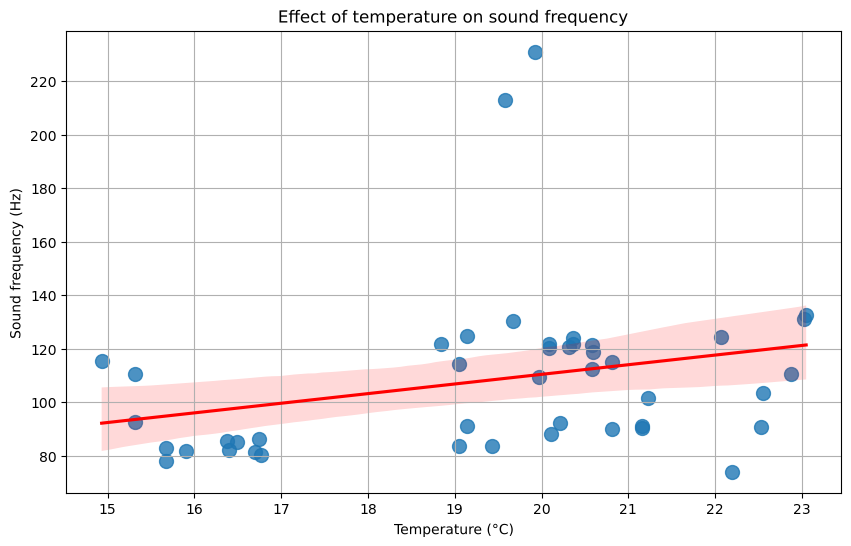

In [ ]:
# plt.figure(figsize=(10, 6))
# sns.regplot(data=df, x="temp_c", y="hz", scatter_kws={"s": 100}, line_kws={"color": "red"})
# plt.title("Effect of temperature on sound frequency")
# plt.xlabel("Temperature (°C)")
# plt.ylabel("Sound frequency (Hz)")
# plt.grid(True)
# plt.savefig("data/plot_temperature_vs_sound.png")
# plt.show()

## Correlation

In [53]:
# temp_column = [c for c in df.columns if "temp" in c][0]
# hz_column = [c for c in df.columns if "hz" in c][0]

In [54]:
# df_clean = df.dropna(subset=[temp_column, hz_column])

In [55]:
# _, p_norm_temp = stats.shapiro(df_clean["temp_c"])
# _, p_norm_hz = stats.shapiro(df_clean["hz"])
# print(
#     f"Temperature p-value: {p_norm_temp:.5f} -> "
#     + ("NORMAL distribution" if p_norm_temp > 0.05 else "Not normally distributed")
# )
# print(
#     f"Frequency Hz p-value: {p_norm_hz:.5f} -> "
#     + ("NORMAL distribution" if p_norm_hz > 0.05 else "Not normally distributed")
# )

In [56]:
# r_spearman, p_spearman = stats.spearmanr(df_clean["temp_c"], df_clean["hz"])

In [57]:
# print(f"Correlation coefficient (r): {r_spearman:.3f}")
# print(f"p-value: {p_spearman:.5f}")

In [58]:
# if p_spearman < 0.05:
#     print(
#         "We reject the null hypothesis: we found a statistically significant "
#         "monotonic relationship between temperature and hz."
#     )
# else:
#     print(
#         "Not enough evidence of a statistically significant "
#         "monotonic relationship between temperature and hz."
#     )

In [59]:
# slope, intercept, r_value, p_value, std_err = stats.linregress(
#     df_clean["temp_c"],
#     df_clean["hz"]
# )

In [60]:
# print(f"Slope: {slope:.2f}")

# Data reduction

In [63]:
#audio_file_names_hive30.sort()

In [62]:
# processed_hours = set()
# output_data = []
# audio_errors = []

# for p in tqdm(audio_file_names_hive30):
#     audio_path = all_audio_hive30 / p
#     digits = re.findall(r"\d+", p)
    
#     if len(digits) >= 6:
#         year, month, day = digits[0], digits[1], digits[2]
#         hour, minute, second = digits[3], digits[4], digits[5]
#         hour_key = f"{year}-{month}-{day}_{hour}"
        
#         if hour_key in processed_hours:
#             continue
            
#         try:
#             y, sr = sf.read(audio_path)

#             if y.ndim > 1:
#                 y = np.mean(y, axis=1)
            
#             if np.max(np.abs(y)) < 0.001:
#                 continue
                
#             f0 = librosa.yin(y=y, fmin=60, fmax=1000, sr=sr)
#             f0_mean = np.nanmean(f0) if not np.all(np.isnan(f0)) else np.nan
#             rms = np.mean(librosa.feature.rms(y=y)[0])
            
#             output_data.append({
#                 "filename": p,
#                 "timestamp_audio": pd.to_datetime(
#                     f"{year}-{month}-{day} {hour}:{minute}:{second}",
#                     errors="coerce"
#                 ),
#                 "hour": int(hour),
#                 "f0_hz": f0_mean,
#                 "rms_loudness": rms
#             })
#             processed_hours.add(hour_key)
            
#         except Exception as error:
#             audio_errors.append({"filename": p, "error": str(error)})

# print(f"Number of errors during audio processing: {len(audio_errors)}")

In [ ]:
# csv_file_path = "data/h_30/cleaned_audio_features_30.csv"
# df_features_hive30 = pd.read_csv(csv_file_path)

In [ ]:
# df_features_hive30["timestamp_audio"] = pd.to_datetime(
#     df_features_hive30["timestamp_audio"],
#     errors="coerce"
# )

# Acoustic rhythm of the hive, right

## Daily rhythm

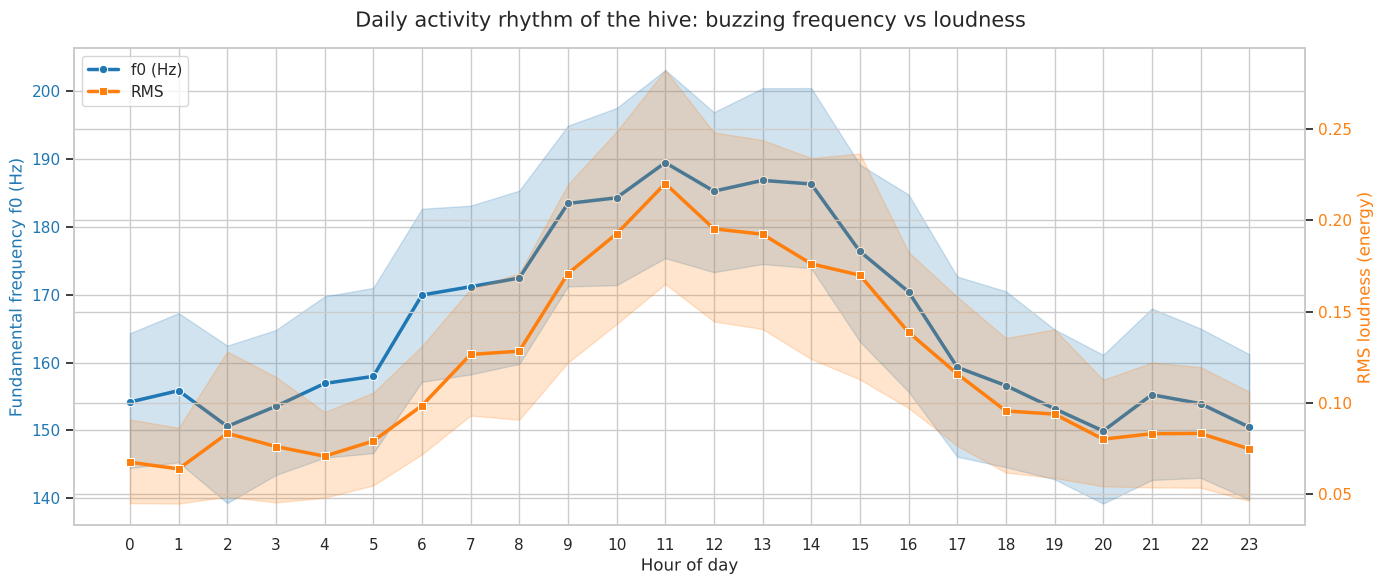

In [ ]:
# sns.set_theme(style="whitegrid")
# fig, ax1 = plt.subplots(figsize=(14, 6))
# color = "#1f77b4"
# ax1.set_xlabel("Hour of day", fontsize=12)
# ax1.set_ylabel("Fundamental frequency f0 (Hz)", color=color, fontsize=12)
# sns.lineplot(data=df_features, x="hour", y="f0_hz", ax=ax1, color=color, marker="o", linewidth=2.5, label="f0 (Hz)", legend=False)
# ax1.tick_params(axis="y", labelcolor=color)
# ax1.set_xticks(range(0, 24))
# ax2 = ax1.twinx()
# color = "#ff7f0e"
# ax2.set_ylabel("RMS loudness (energy)", color=color, fontsize=12)
# sns.lineplot(data=df_features, x="hour", y="rms_loudness", ax=ax2, color=color, marker="s", linewidth=2.5, label="RMS", legend=False)
# ax2.tick_params(axis="y", labelcolor=color)
# lines1, labels1 = ax1.get_legend_handles_labels()
# lines2, labels2 = ax2.get_legend_handles_labels()
# ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=11, frameon=True)
# plt.title("Daily acoustic rhythm of the hive", fontsize=15, pad=15)
# fig.tight_layout()
# plt.show()

## Daily activity from April to June

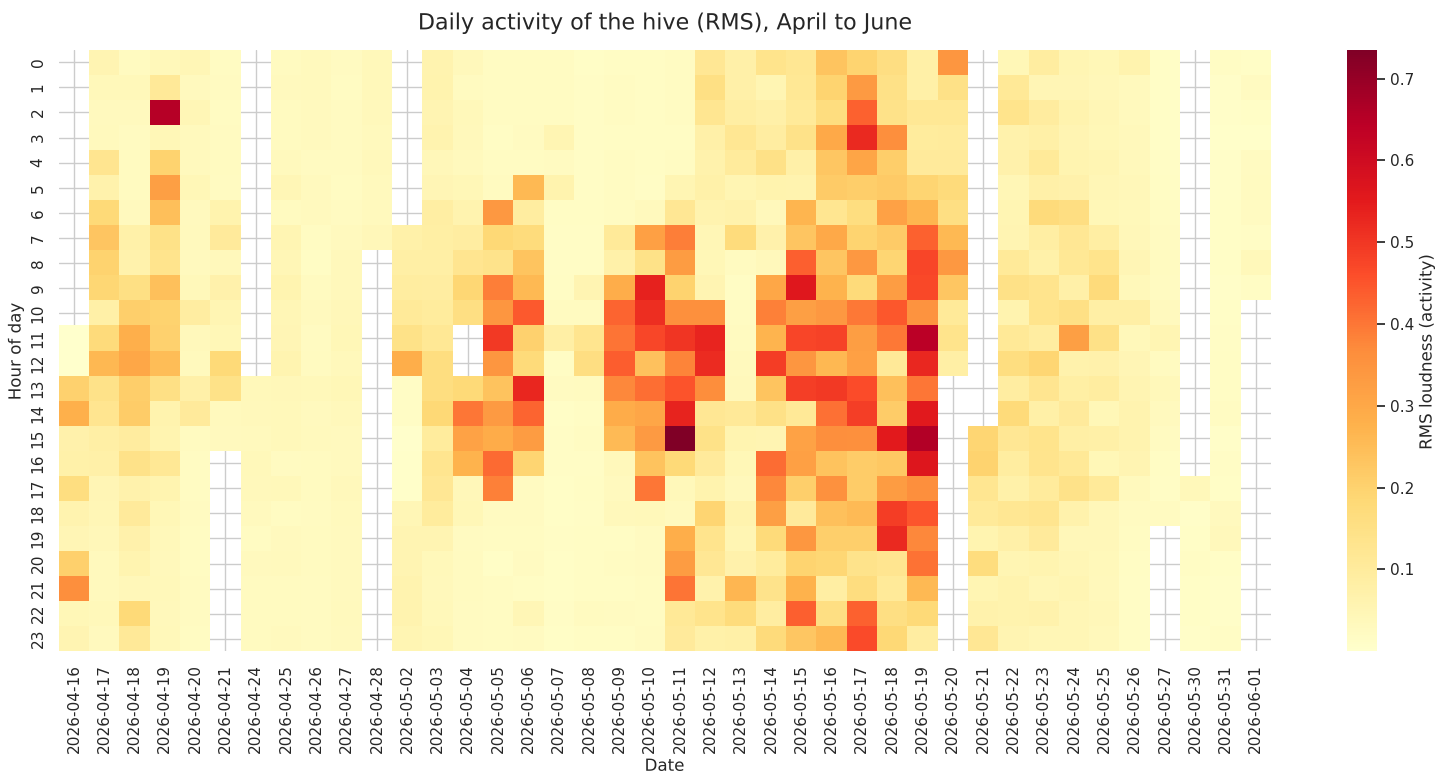

In [ ]:
# df_features["timestamp_audio"] = pd.to_datetime(df_features["timestamp_audio"], errors="coerce")
# df_features["date_str"] = df_features["timestamp_audio"].dt.strftime("%Y-%m-%d")
# pivot_rms = df_features.pivot_table(index="hour", columns="date_str", values="rms_loudness", aggfunc="mean")
# plt.figure(figsize=(16, 8))
# sns.heatmap(pivot_rms, cmap="YlOrRd")
# plt.title("Daily activity of the hive (RMS)")
# plt.tight_layout()
# plt.show()

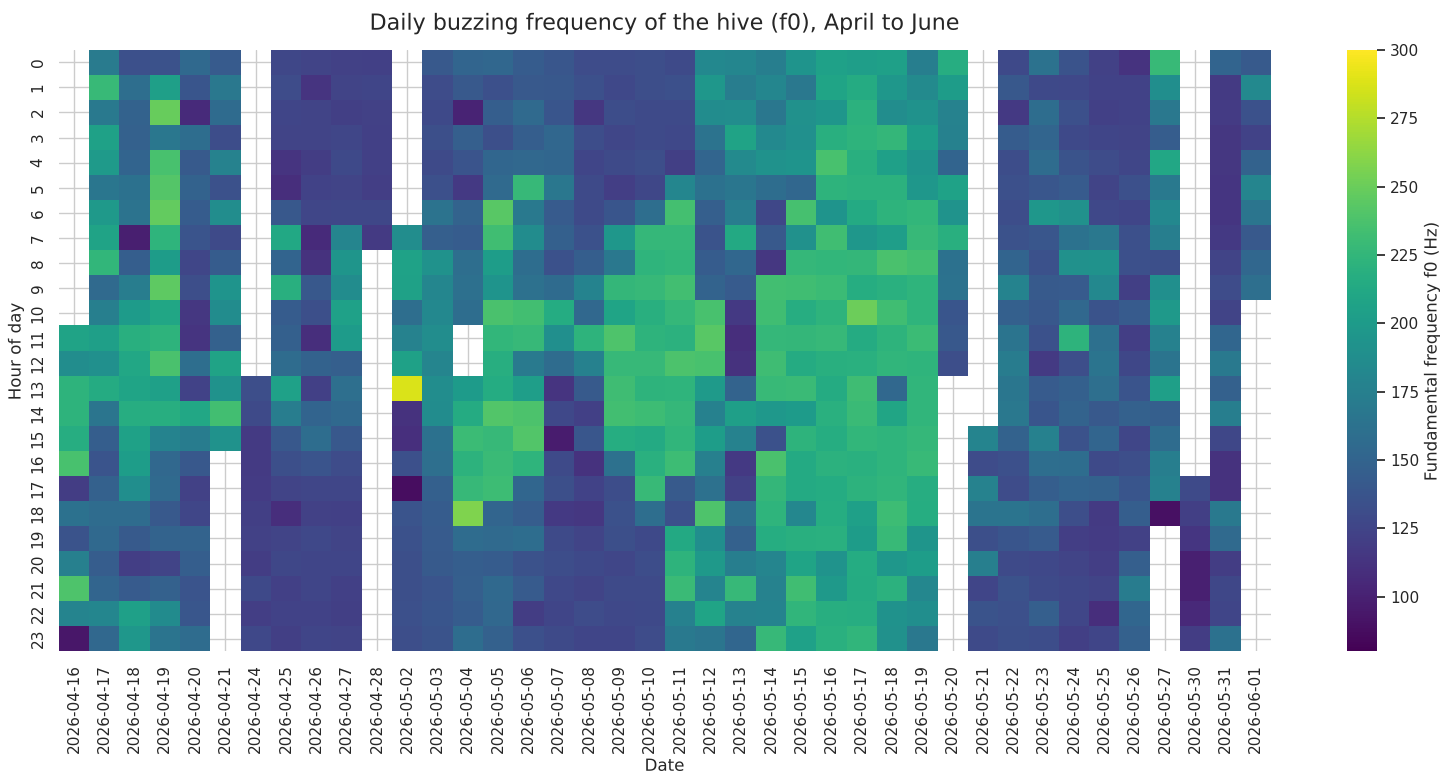

In [ ]:
# pivot_f0 = df_features.pivot_table(index="hour", columns="date_str", values="f0_hz", aggfunc="mean")
# plt.figure(figsize=(16, 8))
# sns.heatmap(pivot_f0, cmap="viridis", vmin=80, vmax=300)
# plt.title("Daily buzzing frequency of the hive")
# plt.tight_layout()
# plt.show()

In optimal conditions the hive works in a clear daily rhythm, visible in the period from 9 to 19 May. During the day, with intensive foraging flights and cooling of the nest, the loudness rises and the frequency stabilises in the green range of about 210–230 Hz. At night the insects go into a resting state, which shows up as a drop in sound energy and a lower pitch, a bass hum in the range of 80–150 Hz. Interestingly, in the phase of the strongest development of the colony in May, the bees kept a slightly higher frequency also at night, which is probably linked to the need for constant heating of the growing brood.

We can point out two anomalies recorded by the microphones. The first one took place on 19 April between 2:00 and 3:00 at night, when the hive showed a sudden, strong jump in loudness together with a rise in frequency from the bass to 220 Hz. Such a signature may be an example of something like a defensive alarm, caused by a sudden external stimulus, for example an attack by a predator or a strong knock on the hive. The anomaly from 2 May at 13:00 is of a completely different character: at a very low overall loudness the frequency shot up to extreme values of 280–300 Hz. Such a high, shrill sound with little energy is typical of the so-called piping of the queen bee, or of a specific, local disturbance in the nest.

In the period from 21 May to the beginning of June, at midday there was a drastic, parallel drop in both loudness and frequency, which fell to the level of purple, that is about 120–150 Hz. Since not only the noise went quiet but the wingbeat rate also dropped drastically, the hypothesis of a short-lived break in the weather can be almost completely excluded. Such a double reduction of the acoustic parameters in the middle of the day is evidence of a serious change in the structure of the hive, most likely caused by a swarm leaving, in which the old queen left the nest together with more than half of the adult workers, leaving the colony in a state of temporary weakness.

# Acoustic rhythm of the hive, 30

## Daily rhythm

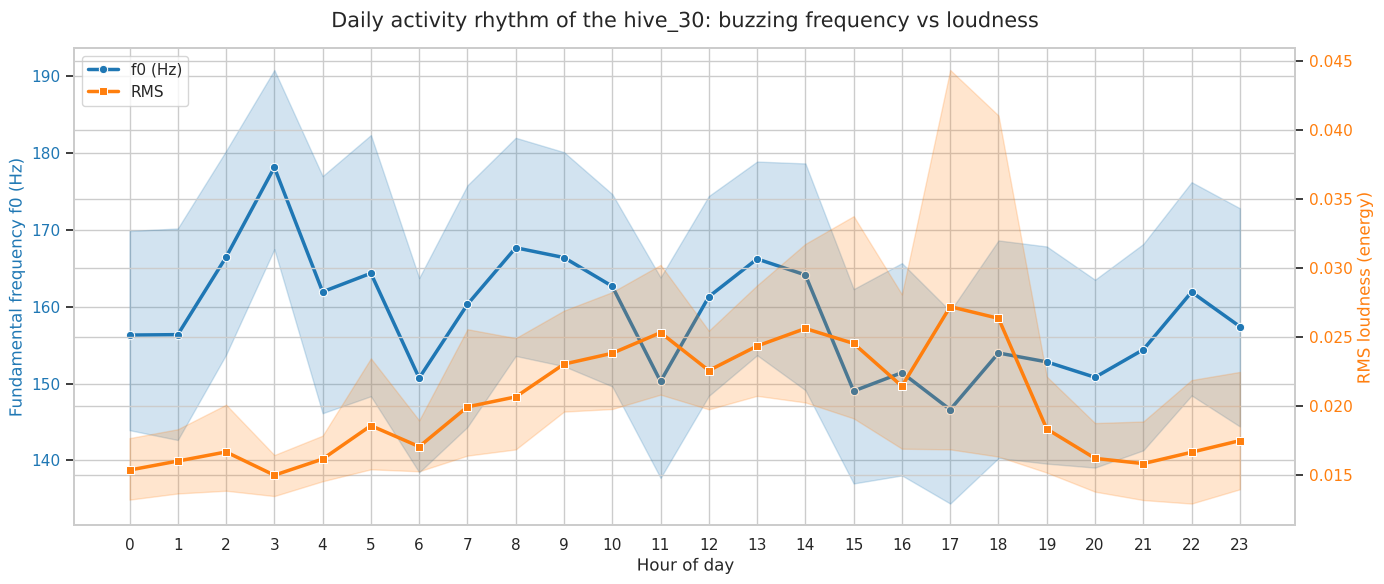

In [ ]:
# sns.set_theme(style="whitegrid")
# fig, ax1 = plt.subplots(figsize=(14, 6))
# color = "#1f77b4"
# ax1.set_xlabel("Hour of day", fontsize=12)
# ax1.set_ylabel("Fundamental frequency f0 (Hz)", color=color, fontsize=12)
# sns.lineplot(data=df_features_hive30, x="hour", y="f0_hz", ax=ax1, color=color, marker="o", linewidth=2.5, label="f0 (Hz)", legend=False)
# ax1.tick_params(axis="y", labelcolor=color)
# ax1.set_xticks(range(0, 24))
# ax2 = ax1.twinx()
# color = "#ff7f0e"
# ax2.set_ylabel("RMS loudness (energy)", color=color, fontsize=12)
# sns.lineplot(data=df_features_hive30, x="hour", y="rms_loudness", ax=ax2, color=color, marker="s", linewidth=2.5, label="RMS", legend=False)
# ax2.tick_params(axis="y", labelcolor=color)
# plt.title("Daily acoustic rhythm of hive 30", fontsize=15, pad=15)
# fig.tight_layout()
# plt.show()

## Daily activity from March to June

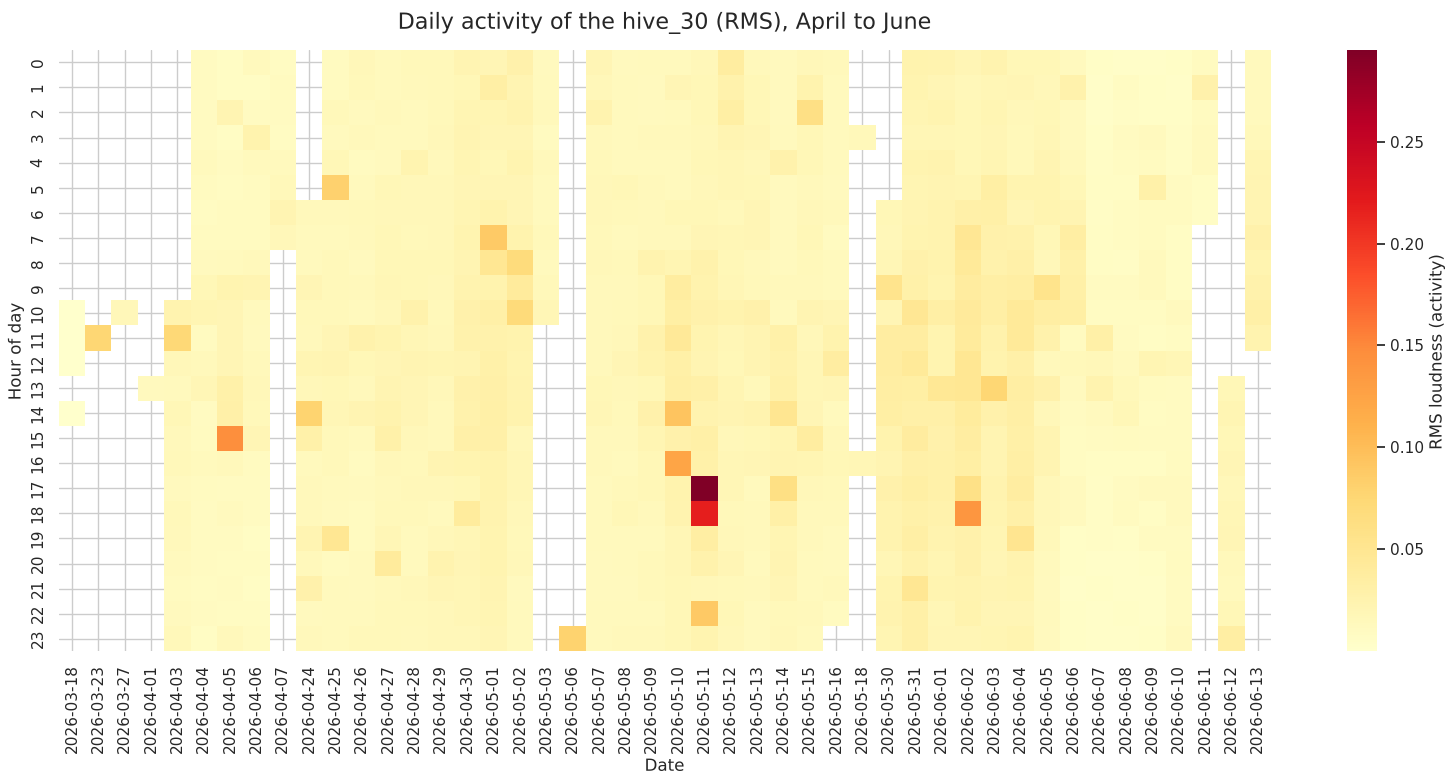

In [ ]:
# df_features_hive30["timestamp_audio"] = pd.to_datetime(df_features_hive30["timestamp_audio"], errors="coerce")
# df_features_hive30["date_str"] = df_features_hive30["timestamp_audio"].dt.strftime("%Y-%m-%d")
# pivot_rms = df_features_hive30.pivot_table(index="hour", columns="date_str", values="rms_loudness", aggfunc="mean")
# plt.figure(figsize=(16, 8))
# sns.heatmap(pivot_rms, cmap="YlOrRd")
# plt.title("Daily activity of hive 30 (RMS)")
# plt.tight_layout()
# plt.show()

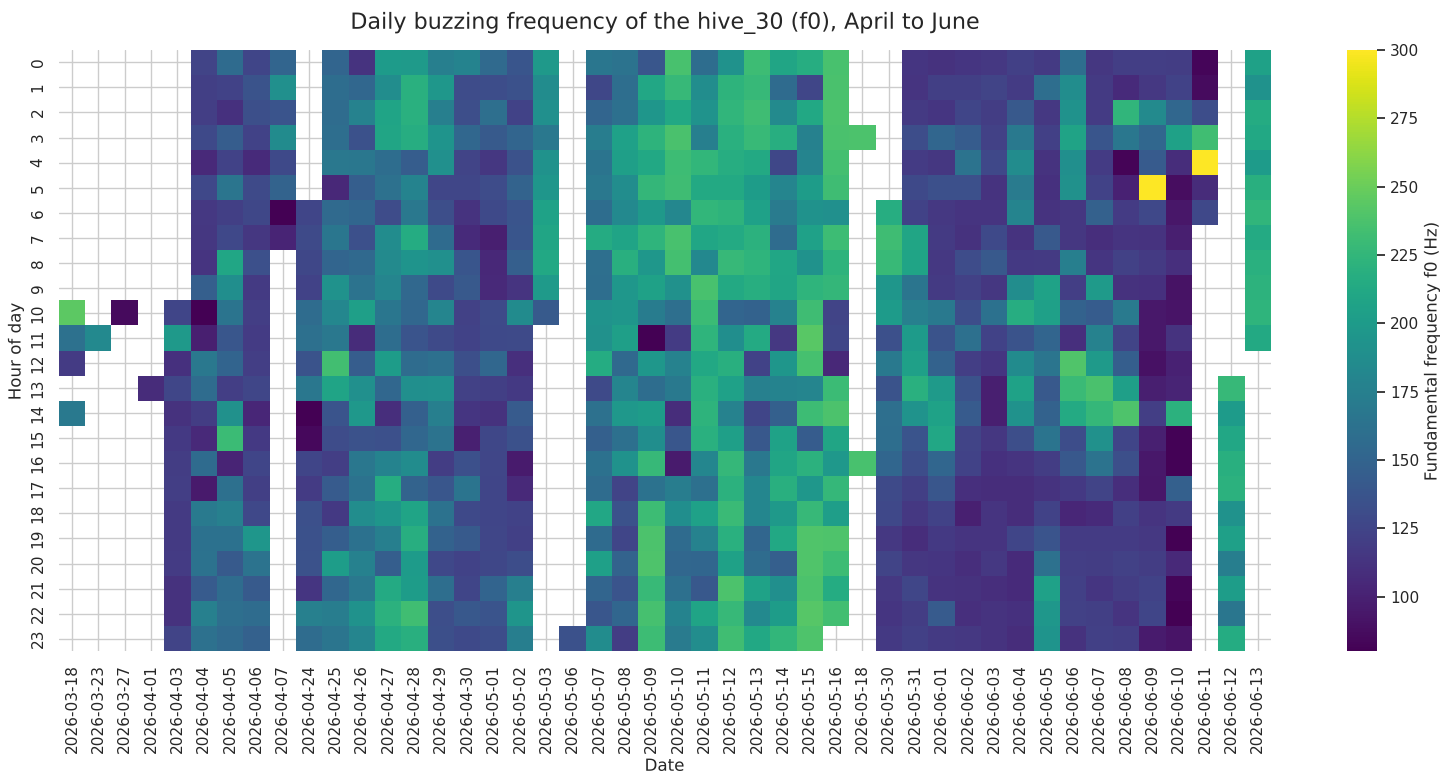

In [ ]:
# pivot_f0 = df_features_hive30.pivot_table(index="hour", columns="date_str", values="f0_hz", aggfunc="mean")
# plt.figure(figsize=(16, 8))
# sns.heatmap(pivot_f0, cmap="viridis", vmin=80, vmax=300)
# plt.title("Daily buzzing frequency of hive 30")
# plt.tight_layout()
# plt.show()

# MFCC, hive right

In [ ]:
# n_mfcc = 13
# mfcc_columns = [f"mfcc_{i}" for i in range(1, n_mfcc + 1)]
# mfcc_errors = []
# for col in mfcc_columns:
#     df_features[col] = np.nan
# for idx, row in tqdm(df_features.iterrows(), total=len(df_features)):
#     audio_file_path = all_audio / row["filename"]
#     try:
#         y, sr = sf.read(audio_file_path)
#         if y.ndim > 1:
#             y = np.mean(y, axis=1)
#         if y.size == 0 or np.max(np.abs(y)) < 0.001:
#             continue
#         mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
#         for i, value in enumerate(np.mean(mfccs, axis=1)):
#             df_features.at[idx, f"mfcc_{i + 1}"] = value
#     except Exception as error:
#         mfcc_errors.append({"filename": row["filename"], "error": str(error)})
# print(f"Number of MFCC extraction errors: {len(mfcc_errors)}")
# df_features.to_csv("data/audio_features_with_mfcc.csv", index=False)

100%|██████████| 841/841 [01:00<00:00, 13.79it/s]


## State detection, hive right

In [ ]:
# csv_path = "data/audio_features_with_mfcc.csv"
# df = pd.read_csv(csv_path)

In [ ]:
# df_clean = df.copy()

In [ ]:
# clustering_features = [
#     "rms_loudness",
#     "f0_hz",
#     *[f"mfcc_{i}" for i in range(1, 14)]
# ]
# df_clean = df.dropna(subset=clustering_features).copy()
# X = df_clean[clustering_features]

In [ ]:
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

In [ ]:
# kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
# df_clean["cluster"] = kmeans.fit_predict(X_scaled)

In [ ]:
# df_clean["Cluster name"] = df_clean["cluster"].apply(
#     lambda x: f"Group {x}"
# )

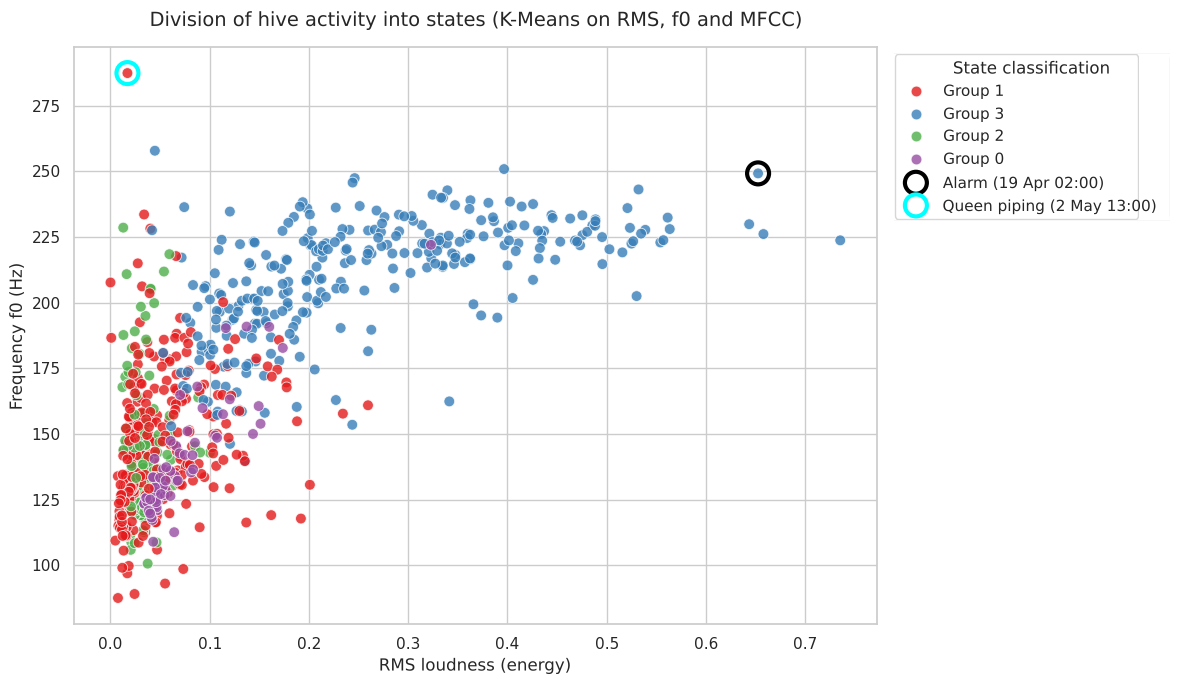

In [ ]:
# plt.figure(figsize=(12, 7))
# sns.set_theme(style="whitegrid")
# sns.scatterplot(
#     data=df_clean, x="rms_loudness", y="f0_hz",
#     hue="Cluster name", palette="Set1", alpha=0.8, s=60
# )
# plt.title("Division of hive activity into states", fontsize=14, pad=15)
# plt.xlabel("RMS loudness (energy)")
# plt.ylabel("Frequency f0 (Hz)")
# plt.legend(title="State classification", bbox_to_anchor=(1.05, 1), loc="upper left")
# plt.tight_layout()
# plt.show()

In [21]:
cluster_colors = {
    'Group 0': '#9467bd',  # Fioletowy
    'Group 1': '#d62728',  # Czerwony
    'Group 2': '#2ca02c',  # Zielony
    'Group 3': '#1f77b4'   # Niebieski
}

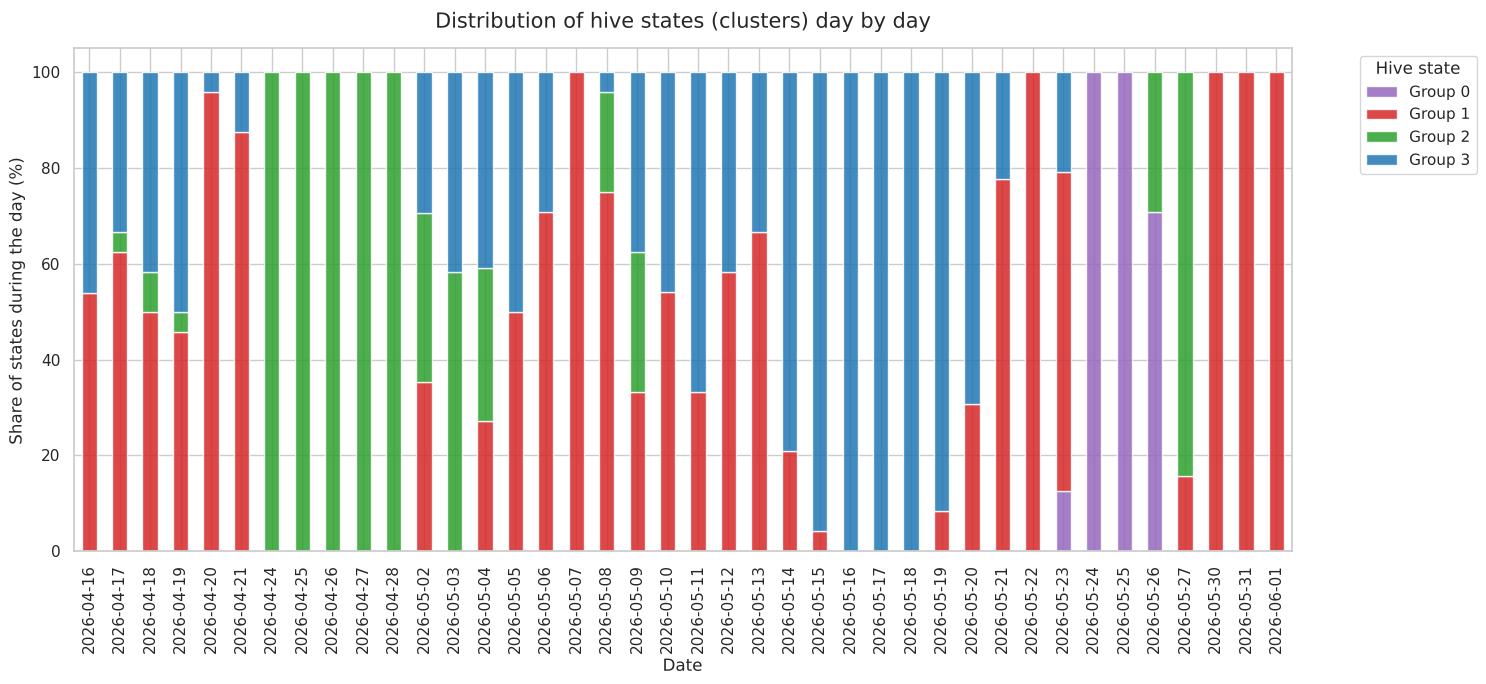

In [ ]:
# df_clean["date_str"] = df_clean["timestamp_audio"].dt.strftime("%Y-%m-%d")
# day_distribution = pd.crosstab(
#     df_clean["date_str"], df_clean["Cluster name"], normalize="index"
# ) * 100
# group_order = ["Group 0", "Group 1", "Group 2", "Group 3"]
# day_distribution = day_distribution.reindex(columns=group_order)
# color_list = [cluster_colors[group] for group in day_distribution.columns]
# day_distribution.plot(kind="bar", stacked=True, figsize=(15, 7), color=color_list, alpha=0.85)
# plt.title("Distribution of hive states day by day", fontsize=15, pad=15)
# plt.xlabel("Date")
# plt.ylabel("Share of states (%)")
# plt.legend(title="Hive state", bbox_to_anchor=(1.05, 1), loc="upper left")
# plt.tight_layout()
# plt.show()

# MFCC, hive 30

In [ ]:
# n_mfcc = 13
# mfcc_columns = [f"mfcc_{i}" for i in range(1, n_mfcc + 1)]
# mfcc_errors_30 = []
# for col in mfcc_columns:
#     df_features_hive30[col] = np.nan
# for idx, row in tqdm(df_features_hive30.iterrows(), total=len(df_features_hive30)):
#     audio_file_path = all_audio_hive30 / row["filename"]
#     try:
#         y, sr = sf.read(audio_file_path)
#         if y.ndim > 1:
#             y = np.mean(y, axis=1)
#         if y.size == 0 or np.max(np.abs(y)) < 0.001:
#             continue
#         mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
#         for i, value in enumerate(np.mean(mfccs, axis=1)):
#             df_features_hive30.at[idx, f"mfcc_{i + 1}"] = value
#     except Exception as error:
#         mfcc_errors_30.append({"filename": row["filename"], "error": str(error)})
# print(f"Number of MFCC extraction errors for hive 30: {len(mfcc_errors_30)}")
# df_features_hive30.to_csv("data/h_30/audio_features_with_mfcc.csv", index=False)

100%|██████████| 876/876 [00:16<00:00, 52.18it/s]


## State detection, hive 30

In [ ]:
# csv_path_hive30 = "data/h_30/audio_features_with_mfcc.csv"
# df = pd.read_csv(csv_path_hive30)

In [ ]:
# clustering_features_30 = [
#     "rms_loudness",
#     "f0_hz",
#     *[f"mfcc_{i}" for i in range(1, 14)]
# ]
# df_clean_30 = df.dropna(subset=clustering_features_30).copy()
# X_30 = df_clean_30[clustering_features_30]
# scaler = StandardScaler()
# X_scaled_30 = scaler.fit_transform(X_30)
# kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
# df_clean_30["cluster"] = kmeans.fit_predict(X_scaled_30)
# df_clean_30["Cluster name"] = df_clean_30["cluster"].apply(lambda x: f"Group {x}")

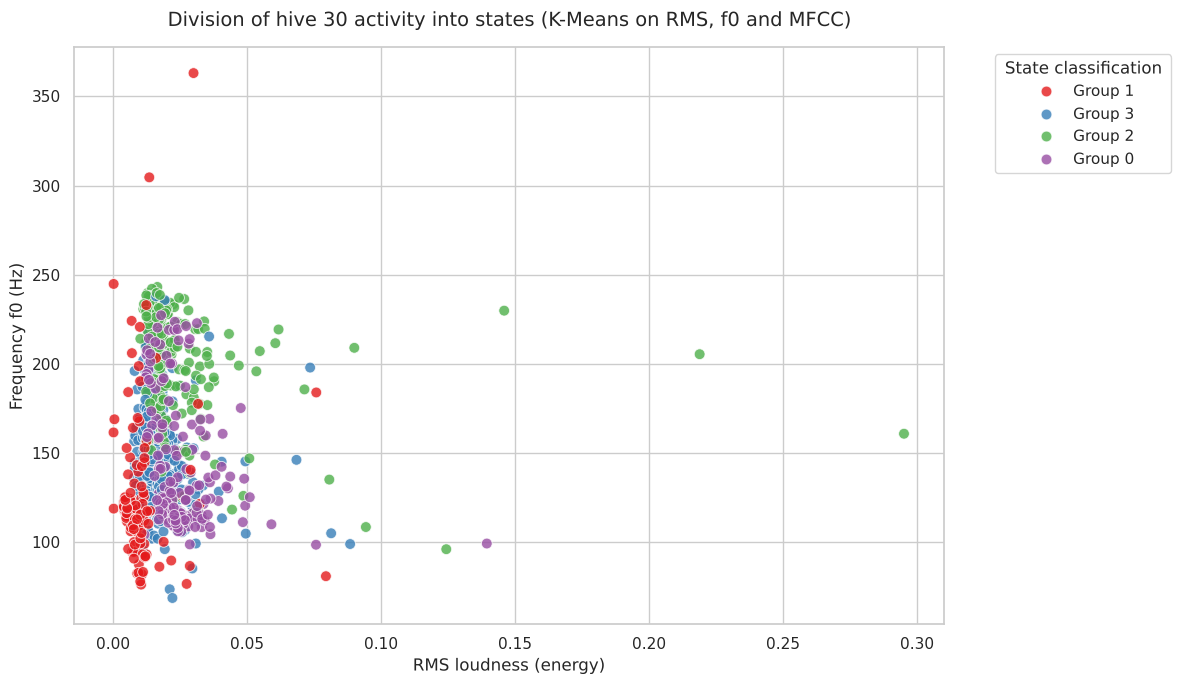

In [ ]:
# plt.figure(figsize=(12, 7))
# sns.set_theme(style="whitegrid")
# sns.scatterplot(data=df_clean_30, x="rms_loudness", y="f0_hz", hue="Cluster name", palette="Set1", alpha=0.8, s=60)
# plt.title("Division of hive 30 activity into states", fontsize=14, pad=15)
# plt.xlabel("RMS loudness (energy)")
# plt.ylabel("Frequency f0 (Hz)")
# plt.legend(title="State classification", bbox_to_anchor=(1.05, 1), loc="upper left")
# plt.tight_layout()
# plt.show()

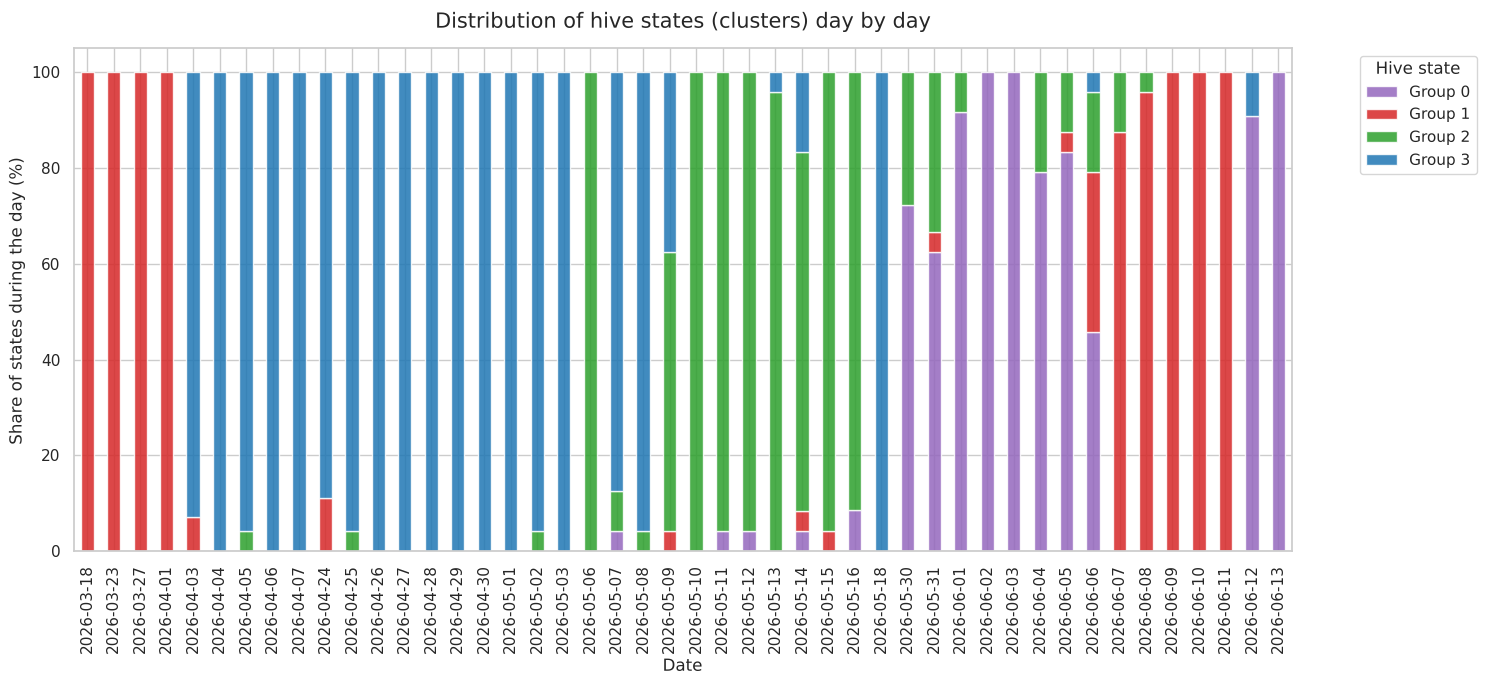

In [ ]:
# df_clean_30["date_str"] = df_clean_30["timestamp_audio"].dt.strftime("%Y-%m-%d")
# day_distribution_30 = pd.crosstab(df_clean_30["date_str"], df_clean_30["Cluster name"], normalize="index") * 100
# group_order_30 = ["Group 0", "Group 1", "Group 2", "Group 3"]
# day_distribution_30 = day_distribution_30.reindex(columns=group_order_30)
# color_list = [cluster_colors[group] for group in day_distribution_30.columns]
# day_distribution_30.plot(kind="bar", stacked=True, figsize=(15, 7), color=color_list, alpha=0.85)
# plt.title("Distribution of hive 30 states day by day", fontsize=15, pad=15)
# plt.xlabel("Date")
# plt.ylabel("Share of states (%)")
# plt.legend(title="Hive state", bbox_to_anchor=(1.05, 1), loc="upper left")
# plt.tight_layout()
# plt.show()

# ---------------------------------------------------------------------------

# Selecting usable recordings

In [76]:
sound_df = pd.read_excel("data/Sensor_Sound_Analysis.xlsx")

In [77]:
print(sound_df.shape)
display(sound_df.head())
display(sound_df.columns)

(734194, 14)


,File (S3 key),Device,Apiary,Hive,Date,Time (UTC),Sound RMS (dBFS),Leading freq 0-250Hz (Hz),Leading peak magnitude,Peak dBFS,Band energy 100-300Hz (dB),Duration s,Silent,All dominant peaks Hz (mag desc)
0,sensor_other_01/2026-03-10/2026-03-10_10-0...,sensor_other_01,NaN,NaN,2026-03-10,10:04:00,-79.922664,90.0,53.647099,-38.053324,48.480178,15.360,0.0,90; 237; 123; 207; 120
1,sensor_other_01/2026-03-10/2026-03-10_10-0...,sensor_other_01,NaN,NaN,2026-03-10,10:05:00,-88.761980,82.0,56.392919,-41.490854,46.868890,59.904,0.0,82; 77; 85; 80; 87
2,sensor_other_01/2026-03-10/2026-03-10_10-0...,sensor_other_01,NaN,NaN,2026-03-10,10:06:00,-88.048047,151.0,56.252379,-46.558560,49.591403,59.904,0.0,151; 181; 250; 201; 961
3,sensor_other_01/2026-03-10/2026-03-10_10-0...,sensor_other_01,NaN,NaN,2026-03-10,10:07:00,-90.452578,238.0,50.306409,-47.081618,45.644995,59.904,0.0,288; 238; 230; 602; 234
4,sensor_other_01/2026-03-10/2026-03-10_10-0...,sensor_other_01,NaN,NaN,2026-03-10,10:08:00,-100.872668,84.0,45.934453,-59.182947,36.298044,59.904,0.0,84; 97; 88; 101; 93


Index(['File (S3 key)', 'Device', 'Apiary', 'Hive', 'Date', 'Time (UTC)',
       'Sound RMS (dBFS)', 'Leading freq 0-250Hz (Hz)',
       'Leading peak magnitude', 'Peak dBFS', 'Band energy 100-300Hz (dB)',
       'Duration s', 'Silent', 'All dominant peaks Hz (mag desc)'],
      dtype='object')

In [78]:
df = sound_df.copy()

df.columns = df.columns.str.strip()

print(df.columns.tolist())

['File (S3 key)', 'Device', 'Apiary', 'Hive', 'Date', 'Time (UTC)', 'Sound RMS (dBFS)', 'Leading freq 0-250Hz (Hz)', 'Leading peak magnitude', 'Peak dBFS', 'Band energy 100-300Hz (dB)', 'Duration s', 'Silent', 'All dominant peaks Hz (mag desc)']


## Split by device

In [79]:
print(df["Device"].unique())

['sensor_other_01' 'sensor_right' 'sensor_other_02'
 'sensor_23' 'sensor_selftest' 'sensor_25'
 'sensor_other_03' 'sensor_central' 'sensor_other_04'
 'sensor_28' 'sensor_30' 'sensor_other_05'
 'sensor_other_06' 'sensor_other_07' 'sensor_26'
 'sensor_27' 'sensor_21' 'sensor_other_08'
 'sensor_other_09' 'sensor_29' 'sensor_other_10'
 'sensor_other_10']


Apiary A:
21 - sensor_21, 
22 - none, 
23 - sensor_23, 
24 - no such hive, 
25 - sensor_25, 
26 - sensor_26, 
27 - sensor_27, 
28 - sensor_28, 
29 - sensor_29, 
30 - sensor_30

Apiary B:
Central - sensor_central,
Left - sensor_left, 
Right - sensor_right

In [80]:
device_to_hive = {
    # Apiary A
    "sensor_21": "21",
    "sensor_23": "23",
    "sensor_25": "25",
    "sensor_26": "26",
    "sensor_27": "27",
    "sensor_28": "28",
    "sensor_29": "29",
    "sensor_30": "30",

    # Apiary B
    "sensor_central": "Central",
    "sensor_left": "Left",
    "sensor_right": "Right"
}

device_to_apiary = {
    "sensor_21": "Apiary A",
    "sensor_23": "Apiary A",
    "sensor_25": "Apiary A",
    "sensor_26": "Apiary A",
    "sensor_27": "Apiary A",
    "sensor_28": "Apiary A",
    "sensor_29": "Apiary A",
    "sensor_30": "Apiary A",

    "sensor_central": "Apiary B",
    "sensor_left": "Apiary B",
    "sensor_right": "Apiary B"
}


In [81]:
available_devices = {
    "sensor_21",   # 21
    "sensor_23",   # 23
    "sensor_25",   # 25
    "sensor_26",   # 26
    "sensor_27",   # 27
    "sensor_28",   # 28
    "sensor_29",   # 29
    "sensor_30",   # 30
    "sensor_central",   # Central
    "sensor_left",   # Left
    "sensor_right"    # Right
}

df = df[df["Device"].isin(available_devices)].copy()

print(f"Number of recordings after filtering: {len(df):,}")
print(df["Device"].value_counts())

Number of recordings after filtering: 439,726
Device
sensor_26    91549
sensor_27    81724
sensor_23    78147
sensor_21    57903
sensor_30    51401
sensor_25    38717
sensor_29    22238
sensor_28    17958
sensor_right       84
sensor_central        5
Name: count, dtype: int64


In [82]:
df["Hive"] = df["Device"].map(device_to_hive)
df["Apiary"] = df["Device"].map(device_to_apiary)

## Statistics

In [83]:
display(df[[
    "Sound RMS (dBFS)",
    "Peak dBFS",
    "Leading freq 0-250Hz (Hz)",
    "Band energy 100-300Hz (dB)",
    "Duration s"
]].describe(percentiles=[0.01,0.05,0.25,0.5,0.75,0.95,0.99]))

,Sound RMS (dBFS),Peak dBFS,Leading freq 0-250Hz (Hz),Band energy 100-300Hz (dB),Duration s
count,439726.000000,439726.000000,432686.000000,439726.000000,439726.000000
mean,-32.168266,-14.737557,163.829209,110.136364,31.828719
std,5.937736,6.520093,61.584929,6.656898,11.750449
min,-105.654573,-100.000000,7.000000,-100.000000,1.536000
1%,-47.998654,-32.182248,54.000000,92.303443,6.144000
5%,-41.879961,-25.343903,67.000000,98.056080,16.128000
25%,-35.316648,-18.341019,113.000000,106.852662,23.808000
50%,-31.499551,-14.507500,155.000000,111.174056,29.952000
75%,-28.328125,-10.983445,224.000000,114.561603,38.400000
95%,-24.448016,-3.864304,245.000000,118.484559,59.904000


## Suspicious recordings

In [84]:
df["reason"] = ""

df.loc[df["Silent"] == 1, "reason"] += "silent; "

df.loc[
    df["Sound RMS (dBFS)"] < df["Sound RMS (dBFS)"].quantile(0.01),
    "reason"
] += "very_low_rms; "

df.loc[df["Peak dBFS"] > -3, "reason"] += "possible_clipping; "
df.loc[df["Duration s"] < 30, "reason"] += "short_recording; "
df.loc[
    df["Leading freq 0-250Hz (Hz)"].isna()
    | (df["Leading freq 0-250Hz (Hz)"] == 0),
    "reason"
] += "no_leading_freq; "

In [85]:
df["selected"] = True

# Silence
df.loc[df["Silent"] == 1, "selected"] = False

# No frequency
df.loc[
    df["Leading freq 0-250Hz (Hz)"].isna()
    | (df["Leading freq 0-250Hz (Hz)"] == 0),
    "selected"
] = False

# Very short recordings (<10 s)
df.loc[df["Duration s"] < 10, "selected"] = False

# RMS practically silence
df.loc[df["Sound RMS (dBFS)"] < -90, "selected"] = False

In [86]:
print(f"Number of all recordings: {len(df)}")
print(f"Selected: {df['selected'].sum()}")
print(f"Rejected: {(~df['selected']).sum()}")

Number of all recordings: 439726
Selected: 426821
Rejected: 12905


In [87]:
df.groupby("Device").agg(
    recordings=("Device", "size"),
    mean_rms=("Sound RMS (dBFS)", "mean"),
    mean_band=("Band energy 100-300Hz (dB)", "mean"),
    mean_peak=("Peak dBFS", "mean")
).sort_values("recordings", ascending=False)

,recordings,mean_rms,mean_band,mean_peak
Device,,,,
sensor_26,91549,-30.723527,111.769128,-13.651664
sensor_27,81724,-36.627007,105.304714,-19.550118
sensor_23,78147,-32.578115,109.509059,-14.724862
sensor_21,57903,-28.303452,114.468915,-12.249172
sensor_30,51401,-35.029390,107.065454,-14.501473
sensor_25,38717,-29.013052,113.476190,-12.784277
sensor_29,22238,-32.575565,109.721760,-15.417717
sensor_28,17958,-27.723798,115.007633,-10.259222
sensor_right,84,-94.821747,39.479895,-63.971370


In [88]:
df.head()

,File (S3 key),Device,Apiary,Hive,Date,Time (UTC),Sound RMS (dBFS),Leading freq 0-250Hz (Hz),Leading peak magnitude,Peak dBFS,Band energy 100-300Hz (dB),Duration s,Silent,All dominant peaks Hz (mag desc),reason,selected
40278,sensor_right/1970-01-01/1970-01-01_00-0...,sensor_right,Apiary B,Right,1970-01-01,00:00:00,-102.022656,88.0,33.763635,-73.408599,29.996495,16.896,0.0,88; 49; 149; 111; 7927,very_low_rms; short_recording;,False
40279,sensor_right/1970-01-01/1970-01-01_00-0...,sensor_right,Apiary B,Right,1970-01-01,00:01:00,-100.748475,NaN,NaN,-70.310795,31.034122,16.896,0.0,5661; 5132; 5655; 5210; 5127,very_low_rms; short_recording; no_leading_freq;,False
40280,sensor_right/2026-07-20/2026-07-20_07-0...,sensor_right,Apiary B,Right,2026-07-20,07:05:00,-98.728220,NaN,NaN,-53.658678,30.957710,49.152,0.0,7895; 7803; 7890; 7808; 7791,very_low_rms; no_leading_freq;,False
40281,sensor_right/2026-07-20/2026-07-20_07-0...,sensor_right,Apiary B,Right,2026-07-20,07:06:00,-93.945285,103.0,42.534352,-52.807915,35.452452,59.904,0.0,103; 98; 145; 6242; 303,very_low_rms;,False
40282,sensor_right/2026-07-20/2026-07-20_07-0...,sensor_right,Apiary B,Right,2026-07-20,07:07:00,-88.164535,14.0,56.398161,-47.963548,47.838450,59.904,0.0,899; 14; 1163; 722; 1168,very_low_rms;,True


## Recording quality for each hive

In [89]:
df = df.drop(columns=["selected"], errors="ignore")

In [90]:
bad = (
    (df["Silent"] == 1)
    | (df["Duration s"] < 10)
    | (df["Sound RMS (dBFS)"] < -90)
    | (df["Leading freq 0-250Hz (Hz)"].isna())
    | (df["Leading freq 0-250Hz (Hz)"] == 0)
)

df["selected"] = ~bad

In [91]:
print(df["selected"].value_counts())

selected
True     426821
False     12905
Name: count, dtype: int64


In [92]:
summary = (
    df.groupby(["Apiary", "Hive"])
      .agg(
          recordings=("Device", "size"),
          selected=("selected", "sum"),
          mean_rms=("Sound RMS (dBFS)", "mean"),
          std_rms=("Sound RMS (dBFS)", "std"),
          mean_band=("Band energy 100-300Hz (dB)", "mean"),
      )
)

summary["rejected"] = summary["recordings"] - summary["selected"]
summary["rejected_%"] = (
    100 * summary["rejected"] / summary["recordings"]
).round(2)

display(summary)

recordings  selected   mean_rms   std_rms   mean_band  \
Apiary      Hive                                                             
 Apiary A     21            57903     56677 -28.303452  3.464028  114.468915   
            23            78147     75796 -32.578115  5.368574  109.509059   
            25            38717     37853 -29.013052  6.272372  113.476190   
            26            91549     88583 -30.723527  5.288168  111.769128   
            27            81724     78613 -36.627007  5.174629  105.304714   
            28            17958     16609 -27.723798  4.307916  115.007633   
            29            22238     21727 -32.575565  4.632559  109.721760   
            30            51401     50939 -35.029390  4.966191  107.065454   
 Apiary B Central           5         3 -76.801521  7.518877   61.070791   
            Right            84        21 -94.821747  9.866359   39.479895   

                     rejected  rejected_%  
Apiary      Hive                           
 Apiary A     21           1226        2.12  
            23           2351        3.01  
            25            864        2.23  
            26           2966        3.24  
            27           3111        3.81  
            28           1349        7.51  
            29            511        2.30  
            30            462        0.90  
 Apiary B Central         2       40.00  
            Right          63       75.00

In [93]:
reason_summary = (
    df.assign(
        very_low_rms=df["Sound RMS (dBFS)"] < -90,
        short=df["Duration s"] < 10,
        no_freq=(
            df["Leading freq 0-250Hz (Hz)"].isna()
            | (df["Leading freq 0-250Hz (Hz)"] == 0)
        ),
        silent=df["Silent"] == 1
    )
    .groupby(["Apiary", "Hive"])
    .agg(
        recordings=("Device", "size"),
        very_low_rms=("very_low_rms", "sum"),
        short=("short", "sum"),
        no_freq=("no_freq", "sum"),
        silent=("silent", "sum"),
    )
)

display(reason_summary)

recordings  very_low_rms  short  no_freq  silent
Apiary      Hive                                                     
 Apiary A     21            57903             0    278      951       0
            23            78147             0    134     2221       0
            25            38717             0    103      763       0
            26            91549            12   2076      890       0
            27            81724            16   2225      888       1
            28            17958            13    388      950       0
            29            22238            12    481       18       0
            30            51401            19    105      341       0
 Apiary B Central           5             0      1        1       0
            Right            84            55      1       17       0

## Distribution of features for each hive

In [94]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[df["Apiary"] == "Apiary A"],
    x="Hive",
    y="Sound RMS (dBFS)",
    showfliers=False
)

plt.title("Sound RMS for hives from apiary A")
plt.show()

In [95]:
def describe_feature(df, feature):
    return (
        df[df["selected"]]
        .groupby(["Apiary", "Hive"])[feature]
        .describe(percentiles=[0.25, 0.5, 0.75])
        [["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
        .round(2)
    )

In [96]:
display(describe_feature(df, "Sound RMS (dBFS)"))
display(describe_feature(df, "Peak dBFS"))
display(describe_feature(df, "Leading freq 0-250Hz (Hz)"))
display(describe_feature(df, "Band energy 100-300Hz (dB)"))

count   mean   std    min    25%    50%    75%    max
Apiary      Hive                                                            
 Apiary A     21       56677.0 -28.31  3.46 -77.53 -30.16 -28.05 -26.30  -3.03
            23       75796.0 -32.67  5.11 -79.23 -34.57 -32.19 -29.55  -5.51
            25       37853.0 -29.05  6.29 -83.64 -29.94 -27.76 -25.37  -3.37
            26       88583.0 -30.72  5.26 -89.84 -32.27 -30.06 -28.10  -2.88
            27       78613.0 -36.50  4.95 -89.95 -39.54 -36.14 -33.61  -3.98
            28       16609.0 -27.64  3.92 -89.54 -29.51 -27.88 -25.99  -4.49
            29       21727.0 -32.46  4.01 -89.03 -34.24 -32.78 -30.87  -4.95
            30       50939.0 -35.01  4.79 -89.50 -37.40 -35.03 -32.35  -2.67
 Apiary B Central      3.0 -81.11  5.30 -87.22 -82.82 -78.42 -78.06 -77.70
            Right       21.0 -85.19  2.52 -89.07 -87.29 -85.16 -82.99 -80.24

count   mean   std    min    25%    50%    75%    max
Apiary      Hive                                                            
 Apiary A     21       56677.0 -12.25  4.33 -59.18 -14.89 -12.51  -9.96   0.13
            23       75796.0 -14.82  6.28 -49.25 -18.25 -15.04 -11.46   0.04
            25       37853.0 -12.84  6.13 -59.18 -14.97 -12.37  -9.87   0.23
            26       88583.0 -13.58  5.44 -66.23 -16.46 -13.93 -10.97   0.38
            27       78613.0 -19.42  6.09 -68.03 -23.17 -19.99 -16.50   0.06
            28       16609.0 -10.11  4.07 -66.23 -12.30 -10.59  -8.33   0.03
            29       21727.0 -15.27  4.82 -67.38 -18.10 -15.77 -12.88   0.02
            30       50939.0 -14.50  7.21 -65.70 -19.25 -14.54  -9.80   0.11
 Apiary B Central      3.0 -38.52  6.51 -45.11 -41.73 -38.36 -35.23 -32.10
            Right       21.0 -53.41  9.38 -66.22 -61.37 -54.60 -47.96 -29.88

count    mean    std    min    25%    50%    75%    max
Apiary      Hive                                                              
 Apiary A     21       56677.0  165.30  58.52   21.0  111.0  169.0  217.0  250.0
            23       75796.0  179.72  62.12   20.0  124.0  211.0  232.0  250.0
            25       37853.0  170.75  63.29   28.0  116.0  163.0  235.0  250.0
            26       88583.0  168.45  60.94   14.0  112.0  196.0  225.0  250.0
            27       78613.0  133.71  49.37   11.0  104.0  126.0  160.0  250.0
            28       16609.0  167.63  60.35   14.0  118.0  136.0  236.0  250.0
            29       21727.0  138.76  48.59   13.0  111.0  123.0  182.0  250.0
            30       50939.0  181.47  66.24    7.0  114.0  218.0  236.0  250.0
 Apiary B Central      3.0  120.67  24.01  100.0  107.5  115.0  131.0  147.0
            Right       21.0  159.62  82.27   14.0   89.0  196.0  209.0  250.0

count    mean   std    min     25%     50%     75%  \
Apiary      Hive                                                            
 Apiary A     21       56677.0  114.47  3.78  64.38  112.25  114.94  116.81   
            23       75796.0  109.56  6.34  61.04  108.03  110.75  113.47   
            25       37853.0  113.47  7.27  52.43  112.95  115.11  117.75   
            26       88583.0  111.79  5.67  43.76  110.39  112.82  114.80   
            27       78613.0  105.50  5.35  46.13  102.71  106.10  108.70   
            28       16609.0  115.12  3.99  46.53  113.26  114.92  117.09   
            29       21727.0  109.85  4.06  45.60  108.09  109.60  111.42   
            30       50939.0  107.11  5.33  43.35  104.90  107.43  110.27   
 Apiary B Central      3.0   59.79  7.50  52.09   56.15   60.22   63.64   
            Right       21.0   52.35  3.90  43.45   50.12   52.38   55.66   

                        max  
Apiary      Hive             
 Apiary A     21       136.64  
            23       135.41  
            25       137.08  
            26       137.02  
            27       136.28  
            28       135.65  
            29       133.84  
            30       135.56  
 Apiary B Central   67.07  
            Right     58.18

In [97]:
freq_table = (
    df[df["selected"]]
    .groupby("Hive")["Leading freq 0-250Hz (Hz)"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .round(2)
)

display(freq_table)

,mean,median,std,min,max
Hive,,,,,
21,165.30,169.0,58.52,21.0,250.0
23,179.72,211.0,62.12,20.0,250.0
25,170.75,163.0,63.29,28.0,250.0
26,168.45,196.0,60.94,14.0,250.0
27,133.71,126.0,49.37,11.0,250.0
28,167.63,136.0,60.35,14.0,250.0
29,138.76,123.0,48.59,13.0,250.0
30,181.47,218.0,66.24,7.0,250.0
Central,120.67,115.0,24.01,100.0,147.0


## Share of recordings in given frequency ranges

In [98]:
freq_bins = [0, 100, 150, 200, 250]
selected_df = df[df["selected"]]

pd.crosstab(
    selected_df["Hive"],
    pd.cut(
        selected_df["Leading freq 0-250Hz (Hz)"],
        bins=freq_bins
    ),
    normalize="index"
).round(3)

Leading freq 0-250Hz (Hz),"(0, 100]","(100, 150]","(150, 200]","(200, 250]"
Hive,,,,
21,0.144,0.344,0.066,0.445
23,0.144,0.201,0.113,0.542
25,0.109,0.381,0.033,0.476
26,0.146,0.319,0.058,0.477
27,0.232,0.469,0.144,0.155
28,0.085,0.444,0.060,0.411
29,0.157,0.531,0.139,0.173
30,0.178,0.169,0.052,0.602
Central,0.333,0.667,0.000,0.000


## Number of recordings for each day

In [99]:
valid_date_df = df[df["Date"] != "1970-01-01"]

daily = (
    valid_date_df[valid_date_df["selected"]]
    .groupby(["Hive", "Date"])
    .size()
    .unstack(fill_value=0)
)

display(daily)

Date,2026-03-18,2026-03-19,2026-03-20,2026-03-21,2026-03-22,2026-03-23,2026-03-27,2026-03-28,2026-03-29,2026-03-30,...,2026-06-26,2026-06-27,2026-06-28,2026-06-29,2026-07-06,2026-07-07,2026-07-09,2026-07-18,2026-07-19,2026-07-20
Hive,,,,,,,,,,,,,,,,,,,,,
21,0,0,0,0,0,0,0,0,0,0,...,1409,644,0,0,0,0,0,0,0,0
23,0,0,0,0,0,0,0,0,0,0,...,1381,641,0,0,0,0,0,530,639,0
25,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
26,584,1423,1434,1435,1422,700,780,1435,1439,1439,...,1440,1439,1440,1244,59,1377,0,528,1399,532
27,51,0,13,0,0,0,0,0,0,0,...,0,915,1440,1243,58,1374,0,525,1404,550
28,51,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
29,101,305,639,194,1251,554,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
30,52,0,0,0,0,2,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Central,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,3,0,0,0


In [100]:
daily_selected = (
    valid_date_df[valid_date_df["selected"]]
    .pivot_table(
        index="Date",
        columns="Hive",
        values="File (S3 key)",
        aggfunc="count",
        fill_value=0
    )
)

display(daily_selected)

Hive,21,23,25,26,27,28,29,30,Central,Right
Date,,,,,,,,,,
2026-03-18,0,0,0,584,51,51,101,52,0,0
2026-03-19,0,0,0,1423,0,0,305,0,0,0
2026-03-20,0,0,0,1434,13,0,639,0,0,0
2026-03-21,0,0,0,1435,0,0,194,0,0,0
2026-03-22,0,0,0,1422,0,0,1251,0,0,0
...,...,...,...,...,...,...,...,...,...,...
2026-07-07,0,0,0,1377,1374,0,0,0,0,0
2026-07-09,0,0,0,0,0,0,0,0,3,0
2026-07-18,0,530,0,528,525,0,0,0,0,0


## Date range for each hive

In [101]:
df = df[df["Date"] != "1970-01-01"].copy()

In [102]:
date_summary = (
    df[df["selected"]]
    .groupby("Hive")
    .agg(
        first_date=("Date", "min"),
        last_date=("Date", "max"),
        recordings=("Date", "count"),
        days=("Date", "nunique")
    )
)

display(date_summary)

,first_date,last_date,recordings,days
Hive,,,,
21,2026-04-03,2026-06-27,56677,46
23,2026-04-03,2026-07-19,75794,60
25,2026-04-03,2026-06-22,37853,35
26,2026-03-18,2026-07-20,88581,71
27,2026-03-18,2026-07-20,78611,64
28,2026-03-18,2026-05-16,16609,23
29,2026-03-18,2026-05-03,21727,22
30,2026-03-18,2026-06-13,50939,43
Central,2026-07-09,2026-07-09,3,1


## Analysis of environmental data

In [103]:
env_df = pd.read_excel("data/Sensor_Environmental_Data.xlsx")

In [104]:
print(env_df.shape)

display(env_df.head())

display(env_df.columns)

(282844, 29)


,Device,Apiary,Hive,Timestamp (UTC),Temp C (SHT #1),Humidity % (SHT #1),Temp C (SHT #2),Humidity % (SHT #2),Pressure hPa,Light lux,...,Sound band6 dB,Battery %,Battery mV,RSSI,FW version,Config CRC,Uptime s,Reset count,Reset reason,Error count
0,env_sensor_01,Apiary B,Sensor Test Hive,2026-07-03T09:46:00.033000+00:00,25.99,37.52,25.78,38.88,993.46,1.0,...,-105.0,100.0,3113.0,-81.0,0.5.7,3.202388e+09,0.0,0.0,0.0,0.0
1,env_sensor_01,Apiary B,Sensor Test Hive,2026-07-03T09:56:24.478000+00:00,25.62,37.83,25.35,39.41,993.51,1.0,...,-105.0,100.0,3075.0,-58.0,0.5.7,3.202388e+09,0.0,0.0,0.0,0.0
2,env_sensor_01,Apiary B,Sensor Test Hive,2026-07-03T10:06:48.812000+00:00,25.44,38.26,25.31,40.10,993.54,1.0,...,-104.0,100.0,3125.0,-52.0,0.5.7,3.202388e+09,0.0,0.0,0.0,0.0
3,env_sensor_01,Apiary B,Sensor Test Hive,2026-07-03T10:27:38.431000+00:00,24.78,39.34,24.70,40.72,993.53,1.0,...,-105.0,100.0,3050.0,-51.0,0.5.7,3.202388e+09,0.0,0.0,0.0,0.0
4,env_sensor_01,Apiary B,Sensor Test Hive,2026-07-03T10:38:03.691000+00:00,24.62,39.79,24.49,41.46,993.64,1.0,...,-88.0,100.0,2925.0,-50.0,0.5.7,3.202388e+09,0.0,0.0,0.0,0.0


Index(['Device', 'Apiary', 'Hive', 'Timestamp (UTC)', 'Temp C (SHT #1)',
       'Humidity % (SHT #1)', 'Temp C (SHT #2)', 'Humidity % (SHT #2)',
       'Pressure hPa', 'Light lux', 'Sound RMS dB', 'Sound dom Hz',
       'Sound dom dB', 'Swarm index', 'Sound band1 dB', 'Sound band2 dB',
       'Sound band3 dB', 'Sound band4 dB', 'Sound band5 dB', 'Sound band6 dB',
       'Battery %', 'Battery mV', 'RSSI', 'FW version', 'Config CRC',
       'Uptime s', 'Reset count', 'Reset reason', 'Error count'],
      dtype='object')

In [105]:
print(env_df["Apiary"].value_counts())

print(env_df["Hive"].value_counts())

print(env_df["Device"].nunique())

Apiary
 Apiary A        75569
 Apiary B    12376
Apiary C          382
Name: count, dtype: int64
Hive
26                  13259
27                  12969
23                  11315
21                   9439
30                   8655
Right                7786
25                   7129
28                   6748
29                   4308
Sensor Test Hive     3028
22                   1747
Central              1321
Left                  241
hive 1                217
Hive 2                165
Name: count, dtype: int64
45


In [106]:
env_df.describe(include="all")

,Device,Apiary,Hive,Timestamp (UTC),Temp C (SHT #1),Humidity % (SHT #1),Temp C (SHT #2),Humidity % (SHT #2),Pressure hPa,Light lux,...,Sound band6 dB,Battery %,Battery mV,RSSI,FW version,Config CRC,Uptime s,Reset count,Reset reason,Error count
count,282844,88327,88327,282844,159497.000000,159497.000000,55309.000000,55309.000000,55309.000000,55293.000000,...,45108.000000,55309.000000,55309.000000,39703.000000,48339,4.245400e+04,1.595430e+05,43272.000000,44933.000000,48339.000000
unique,45,3,15,272665,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,16,NaN,NaN,NaN,NaN,NaN
top,env_sensor_02,Apiary A,26,2026-07-12T14:07:22.154000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.5.7,NaN,NaN,NaN,NaN,NaN
freq,31579,75569,13259,4,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,21990,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,27.131322,48.737081,25.809031,57.060563,990.532547,30.735983,...,-105.132327,87.008660,2963.322353,-73.740725,NaN,3.412992e+09,1.530826e+05,0.501733,0.030601,1220.036575
std,NaN,NaN,NaN,NaN,7.029835,14.528613,3.092104,7.680190,3.515492,272.837159,...,6.438112,11.603482,82.634470,13.911230,NaN,6.151494e+08,2.142537e+05,3.058888,0.252422,4795.674578
min,NaN,NaN,NaN,NaN,0.000000,0.000000,9.780000,15.100000,979.820000,0.000000,...,-115.000000,0.000000,2388.000000,-110.000000,NaN,3.600566e+08,0.000000e+00,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,23.240000,38.280000,23.350000,53.280000,988.710000,0.000000,...,-110.000000,75.000000,2938.000000,-85.000000,NaN,3.591295e+09,0.000000e+00,0.000000,0.000000,0.000000
50%,NaN,NaN,NaN,NaN,26.990000,50.200000,26.170000,57.270000,991.070000,0.173000,...,-106.000000,90.000000,2975.000000,-70.000000,NaN,3.591295e+09,5.194900e+04,0.000000,0.000000,0.000000
75%,NaN,NaN,NaN,NaN,30.620000,58.940000,28.010000,61.130000,992.830000,5.000000,...,-102.000000,100.000000,3000.000000,-62.000000,NaN,3.591295e+09,2.414775e+05,0.000000,0.000000,0.000000


## Cleaning, keeping only hives with usable audio

In [107]:
wanted_hives = [
    "21",
    "23",
    "25",
    "26",
    "27",
    "28",
    "29",
    "30",
    "Central",
    "Left",
    "Right"
]

env = env_df[env_df["Hive"].isin(wanted_hives)].copy()

print(env.shape)

print(env["Hive"].value_counts())

(83170, 29)
Hive
26         13259
27         12969
23         11315
21          9439
30          8655
Right       7786
25          7129
28          6748
29          4308
Central     1321
Left         241
Name: count, dtype: int64


## Date range of environmental data

In [108]:
env["Timestamp (UTC)"] = pd.to_datetime(
    env["Timestamp (UTC)"],
    format="mixed"
)

env["Date"] = env["Timestamp (UTC)"].dt.date

summary = env.groupby("Hive").agg(
    first_date=("Date","min"),
    last_date=("Date","max"),
    records=("Date","size"),
    days=("Date","nunique")
)

display(summary)

,first_date,last_date,records,days
Hive,,,,
21,2026-04-03,2026-06-27,9439,55
23,2026-04-03,2026-07-19,11315,69
25,2026-04-03,2026-06-22,7129,43
26,2026-03-18,2026-07-20,13259,86
27,2026-03-18,2026-07-20,12969,81
28,2026-03-18,2026-07-19,6748,37
29,2026-03-18,2026-05-03,4308,23
30,2026-03-18,2026-06-13,8655,57
Central,2026-06-19,2026-07-13,1321,22


## Completeness of environmental data

In [109]:
missing = (
    env
    .isna()
    .mean()
    .mul(100)
    .round(1)
    .sort_values(ascending=False)
)

display(missing)

RSSI                   98.1
Config CRC             97.9
Reset count            97.5
FW version             96.3
Error count            96.3
Reset reason           96.3
Sound band2 dB         95.2
Sound band1 dB         95.2
Sound dom dB           95.2
Swarm index            95.2
Sound RMS dB           95.2
Sound dom Hz           95.2
Sound band3 dB         95.2
Sound band4 dB         95.2
Sound band6 dB         95.2
Sound band5 dB         95.2
Light lux              95.0
Pressure hPa           95.0
Battery mV             95.0
Battery %              95.0
Temp C (SHT #2)        95.0
Humidity % (SHT #2)    95.0
Temp C (SHT #1)         0.1
Humidity % (SHT #1)     0.1
Uptime s                0.1
Hive                    0.0
Apiary                  0.0
Device                  0.0
Timestamp (UTC)         0.0
Date                    0.0
dtype: float64

## Overview of the most important variables

In [110]:
cols = [
    "Temp C (SHT #1)",
    "Humidity % (SHT #1)",
    "Pressure hPa",
    "Light lux",
    "Sound RMS dB",
    "Sound dom Hz",
    "Swarm index"
]

display(
    env.groupby("Hive")[cols]
       .describe()
       .round(2)
)

Temp C (SHT #1)                                                  \
                  count   mean   std    min    25%    50%    75%    max   
Hive                                                                      
21               9387.0  30.25  5.54  16.74  26.34  30.30  34.23  52.25   
23              11315.0  27.59  6.71   0.00  22.95  26.58  31.53  51.72   
25               7129.0  25.54  9.95   4.95  17.30  24.78  35.38  46.96   
26              13259.0  29.21  5.33  15.13  25.59  28.86  32.12  47.05   
27              12969.0  26.00  7.95   8.59  20.37  25.70  31.24  53.97   
28               6748.0  35.16  9.04  13.26  28.59  31.29  43.70  58.29   
29               4308.0  31.86  2.75  15.12  30.37  32.23  33.56  39.35   
30               8655.0  28.96  6.78  14.68  23.04  27.51  35.47  44.16   
Central          1321.0  23.04  5.71  10.80  18.70  23.66  26.40  53.11   
Left              241.0  27.51  5.50  16.59  25.47  26.97  30.28  45.99   
Right            7735.0  25.47  8.91   0.00  20.82  28.91  30.78  50.68   

        Humidity % (SHT #1)         ... Sound dom Hz        Swarm index  \
                      count   mean  ...          75%    max       count   
Hive                                ...                                   
21                   9387.0  40.76  ...          NaN    NaN         0.0   
23                  11315.0  45.80  ...          NaN    NaN         0.0   
25                   7129.0  51.10  ...          NaN    NaN         0.0   
26                  13259.0  43.23  ...          NaN    NaN         0.0   
27                  12969.0  49.54  ...          NaN    NaN         0.0   
28                   6748.0  40.71  ...          NaN    NaN         0.0   
29                   4308.0  37.16  ...          NaN    NaN         0.0   
30                   8655.0  44.61  ...          NaN    NaN         0.0   
Central              1321.0  63.22  ...         40.0  840.0       958.0   
Left                  241.0  60.81  ...         60.0  680.0       241.0   
Right                7735.0  49.46  ...         60.0  920.0      2767.0   

                                                    
          mean    std  min   25%   50%   75%   max  
Hive                                                
21         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
23         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
25         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
26         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
27         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
28         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
29         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
30         NaN    NaN  NaN   NaN   NaN   NaN   NaN  
Central  24.15  11.92  0.0  17.0  25.0  29.0  80.0  
Left     31.71  12.04  0.0  25.0  32.0  39.0  76.0  
Right    32.99  11.18  0.0  27.0  33.0  41.0  73.0  

[11 rows x 56 columns]

In [111]:
env.groupby("Hive")["Sound RMS dB"].count().sort_values(ascending=False)

Hive
Right      2767
Central     958
Left        241
25            0
23            0
21            0
26            0
29            0
28            0
27            0
30            0
Name: Sound RMS dB, dtype: int64

## Analysis of temperature data

In [112]:
temp_summary = (
    env.groupby("Hive")["Temp C (SHT #1)"]
       .describe()
       .round(2)
)

display(temp_summary)

,count,mean,std,min,25%,50%,75%,max
Hive,,,,,,,,
21,9387.0,30.25,5.54,16.74,26.34,30.30,34.23,52.25
23,11315.0,27.59,6.71,0.00,22.95,26.58,31.53,51.72
25,7129.0,25.54,9.95,4.95,17.30,24.78,35.38,46.96
26,13259.0,29.21,5.33,15.13,25.59,28.86,32.12,47.05
27,12969.0,26.00,7.95,8.59,20.37,25.70,31.24,53.97
28,6748.0,35.16,9.04,13.26,28.59,31.29,43.70,58.29
29,4308.0,31.86,2.75,15.12,30.37,32.23,33.56,39.35
30,8655.0,28.96,6.78,14.68,23.04,27.51,35.47,44.16
Central,1321.0,23.04,5.71,10.80,18.70,23.66,26.40,53.11


## Analysis of humidity data

In [113]:
humidity_summary = (
    env.groupby("Hive")["Humidity % (SHT #1)"]
       .describe()
       .round(2)
)

display(humidity_summary)

,count,mean,std,min,25%,50%,75%,max
Hive,,,,,,,,
21,9387.0,40.76,11.17,9.57,32.25,41.76,48.55,75.09
23,11315.0,45.80,18.42,0.00,31.44,43.21,59.88,100.00
25,7129.0,51.10,19.67,8.06,35.49,47.80,66.52,98.97
26,13259.0,43.23,13.49,11.71,31.90,42.96,54.44,87.73
27,12969.0,49.54,16.32,15.64,37.16,46.00,61.32,99.77
28,6748.0,40.71,14.82,7.46,26.69,40.10,54.74,77.70
29,4308.0,37.16,6.76,13.85,34.41,38.34,41.07,94.56
30,8655.0,44.61,15.58,14.03,32.78,42.18,56.02,100.00
Central,1321.0,63.22,16.85,15.54,52.73,58.95,75.45,98.85


## Daily means of environmental data

In [114]:
daily = (
    env.groupby(["Hive", "Date"])
       .agg(
           temp=("Temp C (SHT #1)", "mean"),
           humidity=("Humidity % (SHT #1)", "mean"),
           light=("Light lux", "mean"),
       )
       .reset_index()
)

display(daily.head())

,Hive,Date,temp,humidity,light
0,21,2026-04-03,31.330260,35.141948,NaN
1,21,2026-04-04,29.232374,35.335755,NaN
2,21,2026-04-05,32.745328,32.801387,NaN
3,21,2026-04-06,37.524526,29.675912,NaN
4,21,2026-04-07,36.748444,32.150889,NaN


## Some outlier days

In [115]:
daily.sort_values("temp", ascending=False).head(20)

,Hive,Date,temp,humidity,light
348,28,2026-05-02,51.224225,22.871972,NaN
352,28,2026-05-09,50.087361,27.745556,NaN
351,28,2026-05-08,49.298933,27.629867,NaN
347,28,2026-05-01,49.265211,23.613451,NaN
341,28,2026-04-25,48.453875,21.592375,NaN
343,28,2026-04-27,48.356513,22.757829,NaN
344,28,2026-04-28,48.320929,21.923214,NaN
345,28,2026-04-29,48.038611,21.895000,NaN
342,28,2026-04-26,47.781773,19.587092,NaN
350,28,2026-05-07,47.149342,27.834934,NaN


In [116]:
daily.sort_values("humidity", ascending=False).head(20)

,Hive,Date,temp,humidity,light
448,30,2026-06-11,15.596098,96.435610,NaN
472,Central,2026-07-13,16.060000,93.340000,18.000000
531,Right,2026-07-01,21.674878,92.226098,1291.292683
163,25,2026-06-10,16.007778,87.933333,NaN
447,30,2026-06-10,18.874014,86.749660,NaN
105,23,2026-06-11,18.208116,82.480797,NaN
164,25,2026-06-20,22.655510,81.302857,NaN
165,25,2026-06-21,22.860000,79.858333,NaN
462,Central,2026-07-01,24.978000,79.807667,1016.733333
144,25,2026-05-16,11.849294,78.560941,NaN


In [117]:
# missing data for all hives from apiary A
env.groupby("Hive")[["Sound RMS dB", "Sound dom Hz", "Swarm index"]].count()

,Sound RMS dB,Sound dom Hz,Swarm index
Hive,,,
21,0,0,0
23,0,0,0
25,0,0,0
26,0,0,0
27,0,0,0
28,0,0,0
29,0,0,0
30,0,0,0
Central,958,958,958


## Dataset description

In [118]:
daily_env = (
    env.groupby(["Hive","Date"])
       .agg(
           temp=("Temp C (SHT #1)", "mean"),
           humidity=("Humidity % (SHT #1)", "mean"),
           pressure=("Pressure hPa","mean"),
           light=("Light lux","mean")
       )
       .reset_index()
)

In [119]:
daily_env.describe()

,temp,humidity,pressure,light
count,533.000000,533.000000,42.000000,42.000000
mean,29.025606,44.217692,991.723141,477.396486
std,6.873618,14.549458,2.845180,463.002980
min,0.000000,0.000000,982.803373,0.000000
25%,25.265725,34.409483,991.126656,34.316071
50%,29.154820,41.330833,992.368716,315.458333
75%,32.874889,52.188184,993.358819,910.300684
max,51.224225,96.435610,996.491048,1478.419355


# Ranges selected for analysis, based on both Excel files

In [120]:
audio_summary = date_summary.copy()
env_summary = summary.copy()

In [121]:
audio_summary = audio_summary.rename(columns={
    "first_date": "audio_first",
    "last_date": "audio_last",
    "recordings": "audio_recordings",
    "days": "audio_days"
})

In [122]:
env_summary = env_summary.rename(columns={
    "first_date": "env_first",
    "last_date": "env_last",
    "records": "env_records",
    "days": "env_days"
})

In [123]:
download_table = (audio_summary.join(env_summary, how="outer"))

In [124]:
date_cols = ["audio_first", "audio_last", "env_first", "env_last"]

for col in date_cols:
    download_table[col] = pd.to_datetime(
        download_table[col],
        format="mixed",
        errors="coerce"
    )

In [125]:
download_table["download_from"] = download_table[
    ["audio_first", "env_first"]
].max(axis=1)

download_table["download_to"] = download_table[
    ["audio_last", "env_last"]
].min(axis=1)

In [126]:
for col in date_cols + ["download_from", "download_to"]:
    download_table[col] = download_table[col].dt.date

In [127]:
download_table["status"] = "OK"

download_table.loc[
    download_table["download_from"] > download_table["download_to"],
    "status"
] = "No common range"

In [128]:
download_table["reason"] = ""

download_table.loc[
    download_table["status"] == "No common range",
    "reason"
] = "no common dates"

download_table.loc[
    download_table["audio_recordings"].isna(),
    "reason"
] = "no audio recordings"

download_table["download"] = np.where(
    download_table["reason"] == "",
    "YES",
    "NO"
)

In [129]:
download_table = download_table[
    [
        "audio_first",
        "audio_last",
        "env_first",
        "env_last",
        "download_from",
        "download_to",
        "audio_recordings",
        "env_records",
        "status",
        "reason",
        "download"
    ]
]

display(download_table)

,audio_first,audio_last,env_first,env_last,download_from,download_to,audio_recordings,env_records,status,reason,download
Hive,,,,,,,,,,,
21,2026-04-03,2026-06-27,2026-04-03,2026-06-27,2026-04-03,2026-06-27,56677.0,9439,OK,,YES
23,2026-04-03,2026-07-19,2026-04-03,2026-07-19,2026-04-03,2026-07-19,75794.0,11315,OK,,YES
25,2026-04-03,2026-06-22,2026-04-03,2026-06-22,2026-04-03,2026-06-22,37853.0,7129,OK,,YES
26,2026-03-18,2026-07-20,2026-03-18,2026-07-20,2026-03-18,2026-07-20,88581.0,13259,OK,,YES
27,2026-03-18,2026-07-20,2026-03-18,2026-07-20,2026-03-18,2026-07-20,78611.0,12969,OK,,YES
28,2026-03-18,2026-05-16,2026-03-18,2026-07-19,2026-03-18,2026-05-16,16609.0,6748,OK,,YES
29,2026-03-18,2026-05-03,2026-03-18,2026-05-03,2026-03-18,2026-05-03,21727.0,4308,OK,,YES
30,2026-03-18,2026-06-13,2026-03-18,2026-06-13,2026-03-18,2026-06-13,50939.0,8655,OK,,YES
Central,2026-07-09,2026-07-09,2026-06-19,2026-07-13,2026-07-09,2026-07-09,3.0,1321,OK,,YES


# Differences between day and night

In [130]:
df["Time (UTC)"] = pd.to_datetime(
    df["Time (UTC)"],
    format="%H:%M:%S"
)

df["hour"] = df["Time (UTC)"].dt.hour

In [131]:
df["period"] = np.where(
    (df["hour"] >= 6) & (df["hour"] < 18),
    "Day",
    "Night"
)

In [132]:
comparison = (
    df[df["selected"]]
    .pivot_table(
        index="Hive",
        columns="period",
        values=[
            "Sound RMS (dBFS)",
            "Peak dBFS",
            "Leading freq 0-250Hz (Hz)",
            "Band energy 100-300Hz (dB)"
        ],
        aggfunc="mean"
    )
    .round(2)
)

display(comparison)

Band energy 100-300Hz (dB)         Leading freq 0-250Hz (Hz)          \
period                         Day   Night                       Day   Night   
Hive                                                                           
21                          115.31  113.63                    168.46  162.11   
23                          111.17  107.97                    170.06  189.34   
25                          114.12  112.81                    172.05  169.42   
26                          112.91  110.68                    169.83  167.08   
27                          107.34  103.65                    139.19  128.23   
28                          115.51  114.71                    163.71  171.79   
29                          110.24  109.50                    134.06  143.14   
30                          108.38  105.86                    173.52  189.32   
Central                        NaN   59.79                       NaN  120.67   
Right                        52.35     NaN                    159.62     NaN   

        Peak dBFS        Sound RMS (dBFS)         
period        Day  Night              Day  Night  
Hive                                              
21         -11.23 -13.29           -27.40 -29.23  
23         -13.40 -16.23           -30.89 -34.43  
25         -11.64 -14.06           -28.26 -29.85  
26         -12.18 -14.97           -29.50 -31.93  
27         -17.47 -21.36           -34.59 -38.41  
28          -9.78 -10.45           -27.15 -28.17  
29         -14.46 -16.03           -31.82 -33.05  
30         -13.32 -15.65           -33.70 -36.31  
Central       NaN -38.52              NaN -81.11  
Right      -53.41    NaN           -85.19    NaN

In all analysed hives the same trend was observed: at night the RMS values were lower than during the day. The largest drop was recorded in hive 27 (from -34.59 to -38.41 dBFS) and in hive 23 (from -30.89 to -34.43 dBFS). At the same time the mean dominant frequency did not change in the same direction in all hives: in some of them it rose at night (e.g. hives 23 and 30), while in others it fell (e.g. hives 21 and 27), which suggests that the changes concern mainly the intensity of the signal and not its dominant frequency.

In [133]:
df["hour"] = pd.to_datetime(df["Time (UTC)"]).dt.hour

df["period"] = np.where(
    (df["hour"] >= 6) & (df["hour"] < 18),
    "Day",
    "Night"
)

In [134]:
day_night = (
    df[df["selected"]]
    .groupby("period")
    .agg(
        recordings=("Device", "size"),
        rms_mean=("Sound RMS (dBFS)", "mean"),
        rms_std=("Sound RMS (dBFS)", "std"),
        peak_mean=("Peak dBFS", "mean"),
        freq_mean=("Leading freq 0-250Hz (Hz)", "mean"),
        band_mean=("Band energy 100-300Hz (dB)", "mean")
    )
    .round(2)
)

display(day_night)

,recordings,rms_mean,rms_std,peak_mean,freq_mean,band_mean
period,,,,,,
Day,213101,-30.82,5.55,-13.35,162.67,111.43
Night,213714,-33.47,5.60,-16.04,165.02,108.99


The mean values of the acoustic parameters differed between day and night. During the day the mean RMS level was -30.82 dBFS, while at night it dropped to -33.47 dBFS, which indicates a lower signal intensity at night. A similar relationship was observed for Peak dBFS (-13.35 dBFS by day and -16.04 dBFS at night) and for the energy of the 100–300 Hz band (111.43 dB by day and 108.99 dB at night). The mean dominant frequency changed only slightly (162.67 Hz by day and 165.02 Hz at night).

In [135]:
hourly = (
    df[df["selected"]]
    .groupby("hour")
    .agg(
        rms=("Sound RMS (dBFS)", "mean"),
        freq=("Leading freq 0-250Hz (Hz)", "mean"),
        band=("Band energy 100-300Hz (dB)", "mean")
    )
)

display(hourly)

,rms,freq,band
hour,,,
0,-33.811295,169.241676,108.777141
1,-33.931255,169.335865,108.622675
2,-33.659302,169.553864,108.712506
3,-33.402811,168.544597,108.963184
4,-32.950371,162.640864,109.394950
5,-32.543429,158.607307,109.806087
6,-32.195263,161.181118,110.202230
7,-31.568201,165.161911,110.786260
8,-31.168454,167.264163,111.141351


The hourly analysis showed a clear daily rhythm. The highest RMS values were observed around noon (12:00-13:00), when the mean signal level reached about -29.5 dBFS. After that the values gradually decreased, reaching a minimum at night (around 1:00-3:00), when RMS was about -33.9 dBFS. This means that the acoustic activity of the bees was highest during the day and dropped clearly at night.

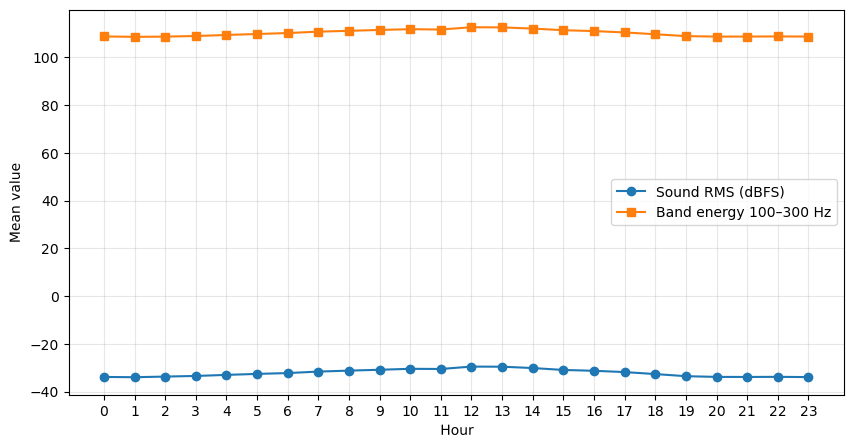

In [136]:
plt.figure(figsize=(10,5))

plt.plot(hourly.index, hourly["rms"], marker="o", label="Sound RMS (dBFS)")
plt.plot(hourly.index, hourly["band"], marker="s", label="Band energy 100–300 Hz")

plt.xlabel("Hour")
plt.ylabel("Mean value")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()

plt.show()

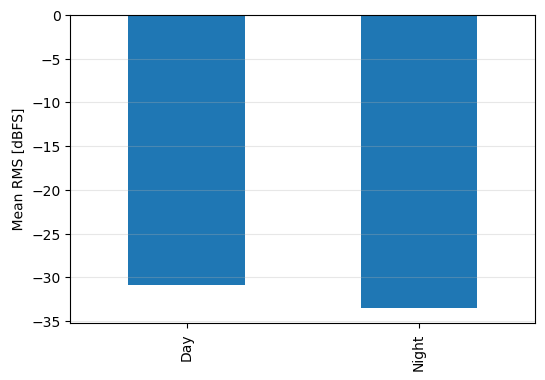

In [183]:
fig, ax = plt.subplots(figsize=(6, 4))

day_night["rms_mean_dbfs"].plot(kind="bar", ax=ax)

ax.set_ylabel("Mean RMS [dBFS]")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)

plt.show()

<Axes: xlabel='period'>

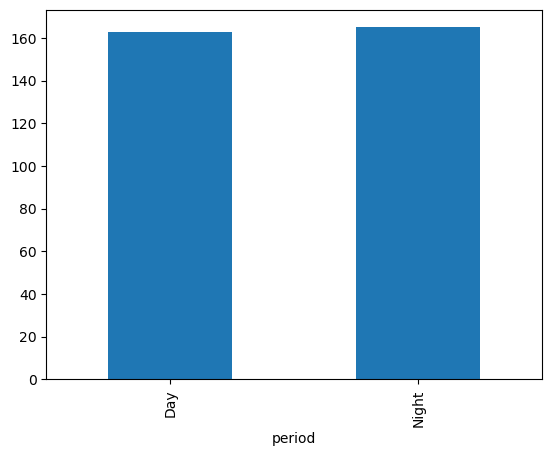

In [138]:
day_night["freq_mean"].plot(kind="bar")

<Axes: xlabel='period'>

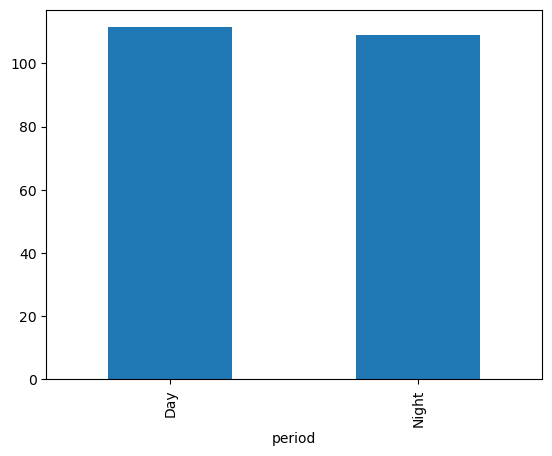

In [139]:
day_night["band_mean"].plot(kind="bar")

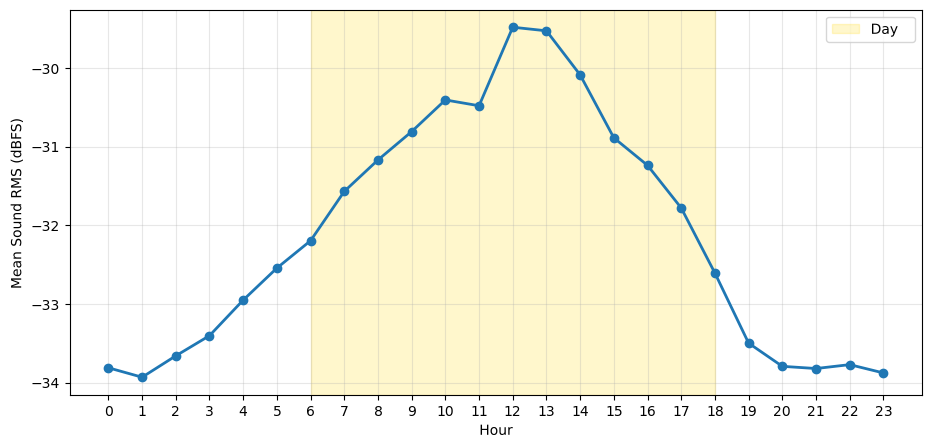

In [ ]:
plt.figure(figsize=(11, 5))

plt.plot(hourly.index, hourly["rms_dbfs"], marker="o", linewidth=2)
plt.axvspan(6, 18, color="gold", alpha=0.2, label="Day")

plt.xticks(range(24))
plt.xlabel("Hour")
plt.ylabel("Mean RMS [dBFS]")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

The chart shows the mean value of the Sound RMS (dBFS) parameter for consecutive hours of the day. At night (0:00–5:00) the RMS values are the lowest (about -34 dBFS), which indicates lower acoustic activity. From the morning hours a gradual rise of RMS is observed, reaching a maximum around 12:00–13:00 (about -29.5 dBFS). After that the values gradually decrease and in the evening and at night they again reach a level close to the starting one.

# CSV files with data computed directly from the recordings (my own)

In [141]:
INPUT_FOLDER = Path("data/h_29/all_audio_hive29")

OUTPUT_FILE = Path("data/h_29/Hive29_audio_features.csv")

In [ ]:
audio_files = sorted(INPUT_FOLDER.glob("*.wav"))

print(f"Number of files: {len(audio_files)}")

In [ ]:
results = []

for file in tqdm(audio_files):

    numbers = re.findall(r"\d+", file.name)

    if len(numbers) < 6:
        continue

    year, month, day = numbers[:3]
    hour, minute, second = numbers[3:6]

    timestamp = pd.Timestamp(
        f"{year}-{month}-{day} {hour}:{minute}:{second}"
    )

    try:
        y, sr = sf.read(file)

        if y.ndim > 1:
            y = np.mean(y, axis=1)

        y = np.nan_to_num(y)

        peak = np.max(np.abs(y))

        if peak < 0.001:
            continue

        duration = len(y) / sr

        rms = np.sqrt(np.mean(y ** 2))

        spectrum = np.abs(np.fft.rfft(y))
        freqs = np.fft.rfftfreq(len(y), d=1 / sr)
        dominant_freq = freqs[np.argmax(spectrum)]

        centroid = librosa.feature.spectral_centroid(y=y, sr=sr).mean()

        bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr).mean()

        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr).mean()

        zcr = librosa.feature.zero_crossing_rate(y).mean()

        results.append({
            "filename": file.name,
            "timestamp_audio": timestamp,
            "date": timestamp.date(),
            "hour": timestamp.hour,
            "duration_s": duration,
            "rms": rms,
            "peak": peak,
            "f0_hz": dominant_freq,
            "spectral_centroid": centroid,
            "spectral_bandwidth": bandwidth,
            "spectral_rolloff": rolloff,
            "zero_crossing_rate": zcr
        })

        del y, spectrum, freqs

    except Exception as e:

        print(f"Error: {file.name}")
        print(e)

df_features = pd.DataFrame(results)

df_features = df_features.sort_values("timestamp_audio")

df_features.to_csv(
    OUTPUT_FILE,
    index=False
)

print()

print(df_features.head())

print()

print(f"Number of valid recordings: {len(df_features)}")

print(f"File saved to:\n{OUTPUT_FILE}")

# Distribution of RMS and Peak

In [144]:
files = [
    "data/h_all/h_27/Hive27_audio_features.csv",
    "data/h_all/h_28/Hive28_audio_features.csv",
    "data/h_all/h_29/Hive29_audio_features.csv",
    "data/h_all/h_30/Hive30_audio_features.csv"
]

dfs = []

for file in files:
    df = pd.read_csv(file)
    df["hive"] = Path(file).stem.split("_")[0].replace("Hive", "")
    dfs.append(df)

all_df = pd.concat(dfs, ignore_index=True)

print(all_df.shape)

(174920, 13)


In [145]:
print(
    all_df["rms"].describe(
        percentiles=[0.01,0.05,0.1,0.25,0.5,0.75,0.9,0.95,0.99]
    )
)

count    174920.000000
mean          0.022349
std           0.019140
min           0.000021
1%            0.003808
5%            0.006484
10%           0.008693
25%           0.013062
50%           0.018512
75%           0.026607
90%           0.038448
95%           0.048767
99%           0.079847
max           0.735358
Name: rms, dtype: float64


In [146]:
print(
    all_df["peak"].describe(
        percentiles=[0.01,0.05,0.1,0.25,0.5,0.75,0.9,0.95,0.99]
    )
)

count    174920.000000
mean          0.205109
std           0.192956
min           0.001007
1%            0.022247
5%            0.042755
10%           0.056305
25%           0.086426
50%           0.140991
75%           0.251038
90%           0.414554
95%           0.605780
99%           1.000000
max           1.000000
Name: peak, dtype: float64


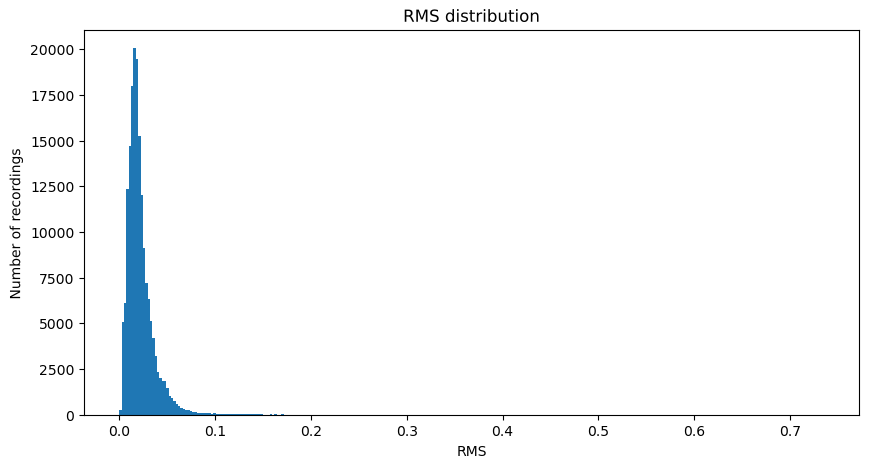

In [147]:
plt.figure(figsize=(10,5))

plt.hist(all_df["rms"], bins=300)

plt.xlabel("RMS")
plt.ylabel("Number of recordings")
plt.title("RMS distribution")

plt.show()

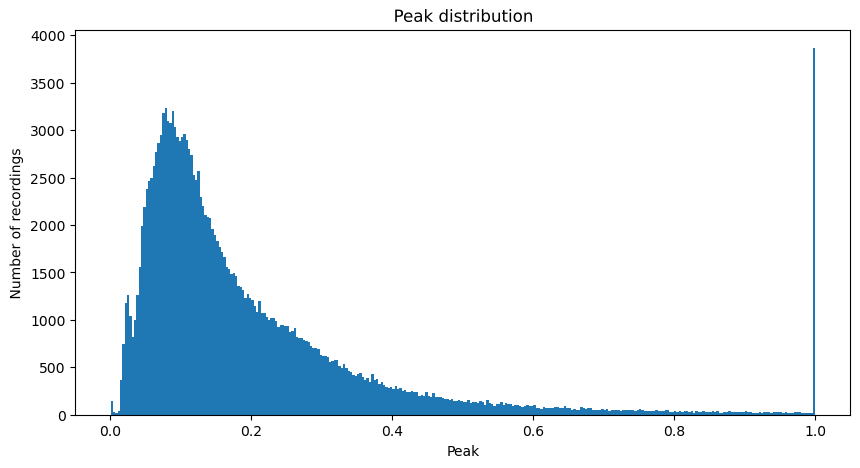

In [148]:
plt.figure(figsize=(10,5))

plt.hist(all_df["peak"], bins=300)

plt.xlabel("Peak")
plt.ylabel("Number of recordings")
plt.title("Peak distribution")

plt.show()

In [149]:
thresholds = [
    0,
    0.00002,
    0.00005,
    0.00008,
    0.00010,
    0.00015,
    0.00020,
    0.00030,
    0.00050
]

for t in thresholds:
    kept = (all_df["rms"] >= t).sum()
    print(f"RMS >= {t:.5f}: {kept:,} recordings ({kept/len(all_df)*100:.1f}%)")

RMS >= 0.00000: 174,920 recordings (100.0%)
RMS >= 0.00002: 174,920 recordings (100.0%)
RMS >= 0.00005: 174,898 recordings (100.0%)
RMS >= 0.00008: 174,851 recordings (100.0%)
RMS >= 0.00010: 174,822 recordings (99.9%)
RMS >= 0.00015: 174,780 recordings (99.9%)
RMS >= 0.00020: 174,745 recordings (99.9%)
RMS >= 0.00030: 174,716 recordings (99.9%)
RMS >= 0.00050: 174,692 recordings (99.9%)


In [150]:
thresholds = [
    0,
    0.001,
    0.002,
    0.003,
    0.005,
    0.010,
    0.020,
    0.050
]

for t in thresholds:
    kept = (all_df["peak"] >= t).sum()
    print(f"Peak >= {t:.3f}: {kept:,} recordings ({kept/len(all_df)*100:.1f}%)")

Peak >= 0.000: 174,920 recordings (100.0%)
Peak >= 0.001: 174,920 recordings (100.0%)
Peak >= 0.002: 174,829 recordings (99.9%)
Peak >= 0.003: 174,801 recordings (99.9%)
Peak >= 0.005: 174,758 recordings (99.9%)
Peak >= 0.010: 174,732 recordings (99.9%)
Peak >= 0.020: 173,845 recordings (99.4%)
Peak >= 0.050: 161,957 recordings (92.6%)


# Combined CSV

In [152]:
audio_csvs = {
    "21": "data/h_all/h_21/Hive21_audio_features.csv",
    "23": "data/h_all/h_23/Hive23_audio_features.csv",
    "25": "data/h_all/h_25/Hive25_audio_features.csv",
    "26": "data/h_all/h_26/Hive26_audio_features.csv",
    "27": "data/h_all/h_27/Hive27_audio_features.csv",
    "28": "data/h_all/h_28/Hive28_audio_features.csv",
    "29": "data/h_all/h_29/Hive29_audio_features.csv",
    "30": "data/h_all/h_30/Hive30_audio_features.csv",
}

In [175]:
audio_dfs = []

for hive, path in audio_csvs.items():
    temp = pd.read_csv(path)
    temp["Hive"] = hive
    audio_dfs.append(temp)

audio_features = pd.concat(
    audio_dfs,
    ignore_index=True
)

audio_features["timestamp_audio"] = pd.to_datetime(
    audio_features["timestamp_audio"]
)

audio_features["date"] = pd.to_datetime(
    audio_features["date"]
).dt.date

audio_features["rms_dbfs"] = np.where(
    audio_features["rms"] > 0,
    20 * np.log10(audio_features["rms"]),
    np.nan
)

print(audio_features.shape)
display(audio_features.head())

(442774, 14)


,filename,timestamp_audio,date,hour,duration_s,rms,peak,f0_hz,spectral_centroid,spectral_bandwidth,spectral_rolloff,zero_crossing_rate,Hive,rms_dbfs
0,2026-04-03_10-49-00_48.384s.wav,2026-04-03 10:49:00,2026-04-03,10,48.384,0.000133,0.001160,112.247851,1739.859403,2202.202818,4526.551140,0.071335,21,-77.533165
1,2026-04-03_10-50-00_21.504s.wav,2026-04-03 10:50:00,2026-04-03,10,21.504,0.000158,0.001221,111.328125,1647.287147,2149.280297,4256.640045,0.067460,21,-76.027178
2,2026-04-03_10-51-00_25.344s.wav,2026-04-03 10:51:00,2026-04-03,10,25.344,0.000201,0.003387,114.977904,1568.832282,2128.408667,4003.605769,0.059442,21,-73.920469
3,2026-04-03_10-52-00_28.416s.wav,2026-04-03 10:52:00,2026-04-03,10,28.416,0.000164,0.001495,132.108671,1585.830551,2122.674290,4070.479471,0.062103,21,-75.724298
4,2026-04-03_10-53-00_19.968s.wav,2026-04-03 10:53:00,2026-04-03,10,19.968,0.000166,0.001099,211.288061,1592.043645,2129.932854,4107.450000,0.064413,21,-75.606588


In [4]:
print(audio_features["Hive"].value_counts().sort_index())

Hive
21    57915
23    78161
25    38724
26    93054
27    83315
28    17981
29    22236
30    51388
Name: count, dtype: int64


## Day and night analysis on the computed data

In [176]:
audio_features["hour"] = audio_features["timestamp_audio"].dt.hour

audio_features["period"] = np.where(
    audio_features["hour"].between(6, 17),
    "Day",
    "Night"
)

In [177]:
day_night = (
    audio_features
    .groupby("period")
    .agg(
        recordings=("filename", "count"),
        rms_mean_dbfs=("rms_dbfs", "mean"),
        rms_std_dbfs=("rms_dbfs", "std"),
        peak_mean=("peak", "mean"),
        f0_mean=("f0_hz", "mean"),
        centroid_mean=("spectral_centroid", "mean"),
        bandwidth_mean=("spectral_bandwidth", "mean"),
        rolloff_mean=("spectral_rolloff", "mean"),
        zcr_mean=("zero_crossing_rate", "mean")
    )
    .round(3)
)

display(day_night)

,recordings,rms_mean_dbfs,rms_std_dbfs,peak_mean,f0_mean,centroid_mean,bandwidth_mean,rolloff_mean,zcr_mean
period,,,,,,,,,
Day,222595,-30.819,5.550,0.266,187.782,1722.431,2106.380,4133.581,0.079
Night,220179,-33.524,5.668,0.207,195.641,1864.391,2205.802,4529.111,0.079


In [178]:
hive_day_night = (
    audio_features
    .groupby(["Hive", "period"])
    .agg(
        recordings=("filename", "count"),
        rms_mean_dbfs=("rms_dbfs", "mean"),
        rms_std_dbfs=("rms_dbfs", "std"),
        peak_mean=("peak", "mean"),
        f0_mean=("f0_hz", "mean"),
        centroid_mean=("spectral_centroid", "mean"),
        bandwidth_mean=("spectral_bandwidth", "mean"),
        rolloff_mean=("spectral_rolloff", "mean"),
        zcr_mean=("zero_crossing_rate", "mean")
    )
    .round(3)
)

display(hive_day_night)

recordings  rms_mean_dbfs  rms_std_dbfs  peak_mean  f0_mean  \
Hive period                                                                
21   Day          29170        -27.399         3.705      0.310  180.603   
     Night        28745        -29.220         2.929      0.247  173.166   
23   Day          39338        -30.808         5.071      0.269  236.400   
     Night        38823        -34.370         5.059      0.214  228.803   
25   Day          19659        -28.198         5.821      0.317  187.672   
     Night        19065        -29.853         6.601      0.250  203.467   
26   Day          46598        -29.491         5.138      0.285  180.226   
     Night        46456        -31.897         4.566      0.209  170.322   
27   Day          41763        -34.768         4.754      0.171  165.122   
     Night        41552        -38.681         4.752      0.113  218.352   
28   Day           9716        -27.178         4.469      0.354  194.857   
     Night         8265        -28.193         2.294      0.325  184.350   
29   Day          10819        -31.832         4.931      0.221  142.224   
     Night        11417        -33.054         2.591      0.178  146.987   
30   Day          25532        -33.678         4.804      0.281  188.631   
     Night        25856        -36.297         4.378      0.245  199.154   

             centroid_mean  bandwidth_mean  rolloff_mean  zcr_mean  
Hive period                                                         
21   Day          1426.936        1966.316      3439.400     0.057  
     Night        1460.425        2013.903      3597.282     0.055  
23   Day          1835.390        2130.756      4269.626     0.099  
     Night        1994.513        2246.239      4747.218     0.096  
25   Day          1584.753        1991.369      3508.877     0.077  
     Night        1601.977        2031.988      3561.382     0.069  
26   Day          1662.913        2073.959      4085.378     0.074  
     Night        1745.953        2165.415      4413.162     0.072  
27   Day          1908.668        2236.012      4670.000     0.085  
     Night        2197.252        2398.800      5357.622     0.088  
28   Day          1434.346        2006.696      3439.808     0.057  
     Night        1558.665        2102.226      3897.494     0.060  
29   Day          1515.917        2029.679      3736.473     0.063  
     Night        1573.772        2096.847      4017.384     0.062  
30   Day          1993.136        2234.963      4840.899     0.093  
     Night        2215.533        2330.210      5255.849     0.101

In [ ]:
hourly = (
    audio_features
    .groupby("hour")
    .agg(
        recordings=("filename", "count"),
        rms_mean_dbfs=("rms_dbfs", "mean"),
        f0_mean=("f0_hz", "mean"),
        centroid_mean=("spectral_centroid", "mean"),
        bandwidth_mean=("spectral_bandwidth", "mean"),
        rolloff_mean=("spectral_rolloff", "mean"),
        zcr_mean=("zero_crossing_rate", "mean")
    )
    .round(3)
)

display(hourly)

,recordings,rms_mean,f0_mean,centroid_mean,bandwidth_mean,rolloff_mean,zcr_mean
hour,,,,,,,
0,18240,0.024,198.161,1875.841,2220.906,4573.652,0.076
1,18196,0.024,209.245,1892.919,2224.622,4602.869,0.079
2,18197,0.024,213.164,1922.406,2213.959,4604.453,0.086
3,18230,0.024,200.674,1872.606,2201.473,4538.864,0.083
4,18239,0.026,192.271,1817.921,2185.708,4446.788,0.079
5,18234,0.027,198.235,1795.923,2179.265,4414.833,0.077
6,18608,0.028,188.721,1773.045,2168.796,4362.209,0.076
7,18944,0.032,200.623,1767.164,2152.087,4303.972,0.078
8,18630,0.032,205.637,1766.357,2134.729,4257.666,0.081


In [159]:
hive_hourly = (
    audio_features
    .groupby(["Hive", "hour"])
    .agg(
        recordings=("filename", "count"),
        rms_mean=("rms", "mean"),
        f0_mean=("f0_hz", "mean"),
        centroid_mean=("spectral_centroid", "mean"),
        bandwidth_mean=("spectral_bandwidth", "mean"),
        rolloff_mean=("spectral_rolloff", "mean"),
        zcr_mean=("zero_crossing_rate", "mean")
    )
    .round(3)
)

display(hive_hourly)

recordings  rms_mean  f0_mean  centroid_mean  bandwidth_mean  \
Hive hour                                                                 
21   0           2400     0.036  173.841       1446.877        2013.971   
     1           2400     0.036  172.315       1451.576        2021.086   
     2           2402     0.035  172.066       1489.529        2025.753   
     3           2400     0.035  170.193       1490.109        2023.634   
     4           2400     0.037  167.649       1469.683        2015.924   
...               ...       ...      ...            ...             ...   
30   19          2160     0.018  188.542       2193.563        2327.522   
     20          2160     0.017  196.867       2221.992        2347.679   
     21          2160     0.017  196.597       2243.473        2350.014   
     22          2108     0.018  198.682       2254.185        2339.840   
     23          2151     0.016  193.941       2239.099        2342.862   

           rolloff_mean  zcr_mean  
Hive hour                          
21   0         3575.468     0.054  
     1         3604.892     0.053  
     2         3672.336     0.058  
     3         3673.728     0.059  
     4         3630.566     0.058  
...                 ...       ...  
30   19        5226.159     0.101  
     20        5296.902     0.098  
     21        5319.684     0.100  
     22        5311.959     0.102  
     23        5307.028     0.099  

[192 rows x 7 columns]

In [179]:
diff = (
    hive_day_night
    .reset_index()
    .pivot(
        index="Hive",
        columns="period",
        values=[
            "rms_mean_dbfs",
            "f0_mean",
            "centroid_mean",
            "bandwidth_mean",
            "rolloff_mean",
            "zcr_mean"
        ]
    )
)

diff["rms_diff_dbfs"] = diff["rms_mean_dbfs"]["Night"] - diff["rms_mean_dbfs"]["Day"]
diff["f0_diff"] = diff["f0_mean"]["Night"] - diff["f0_mean"]["Day"]
diff["centroid_diff"] = diff["centroid_mean"]["Night"] - diff["centroid_mean"]["Day"]
diff["bandwidth_diff"] = diff["bandwidth_mean"]["Night"] - diff["bandwidth_mean"]["Day"]
diff["rolloff_diff"] = diff["rolloff_mean"]["Night"] - diff["rolloff_mean"]["Day"]
diff["zcr_diff"] = diff["zcr_mean"]["Night"] - diff["zcr_mean"]["Day"]

display(
    diff[
        [
            "rms_diff_dbfs",
            "f0_diff",
            "centroid_diff",
            "bandwidth_diff",
            "rolloff_diff",
            "zcr_diff"
        ]
    ].round(3)
)

,rms_diff_dbfs,f0_diff,centroid_diff,bandwidth_diff,rolloff_diff,zcr_diff
period,,,,,,
Hive,,,,,,
21,-1.821,-7.437,33.489,47.587,157.882,-0.002
23,-3.562,-7.597,159.123,115.483,477.592,-0.003
25,-1.655,15.795,17.224,40.619,52.505,-0.008
26,-2.406,-9.904,83.040,91.456,327.784,-0.002
27,-3.913,53.230,288.584,162.788,687.622,0.003
28,-1.015,-10.507,124.319,95.530,457.686,0.003
29,-1.222,4.763,57.855,67.168,280.911,-0.001
30,-2.619,10.523,222.397,95.247,414.950,0.008


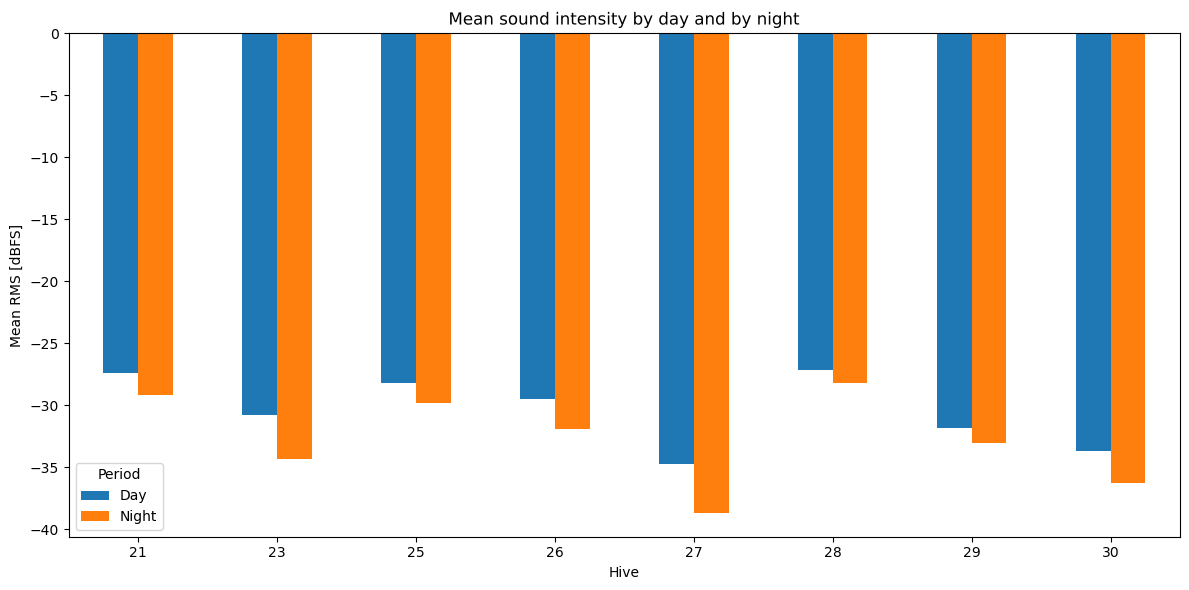

In [181]:
plot_data = (
    hive_day_night
    .reset_index()
    .pivot(
        index="Hive",
        columns="period",
        values="rms_mean_dbfs"
    )
)

plot_data.plot(kind="bar", figsize=(12, 6))
plt.xlabel("Hive")
plt.ylabel("Mean RMS [dBFS]")
plt.title("Mean sound intensity by day and by night")
plt.xticks(rotation=0)
plt.legend(title="Period")
plt.tight_layout()
plt.show()

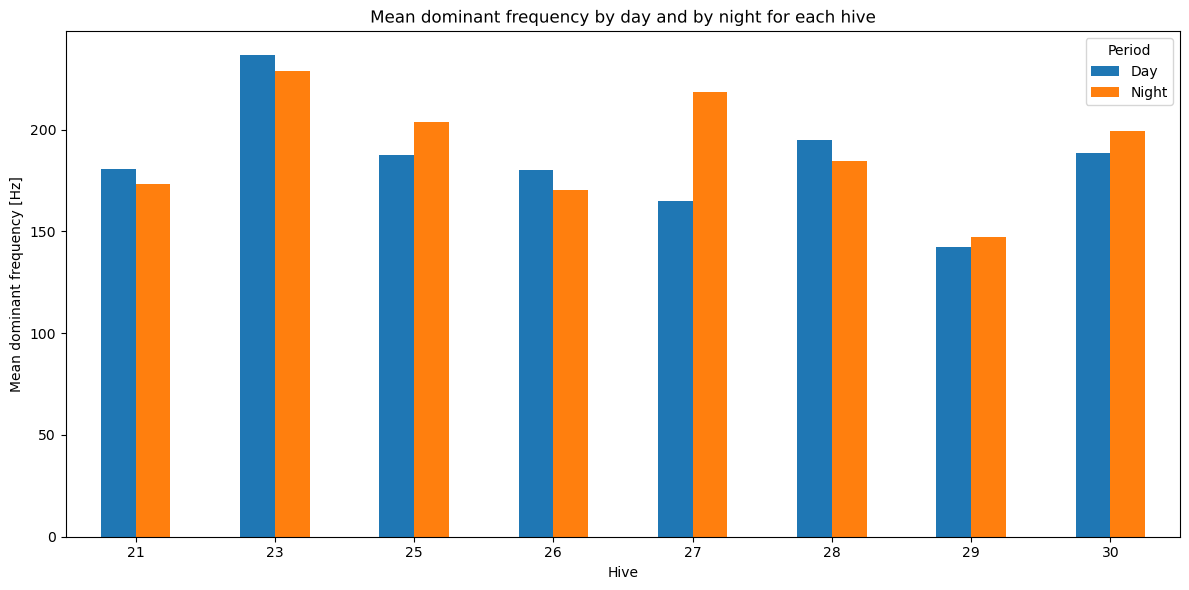

In [162]:
plot_data = (
    hive_day_night
    .reset_index()
    .pivot(
        index="Hive",
        columns="period",
        values="f0_mean"
    )
)

plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.xlabel("Hive")
plt.ylabel("Mean dominant frequency [Hz]")
plt.title("Mean dominant frequency by day and by night for each hive")
plt.xticks(rotation=0)
plt.legend(title="Period")
plt.tight_layout()
plt.show()

In [180]:
hourly = (
    audio_features
    .groupby("hour")
    .agg(
        recordings=("filename", "count"),
        rms_dbfs=("rms_dbfs", "mean"),
        f0=("f0_hz", "mean"),
        centroid=("spectral_centroid", "mean"),
        bandwidth=("spectral_bandwidth", "mean")
    )
)

display(hourly.round(3))

,recordings,rms_dbfs,f0,centroid,bandwidth
hour,,,,,
0,18240,-33.837,198.161,1875.841,2220.906
1,18196,-33.974,209.245,1892.919,2224.622
2,18197,-33.737,213.164,1922.406,2213.959
3,18230,-33.492,200.674,1872.606,2201.473
4,18239,-33.031,192.271,1817.921,2185.708
5,18234,-32.660,198.235,1795.923,2179.265
6,18608,-32.305,188.721,1773.045,2168.796
7,18944,-31.619,200.623,1767.164,2152.087
8,18630,-31.142,205.637,1766.357,2134.729


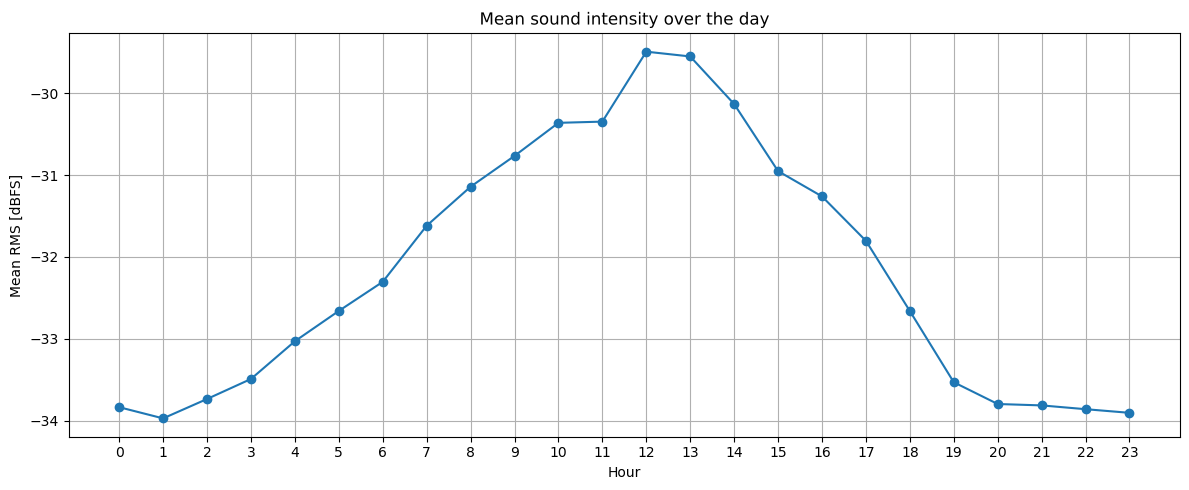

In [182]:
plt.figure(figsize=(12, 5))

plt.plot(hourly.index, hourly["rms_dbfs"], marker="o")

plt.xlabel("Hour")
plt.ylabel("Mean RMS [dBFS]")
plt.title("Mean sound intensity over the day")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

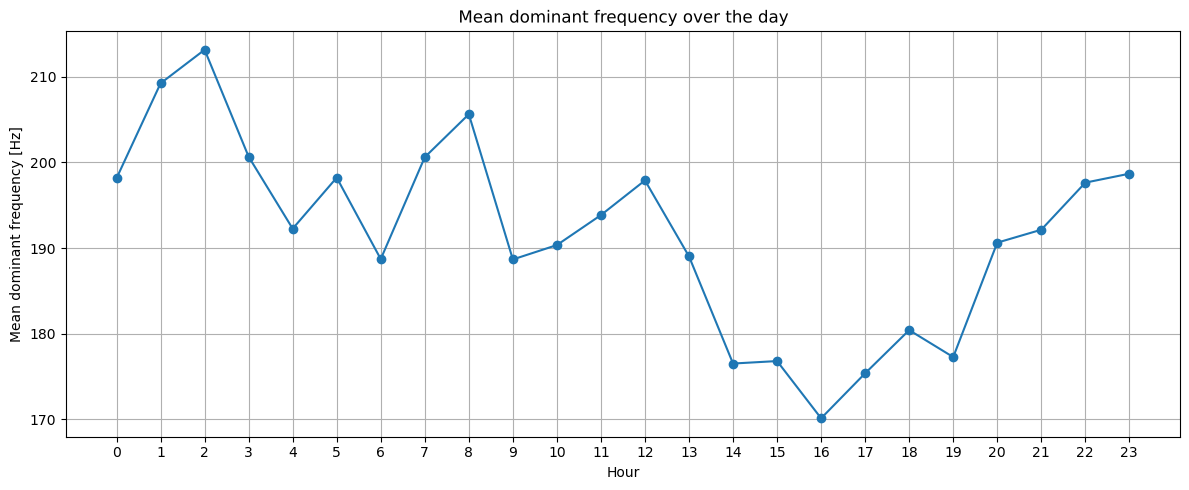

In [165]:
plt.figure(figsize=(12, 5))

plt.plot(hourly.index, hourly["f0"], marker="o")

plt.xlabel("Hour")
plt.ylabel("Mean dominant frequency [Hz]")
plt.title("Mean dominant frequency over the day")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

## Anomalies

In [184]:
hour_profile = (
    audio_features
    .groupby("hour")
    .agg(
        rms_mean=("rms", "mean"),
        rms_std=("rms", "std"),
        f0_mean=("f0_hz", "mean"),
        f0_std=("f0_hz", "std")
    )
)

display(hour_profile.round(4))

,rms_mean,rms_std,f0_mean,f0_std
hour,,,,
0,0.0244,0.0139,198.1613,354.7285
1,0.0240,0.0134,209.2453,440.7735
2,0.0243,0.0137,213.1640,430.2999
3,0.0244,0.0127,200.6743,349.4492
4,0.0257,0.0146,192.2714,359.7550
5,0.0266,0.0138,198.2351,452.5804
6,0.0277,0.0152,188.7210,368.5203
7,0.0317,0.0323,200.6226,441.0165
8,0.0318,0.0174,205.6373,429.1267


In [185]:
audio = audio_features.merge(
    hour_profile,
    left_on="hour",
    right_index=True,
    suffixes=("", "_hour")
)

In [186]:
audio["rms_zscore"] = (
    (audio["rms"] - audio["rms_mean"])
    / audio["rms_std"]
)

In [187]:
audio["f0_zscore"] = (
    (audio["f0_hz"] - audio["f0_mean"])
    / audio["f0_std"]
)

In [188]:
audio["anomaly_candidate"] = (
    (audio["rms_zscore"].abs() >= 3) |
    (audio["f0_zscore"].abs() >= 3)
)

In [21]:
print(
    audio["anomaly_candidate"]
    .value_counts()
)

anomaly_candidate
False    437521
True       5253
Name: count, dtype: int64


In [22]:
anomalies = (
    audio[audio["anomaly_candidate"]]
    .sort_values("timestamp_audio")
)

display(
    anomalies[
        [
            "Hive",
            "filename",
            "timestamp_audio",
            "hour",
            "period",
            "rms",
            "f0_hz",
            "rms_zscore",
            "f0_zscore"
        ]
    ].head(100)
)

,Hive,filename,timestamp_audio,hour,period,rms,f0_hz,rms_zscore,f0_zscore
391390,30,2026-03-18_10-50-00_55.296s.wav,2026-03-18 10:50:00,10,Day,0.000543,5256.872106,-1.692571,17.897804
391392,30,2026-03-18_10-52-00_10.752s.wav,2026-03-18 10:52:00,10,Day,0.000394,3488.932292,-1.699765,11.652436
267903,27,2026-03-18_14-40-00_39.168s.wav,2026-03-18 14:40:00,14,Day,0.000394,1090.813930,-1.748879,9.595826
175642,26,2026-03-19_05-23-00_59.904s.wav,2026-03-19 05:23:00,5,Night,0.074132,79.777644,3.432279,-0.261738
369346,29,2026-03-19_05-23-00_19.2s.wav,2026-03-19 05:23:00,5,Night,0.113842,79.531250,6.301927,-0.262282
...,...,...,...,...,...,...,...,...,...
57997,23,2026-04-03_12-11-00_36.864s.wav,2026-04-03 12:11:00,12,Day,0.146037,85.801866,4.095768,-0.327752
136162,25,2026-04-03_12-15-00_26.112s.wav,2026-04-03 12:15:00,12,Day,0.210687,98.077512,6.575777,-0.291863
351344,28,2026-04-03_12-15-00_59.904s.wav,2026-04-03 12:15:00,12,Day,0.121965,97.773104,3.172327,-0.292753
351345,28,2026-04-03_12-16-00_60.672s.wav,2026-04-03 12:16:00,12,Day,0.137315,110.858386,3.761167,-0.254498


In [23]:
anomalies_by_hive = (
    audio
    .groupby("Hive")["anomaly_candidate"]
    .agg(
        anomalies="sum",
        recordings="count"
    )
)

anomalies_by_hive["anomaly_percent"] = (
    anomalies_by_hive["anomalies"]
    / anomalies_by_hive["recordings"]
    * 100
)

display(anomalies_by_hive.round(2))

,anomalies,recordings,anomaly_percent
Hive,,,
21,793,57915,1.37
23,1108,78161,1.42
25,728,38724,1.88
26,623,93054,0.67
27,1094,83315,1.31
28,438,17981,2.44
29,53,22236,0.24
30,416,51388,0.81


In [34]:
anomalies_by_hour = (
    audio[audio["anomaly_candidate"]]
    .groupby("hour")
    .size()
)

display(anomalies_by_hour)

hour
0     190
1     210
2     293
3     164
4     173
5     224
6     189
7     244
8     275
9     189
10    195
11    199
12    199
13    237
14    219
15    163
16    346
17    295
18    230
19    171
20    209
21    214
22    246
23    179
dtype: int64

In [29]:
anomalies_by_date = (
    audio[audio["anomaly_candidate"]]
    .groupby(["Hive", "date"])
    .size()
    .reset_index(name="anomalies")
)

display(anomalies_by_date)

,Hive,date,anomalies
0,21,2026-04-03,2
1,21,2026-04-04,2
2,21,2026-04-05,4
3,21,2026-04-06,2
4,21,2026-04-07,4
...,...,...,...
302,30,2026-06-09,2
303,30,2026-06-10,14
304,30,2026-06-11,17
305,30,2026-06-12,8


## Anomaly visualization

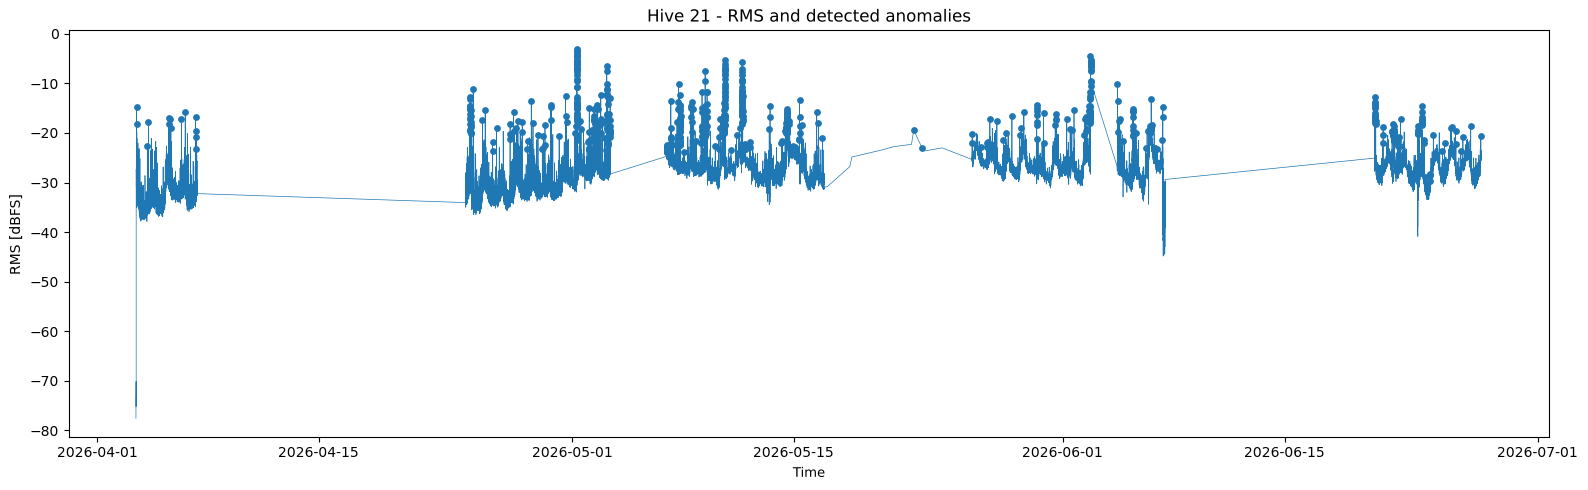

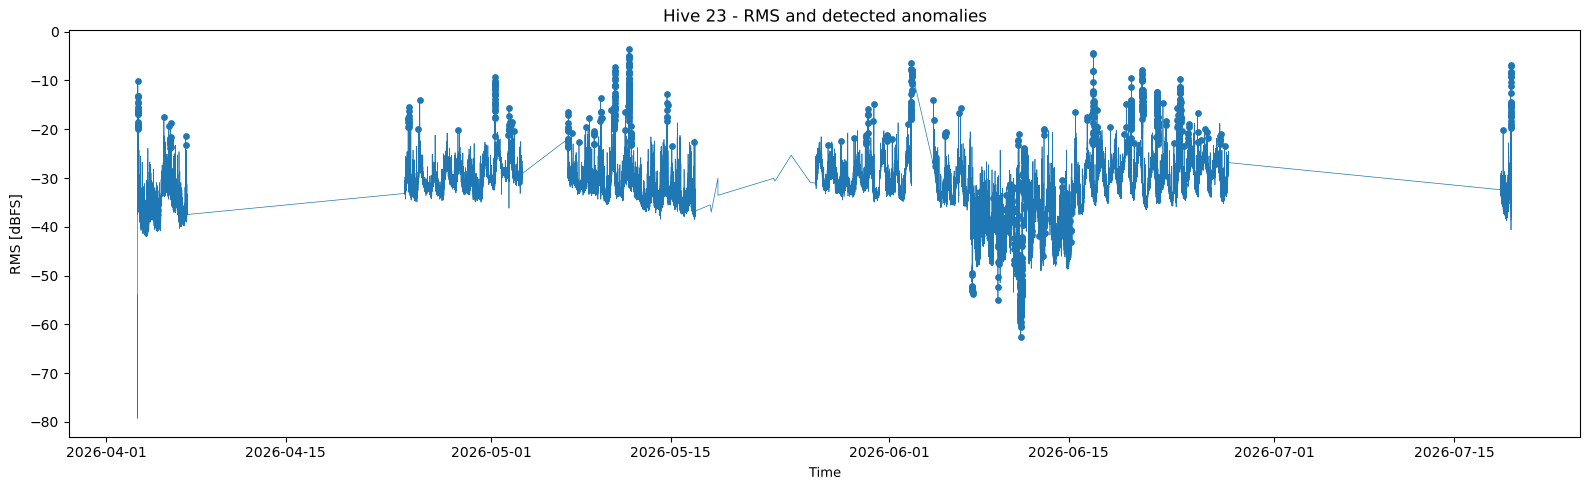

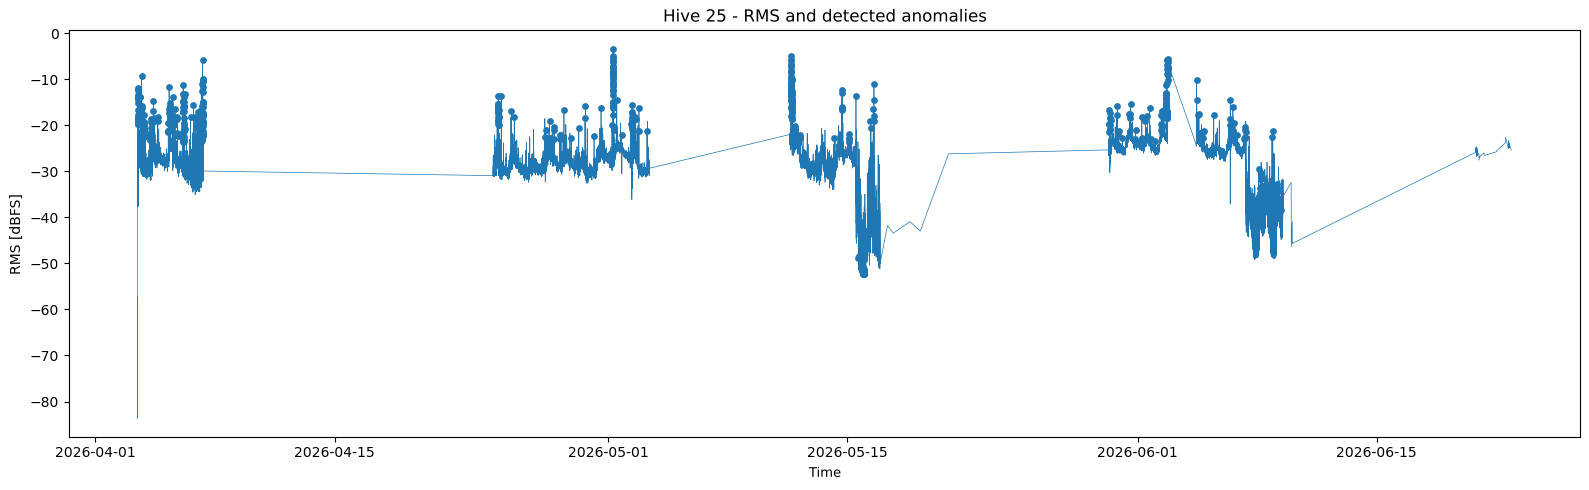

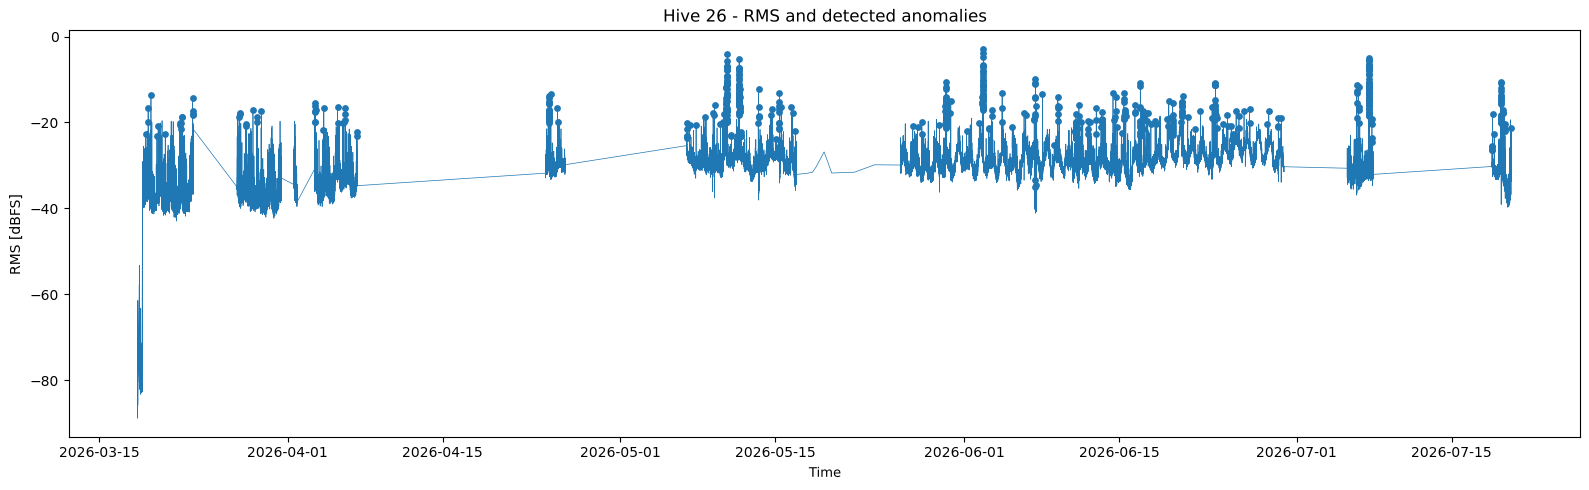

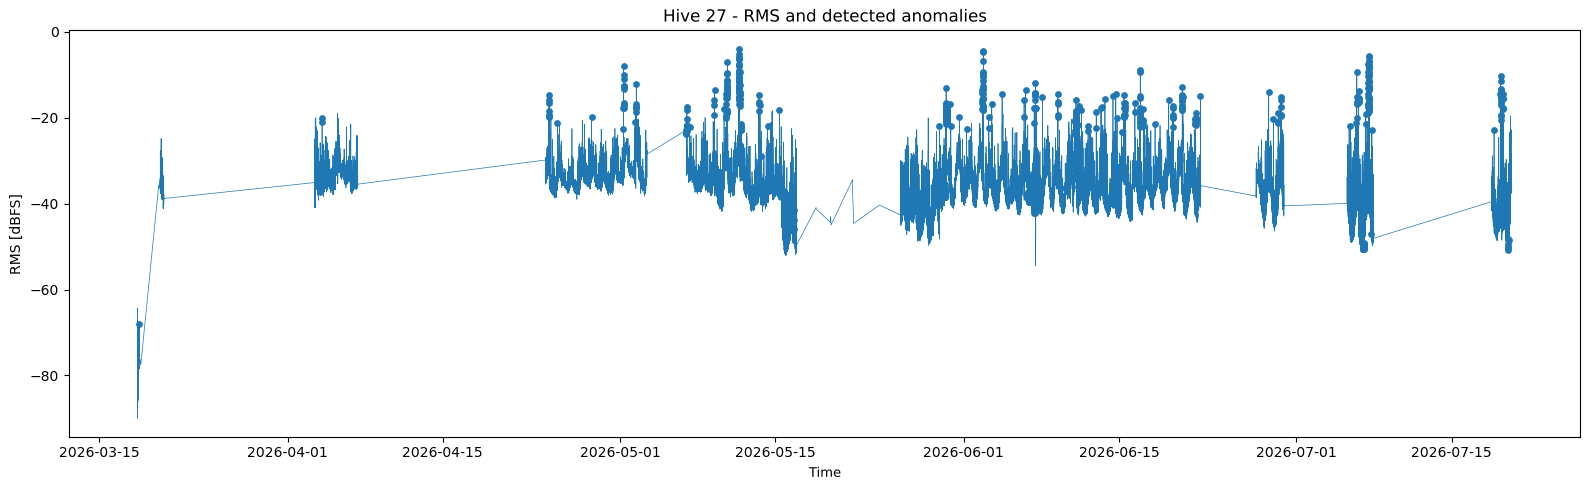

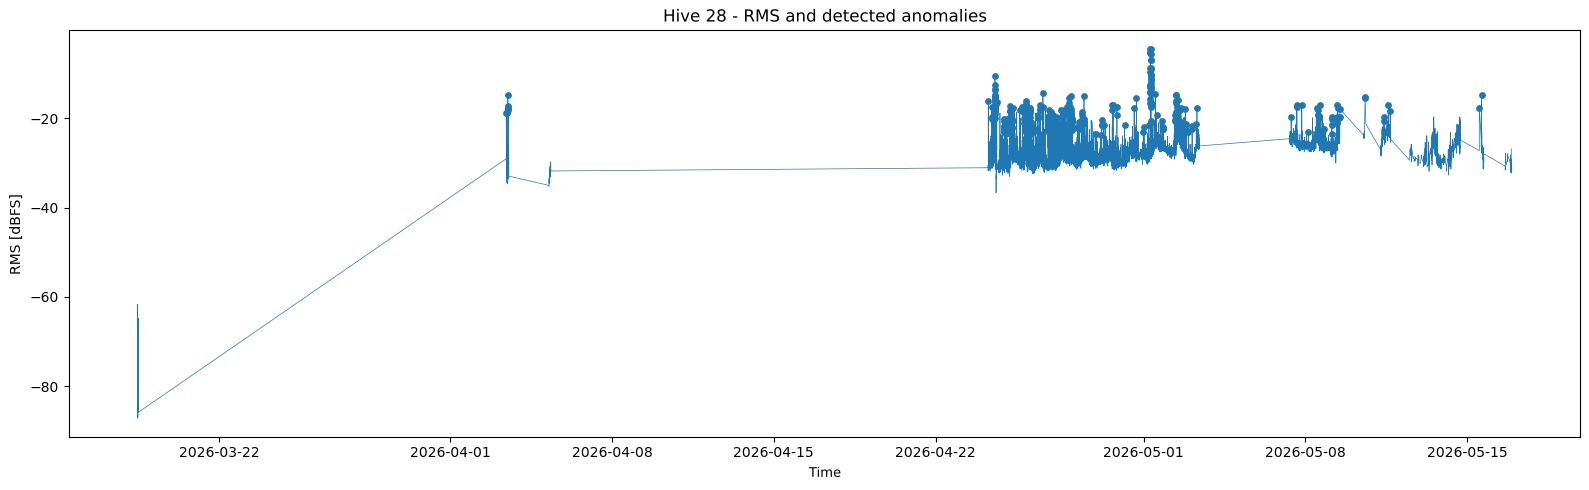

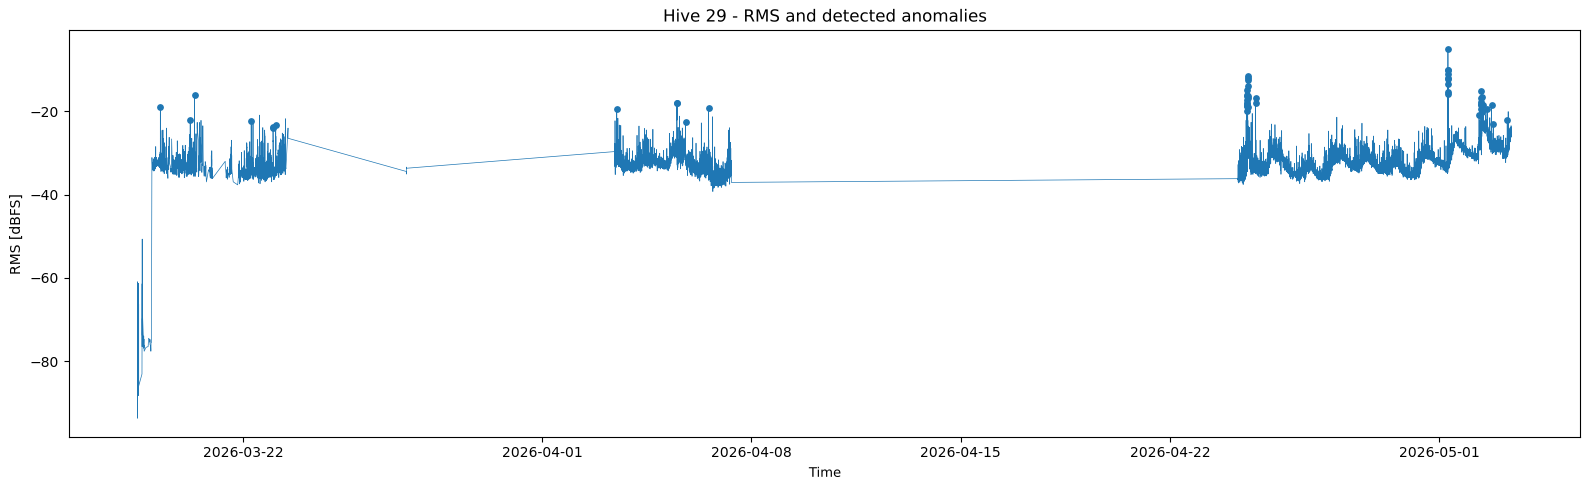

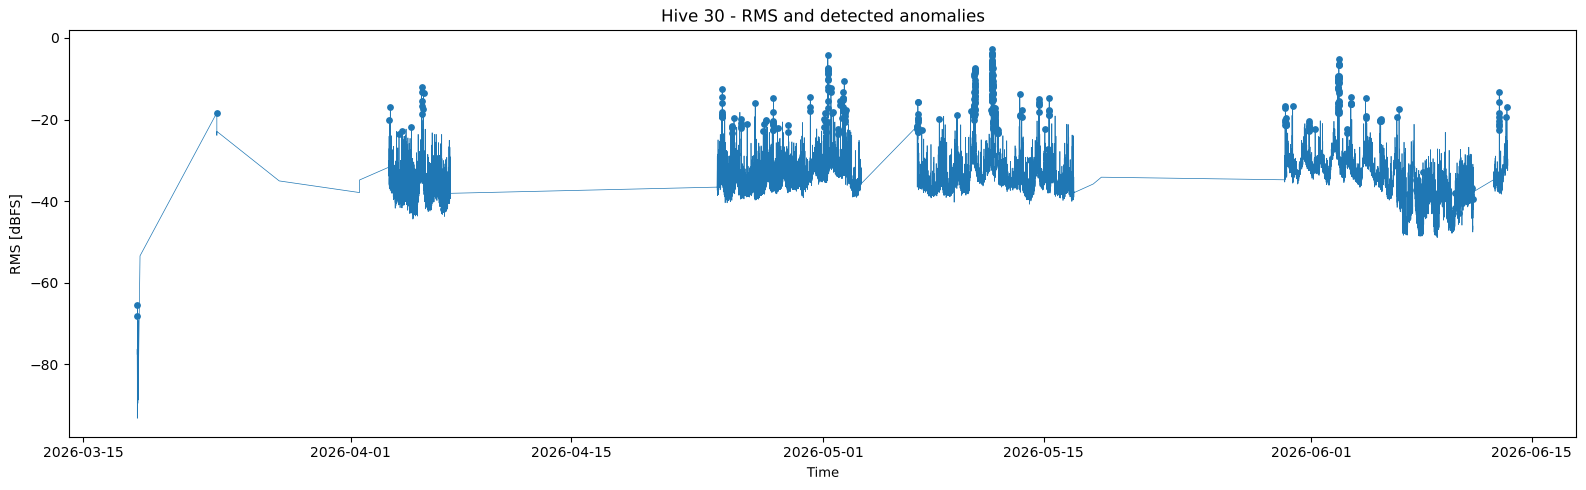

In [189]:
for hive in sorted(audio["Hive"].unique()):
    hive_data = audio[
        audio["Hive"] == hive
    ].sort_values("timestamp_audio")

    plt.figure(figsize=(16, 5))

    plt.plot(
        hive_data["timestamp_audio"],
        hive_data["rms_dbfs"],
        linewidth=0.5
    )

    anomalies_hive = hive_data[hive_data["anomaly_candidate"]]

    plt.scatter(
        anomalies_hive["timestamp_audio"],
        anomalies_hive["rms_dbfs"],
        s=15
    )

    plt.title(f"Hive {hive} - RMS and detected anomalies")
    plt.xlabel("Time")
    plt.ylabel("RMS [dBFS]")
    plt.tight_layout()
    plt.show()

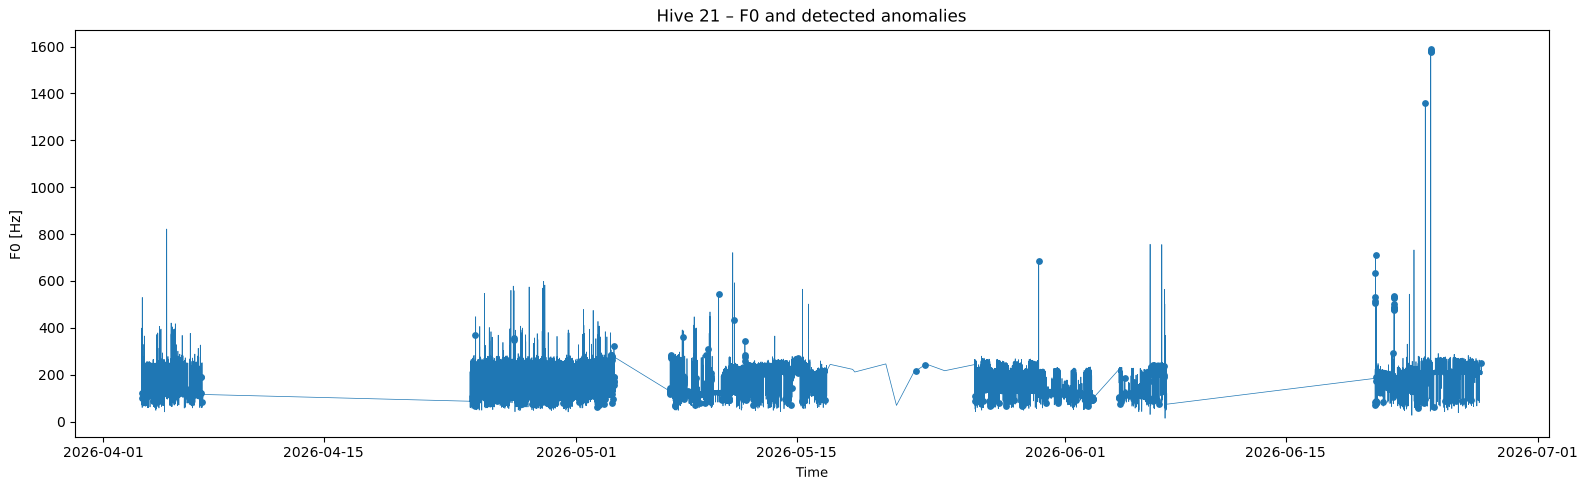

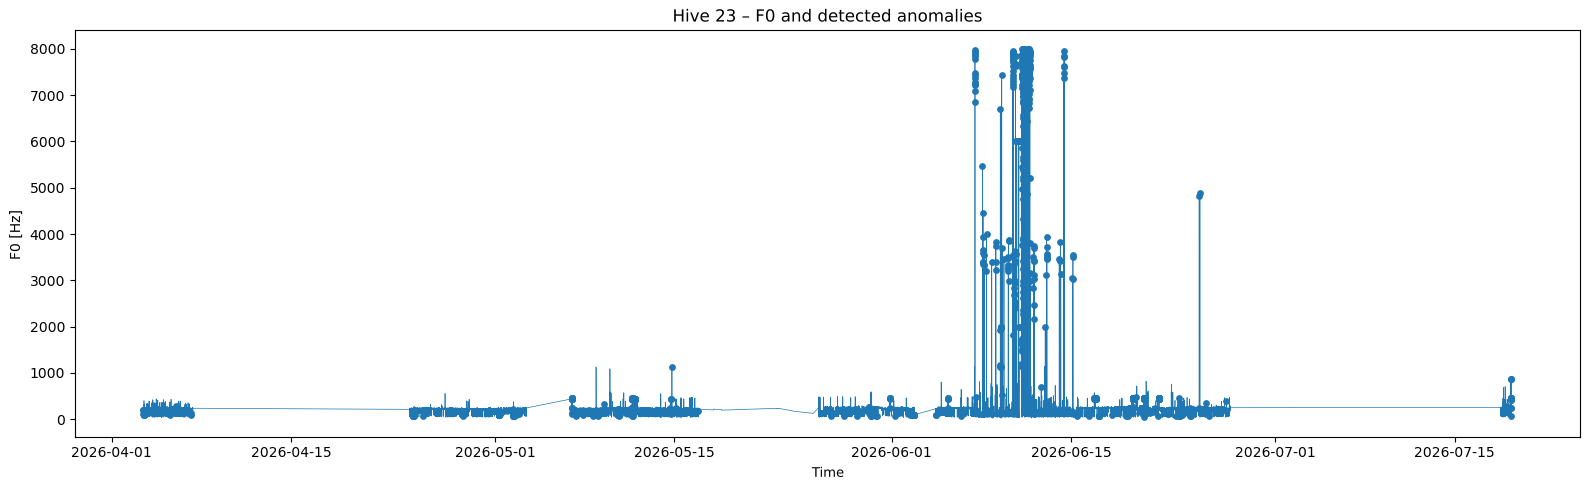

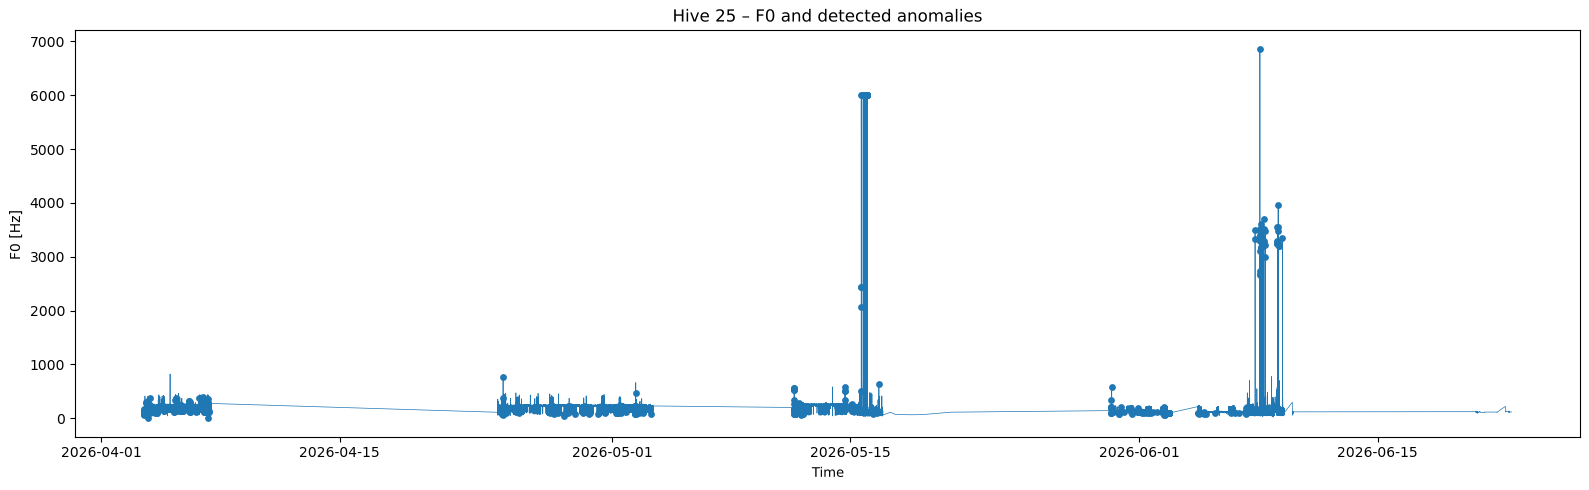

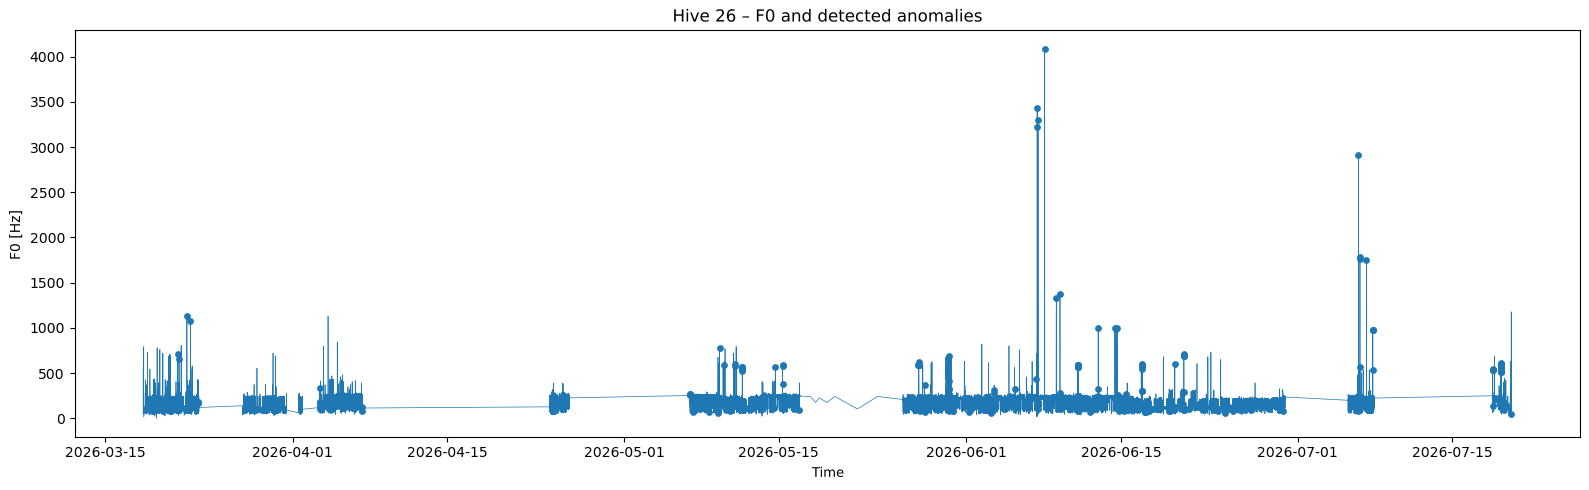

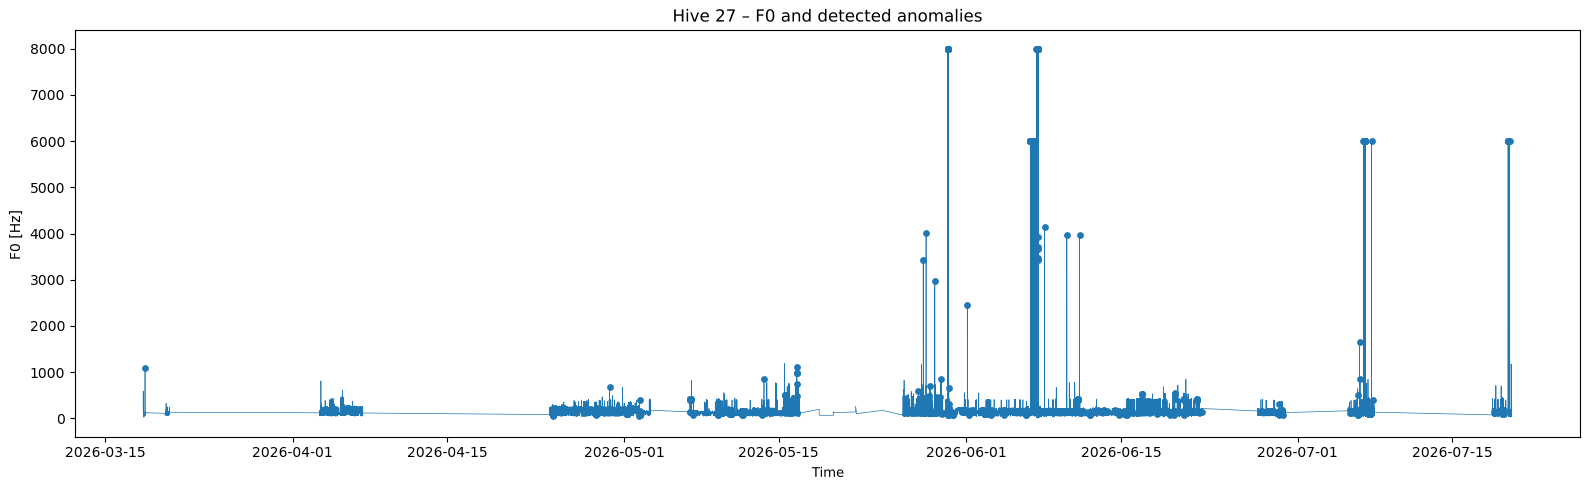

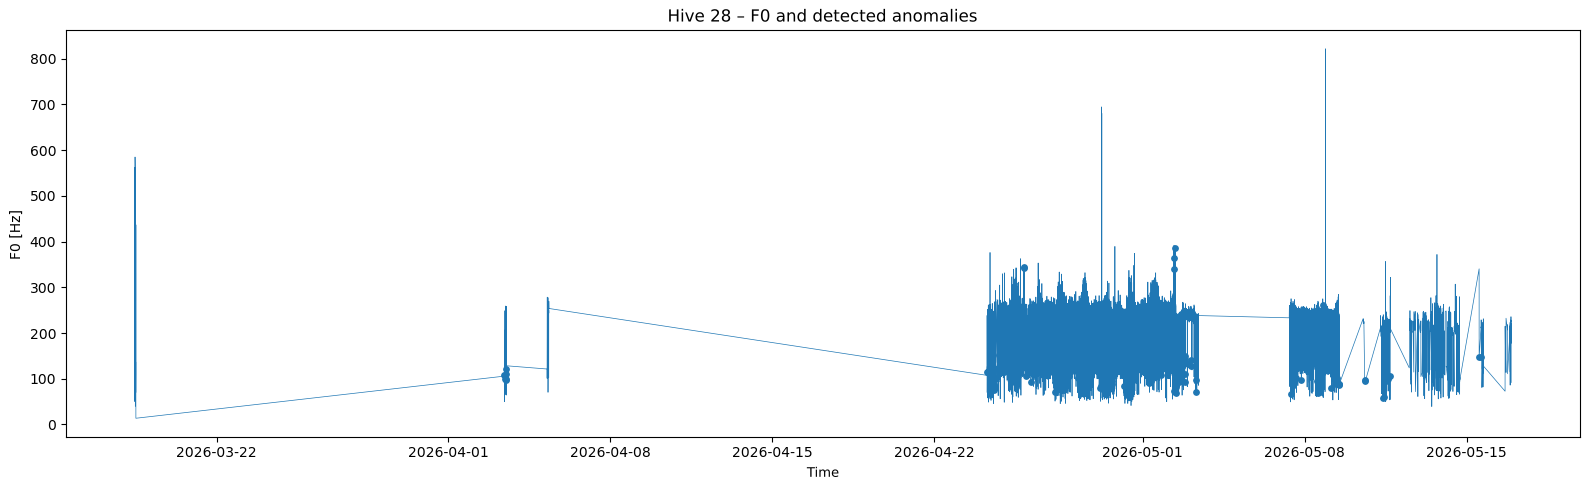

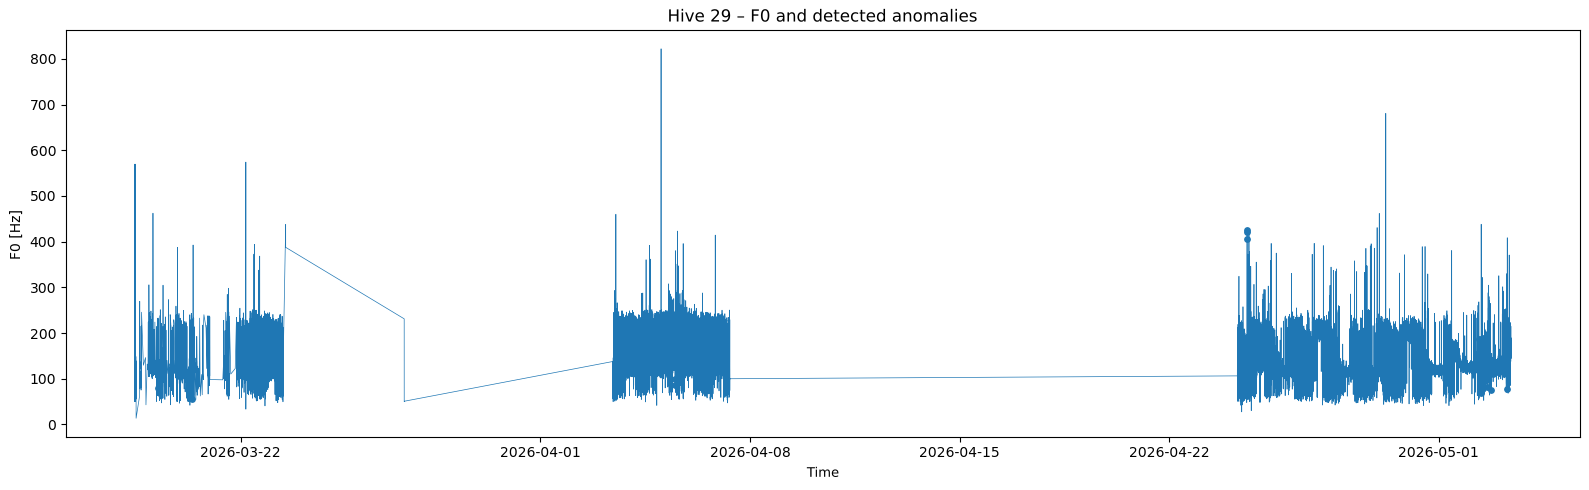

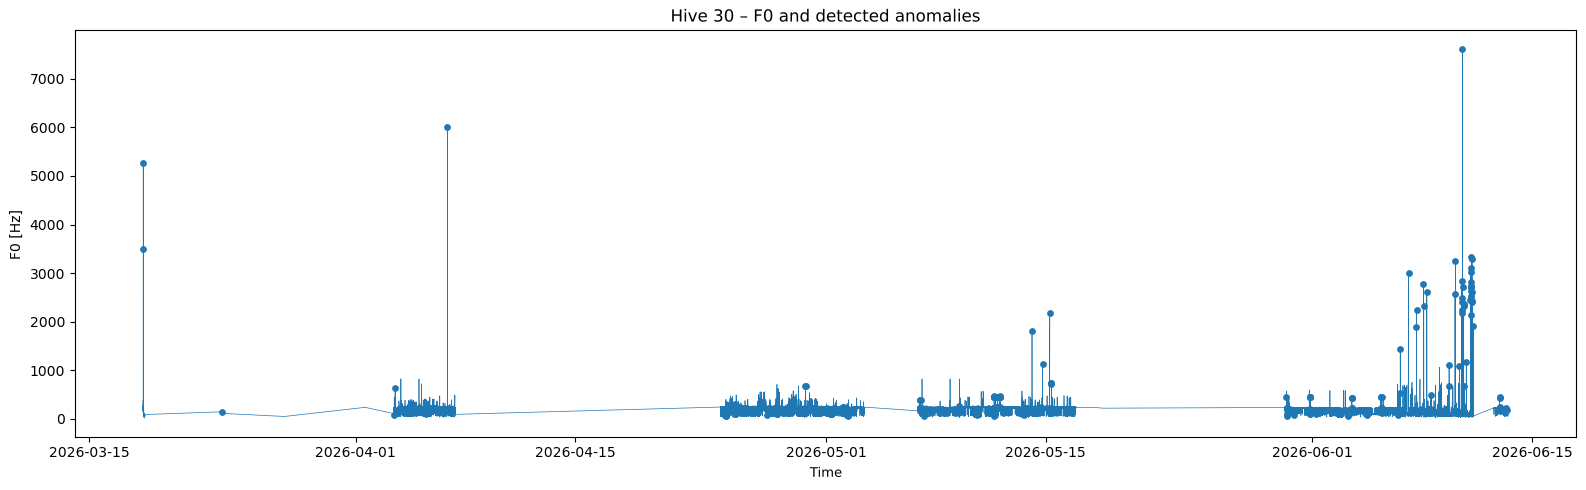

In [36]:
for hive in sorted(audio["Hive"].unique()):

    hive_data = audio[audio["Hive"] == hive].sort_values("timestamp_audio")

    plt.figure(figsize=(16, 5))

    plt.plot(
        hive_data["timestamp_audio"],
        hive_data["f0_hz"],
        linewidth=0.5
    )

    anomalies_hive = hive_data[hive_data["anomaly_candidate"]]

    plt.scatter(
        anomalies_hive["timestamp_audio"],
        anomalies_hive["f0_hz"],
        s=15
    )

    plt.title(f"Hive {hive} – F0 and detected anomalies")
    plt.xlabel("Time")
    plt.ylabel("F0 [Hz]")
    plt.tight_layout()
    plt.show()

## Grouping anomalies

In [37]:
anomalies = (
    audio[audio["anomaly_candidate"]]
    .copy()
    .sort_values(["Hive", "timestamp_audio"])
)

anomalies["time_diff"] = (
    anomalies
    .groupby("Hive")["timestamp_audio"]
    .diff()
    .dt.total_seconds()
    / 60
)

anomalies["event"] = (
    anomalies["time_diff"].isna()
    | (anomalies["time_diff"] > 5)
)

anomalies["event_id"] = (
    anomalies
    .groupby("Hive")["event"]
    .cumsum()
)

events = (
    anomalies
    .groupby(["Hive", "event_id"])
    .agg(
        start=("timestamp_audio", "min"),
        end=("timestamp_audio", "max"),
        recordings=("filename", "count"),
        rms_mean=("rms", "mean"),
        rms_max=("rms", "max"),
        f0_mean=("f0_hz", "mean"),
        f0_min=("f0_hz", "min"),
        f0_max=("f0_hz", "max")
    )
    .reset_index()
)

events["duration_min"] = (
    events["end"] - events["start"]
).dt.total_seconds() / 60

events = events.sort_values(
    ["Hive", "start"]
)

display(events)

,Hive,event_id,start,end,recordings,rms_mean,rms_max,f0_mean,f0_min,f0_max,duration_min
0,21,1,2026-04-03 11:44:00,2026-04-03 11:49:00,2,0.154296,0.184515,110.883833,100.999437,120.768229,5.0
1,21,2,2026-04-04 04:06:00,2026-04-04 04:06:00,1,0.074318,0.074318,86.046007,86.046007,86.046007,0.0
2,21,3,2026-04-04 05:40:00,2026-04-04 05:40:00,1,0.130223,0.130223,99.108574,99.108574,99.108574,0.0
3,21,4,2026-04-05 12:32:00,2026-04-05 12:36:00,2,0.132570,0.141969,186.497246,166.397270,206.597222,4.0
4,21,5,2026-04-05 14:09:00,2026-04-05 14:09:00,1,0.139021,0.139021,127.289871,127.289871,127.289871,0.0
...,...,...,...,...,...,...,...,...,...,...,...
1503,30,129,2026-06-11 04:26:00,2026-06-11 04:26:00,1,0.014523,0.014523,3291.571392,3291.571392,3291.571392,0.0
1504,30,130,2026-06-11 06:16:00,2026-06-11 06:16:00,1,0.010753,0.010753,1917.430933,1917.430933,1917.430933,0.0
1505,30,131,2026-06-12 22:30:00,2026-06-12 22:37:00,8,0.119476,0.220140,266.280576,155.354818,441.319444,7.0
1506,30,132,2026-06-13 08:48:00,2026-06-13 08:48:00,1,0.106655,0.106655,216.866135,216.866135,216.866135,0.0


### Summary for each hive

In [38]:
event_summary = (

    events

    .groupby("Hive")

    .agg(

        events=("event_id", "count"),

        recordings_mean=("recordings", "mean"),

        recordings_max=("recordings", "max"),

        rms_mean=("rms_mean", "mean"),

        rms_max=("rms_max", "max"),

        f0_mean=("f0_mean", "mean"),

        f0_min=("f0_min", "mean"),

        f0_max=("f0_max", "mean"),

        duration_mean=("duration_min", "mean"),

        duration_max=("duration_min", "max")

    )

    .round(3)

)


display(event_summary)

,events,recordings_mean,recordings_max,rms_mean,rms_max,f0_mean,f0_min,f0_max,duration_mean,duration_max
Hive,,,,,,,,,,
21,280,2.832,39,0.120,0.706,156.008,145.874,168.665,2.561,51.0
23,239,4.636,232,0.090,0.667,1715.619,1512.703,1836.748,4.778,273.0
25,244,2.984,33,0.100,0.678,917.047,893.021,943.538,3.053,43.0
26,233,2.674,44,0.119,0.719,274.912,255.254,301.612,2.124,49.0
27,195,5.610,242,0.097,0.633,1573.154,1546.722,1621.319,6.087,249.0
28,159,2.755,33,0.108,0.596,143.613,135.811,151.488,2.623,41.0
29,25,2.120,9,0.118,0.565,109.383,96.198,120.432,2.320,25.0
30,133,3.128,30,0.102,0.735,720.704,664.431,793.550,2.752,31.0


### Longest event

In [ ]:
longest_events = (
    events
    .sort_values("duration_min", ascending=False)

)

display(
    longest_events[
        [
            "Hive",
            "event_id",
            "start",
            "end",
            "recordings",
            "rms_mean",
            "rms_max",
            "f0_mean",
            "f0_min",
            "f0_max",
            "duration_min"
        ]
    ].head(50)
)

,Hive,event_id,start,end,recordings,rms_mean,rms_max,f0_mean,f0_min,f0_max,duration_min
421,23,142,2026-06-11 04:10:00,2026-06-11 08:43:00,232,0.002168,0.007815,6692.249909,1474.298007,8000.000000,273.0
1083,27,88,2026-06-06 23:25:00,2026-06-07 03:34:00,242,0.012052,0.016082,6000.000000,6000.000000,6000.000000,249.0
1082,27,87,2026-06-06 21:10:00,2026-06-06 23:17:00,110,0.012149,0.020838,6000.000000,6000.000000,6000.000000,127.0
1084,27,89,2026-06-07 03:40:00,2026-06-07 05:16:00,75,0.013541,0.016252,6000.000000,6000.000000,6000.000000,96.0
1081,27,86,2026-06-06 19:44:00,2026-06-06 21:04:00,60,0.011906,0.013580,6000.000000,6000.000000,6000.000000,80.0
1169,27,174,2026-07-07 01:06:00,2026-07-07 02:16:00,48,0.003180,0.003469,6000.000000,6000.000000,6000.000000,70.0
482,23,203,2026-06-21 21:05:00,2026-06-21 22:06:00,61,0.147521,0.240616,452.062559,437.018795,465.480940,61.0
435,23,156,2026-06-11 17:38:00,2026-06-11 18:36:00,39,0.023353,0.027769,7484.091679,3810.799320,8000.000000,58.0
49,21,50,2026-05-01 06:59:00,2026-05-01 07:50:00,39,0.357596,0.705848,94.529045,89.778646,96.860532,51.0
981,26,219,2026-07-07 11:49:00,2026-07-07 12:38:00,44,0.274307,0.559532,101.589184,86.547852,193.821709,49.0


### Strongest event by RMS

In [ ]:
strongest_events = (
    events
    .sort_values("rms_max", ascending=False)
)

display(
    strongest_events[
        [
            "Hive",
            "event_id",
            "start",
            "end",
            "recordings",
            "rms_mean",
            "rms_max",
            "f0_mean",
            "f0_min",
            "f0_max",
            "duration_min"
        ]
    ].head(50)
)

,Hive,event_id,start,end,recordings,rms_mean,rms_max,f0_mean,f0_min,f0_max,duration_min
1438,30,64,2026-05-11 17:32:00,2026-05-11 17:45:00,13,0.371129,0.735358,204.940447,168.554688,224.218750,13.0
871,26,109,2026-06-02 17:52:00,2026-06-02 18:11:00,20,0.361772,0.719460,95.092936,91.194969,97.222222,19.0
49,21,50,2026-05-01 06:59:00,2026-05-01 07:50:00,39,0.357596,0.705848,94.529045,89.778646,96.860532,51.0
612,25,94,2026-05-01 06:59:00,2026-05-01 07:42:00,33,0.330339,0.678161,94.306693,90.856481,96.571181,43.0
337,23,58,2026-05-11 17:34:00,2026-05-11 17:45:00,12,0.337296,0.666804,267.557549,154.474432,458.125000,11.0
1436,30,62,2026-05-11 16:54:00,2026-05-11 17:10:00,16,0.379238,0.644876,281.235511,86.896930,466.796875,16.0
1026,27,31,2026-05-11 17:34:00,2026-05-11 17:45:00,12,0.315743,0.632630,155.904417,149.197049,163.814484,11.0
829,26,67,2026-05-10 15:46:00,2026-05-10 16:06:00,17,0.345692,0.619502,95.895118,91.933140,112.393466,20.0
1408,30,34,2026-05-01 06:59:00,2026-05-01 07:24:00,14,0.321148,0.616405,102.001084,90.786638,193.860176,25.0
466,23,187,2026-06-16 21:52:00,2026-06-16 22:03:00,9,0.307167,0.610352,453.481502,448.792614,458.309659,11.0


### Event with the highest F0

In [ ]:
highest_f0_events = (
    events
    .sort_values("f0_max", ascending=False)
)

display(
    highest_f0_events[
        [
            "Hive",
            "event_id",
            "start",
            "end",
            "recordings",
            "rms_mean",
            "rms_max",
            "f0_mean",
            "f0_min",
            "f0_max",
            "duration_min"
        ]
    ].head(50)
)

,Hive,event_id,start,end,recordings,rms_mean,rms_max,f0_mean,f0_min,f0_max,duration_min
1095,27,100,2026-06-07 09:59:00,2026-06-07 10:14:00,10,0.011431,0.015462,8000.000000,8000.000000,8000.000000,15.0
1100,27,105,2026-06-07 12:16:00,2026-06-07 12:24:00,6,0.010690,0.012980,8000.000000,8000.000000,8000.000000,8.0
1091,27,96,2026-06-07 08:56:00,2026-06-07 09:02:00,4,0.010753,0.014879,8000.000000,8000.000000,8000.000000,6.0
1094,27,99,2026-06-07 09:30:00,2026-06-07 09:32:00,3,0.010509,0.012676,8000.000000,8000.000000,8000.000000,2.0
435,23,156,2026-06-11 17:38:00,2026-06-11 18:36:00,39,0.023353,0.027769,7484.091679,3810.799320,8000.000000,58.0
1089,27,94,2026-06-07 08:24:00,2026-06-07 08:24:00,1,0.023067,0.023067,8000.000000,8000.000000,8000.000000,0.0
1090,27,95,2026-06-07 08:32:00,2026-06-07 08:50:00,11,0.011332,0.020900,8000.000000,8000.000000,8000.000000,18.0
1096,27,101,2026-06-07 10:29:00,2026-06-07 10:30:00,2,0.008361,0.008661,8000.000000,8000.000000,8000.000000,1.0
1058,27,63,2026-05-30 07:58:00,2026-05-30 08:07:00,6,0.012475,0.013661,8000.000000,8000.000000,8000.000000,9.0
1055,27,60,2026-05-30 07:19:00,2026-05-30 07:19:00,1,0.012668,0.012668,8000.000000,8000.000000,8000.000000,0.0


In [45]:
events["f0_saturated_6000"] = (
    (events["f0_min"] == 6000) &
    (events["f0_max"] == 6000)
)

events["f0_saturated_8000"] = (
    events["f0_max"] >= 7900
)

In [46]:
saturation_summary = (
    events
    .groupby("Hive")
    [["f0_saturated_6000", "f0_saturated_8000"]]
    .sum()
)

saturation_summary

,f0_saturated_6000,f0_saturated_8000
Hive,,
21,0,0
23,1,11
25,9,0
26,0,0
27,6,14
28,0,0
29,0,0
30,1,0


In [47]:
saturation_summary = (
    events
    .groupby("Hive")
    .agg(
        events=("event_id", "count"),
        saturated_6000=("f0_saturated_6000", "sum"),
        saturated_8000=("f0_saturated_8000", "sum")
    )
)

saturation_summary["pct_6000"] = (
    saturation_summary["saturated_6000"]
    / saturation_summary["events"] * 100
)

saturation_summary["pct_8000"] = (
    saturation_summary["saturated_8000"]
    / saturation_summary["events"] * 100
)

saturation_summary

,events,saturated_6000,saturated_8000,pct_6000,pct_8000
Hive,,,,,
21,280,0,0,0.000000,0.000000
23,239,1,11,0.418410,4.602510
25,244,9,0,3.688525,0.000000
26,233,0,0,0.000000,0.000000
27,195,6,14,3.076923,7.179487
28,159,0,0,0.000000,0.000000
29,25,0,0,0.000000,0.000000
30,133,1,0,0.751880,0.000000


In [133]:
tqdm.pandas(desc="Marking F0 artifacts")

In [134]:
events["f0_artifact_0"] = (events["f0_min"] <= 0) | (events["f0_mean"] <= 0)
events["f0_saturated_6000"] = (events["f0_min"] == 6000) & (events["f0_max"] == 6000)
events["f0_saturated_8000"] = events["f0_max"] >= 7900

In [135]:
events["is_f0_artifact"] = (
    events["f0_artifact_0"] | 
    events["f0_saturated_6000"] | 
    events["f0_saturated_8000"]
)

In [136]:
events_valid_f0 = events[
    (events["f0_min"] > 0) & 
    (events["f0_mean"] < 5900) & 
    (events["f0_max"] < 7900)
].copy()

print(len(events))
print(len(events_valid_f0))

1508
1418


In [172]:
if "audio_features" not in globals():
    raise RuntimeError(
        "First run the cell that creates audio_features "
        "from the Hive*_audio_features.csv files."
    )

anomaly_data = audio_features.copy()
anomaly_data["timestamp_audio"] = pd.to_datetime(
    anomaly_data["timestamp_audio"], errors="coerce"
)

for column in ["rms", "f0_hz"]:
    anomaly_data[column] = pd.to_numeric(
        anomaly_data[column], errors="coerce"
    )

anomaly_data = anomaly_data.dropna(
    subset=["Hive", "timestamp_audio", "rms", "f0_hz"]
).sort_values(["Hive", "timestamp_audio"]).copy()

anomaly_data["f0_artifact"] = (
    (anomaly_data["f0_hz"] <= 0)
    | (anomaly_data["f0_hz"] >= 7900)
)

for feature, zscore_name in [("rms", "rms_zscore"), ("f0_hz", "f0_zscore")]:
    group = anomaly_data.groupby("Hive")[feature]
    median = group.transform("median")
    mad = group.transform(
        lambda values: (values - values.median()).abs().median()
    )
    scale = 1.4826 * mad
    fallback = group.transform("std").replace(0, np.nan)
    scale = scale.where(scale > 0, fallback)

    anomaly_data[zscore_name] = (
        (anomaly_data[feature] - median) / scale
    ).replace([np.inf, -np.inf], np.nan).fillna(0)

anomaly_data["anomaly_score"] = anomaly_data[
    ["rms_zscore", "f0_zscore"]
].abs().max(axis=1)

valid_scores = anomaly_data.loc[
    ~anomaly_data["f0_artifact"]
].copy()
share_limit = 0.01
score_thresholds = valid_scores.groupby("Hive")["anomaly_score"].transform(
    lambda values: values.quantile(1 - share_limit)
)
valid_scores["score_threshold"] = score_thresholds
valid_scores["anomaly_candidate"] = (
    valid_scores["anomaly_score"] >= valid_scores["score_threshold"]
)

anomaly_data["score_threshold"] = np.nan
anomaly_data.loc[valid_scores.index, "score_threshold"] = (
    valid_scores["score_threshold"]
)
anomaly_data["anomaly_candidate"] = False
anomaly_data.loc[valid_scores.index, "anomaly_candidate"] = (
    valid_scores["anomaly_candidate"]
)

threshold_table = pd.DataFrame({
    "threshold": [3, 3.5, 4, 4.5, 5],
    "recordings": [
        (valid_scores["anomaly_score"] >= threshold).sum()
        for threshold in [3, 3.5, 4, 4.5, 5]
    ]
})
threshold_table["percent"] = (
    threshold_table["recordings"] / len(valid_scores) * 100
).round(3)
display(threshold_table)

anomalies_final = anomaly_data[
    anomaly_data["anomaly_candidate"]
].copy()
anomalies_final["gap_min"] = (
    anomalies_final.groupby("Hive")["timestamp_audio"]
    .diff().dt.total_seconds().div(60)
)
anomalies_final["new_event"] = (
    anomalies_final["gap_min"].isna()
    | (anomalies_final["gap_min"] > 5)
)
anomalies_final["event_id"] = (
    anomalies_final.groupby("Hive")["new_event"].cumsum()
)

events_final = (
    anomalies_final.groupby(["Hive", "event_id"], as_index=False)
    .agg(
        start=("timestamp_audio", "min"),
        end=("timestamp_audio", "max"),
        recordings=("filename", "count"),
        rms_mean=("rms", "mean"),
        rms_max=("rms", "max"),
        f0_mean=("f0_hz", "mean"),
        f0_min=("f0_hz", "min"),
        f0_max=("f0_hz", "max"),
        max_anomaly_score=("anomaly_score", "max")
    )
)
events_final["duration_min"] = (
    events_final["end"] - events_final["start"]
).dt.total_seconds().div(60)

event_summary_final = (
    events_final.groupby("Hive", as_index=False)
    .agg(
        events=("event_id", "count"),
        anomaly_recordings=("recordings", "sum"),
        longest_event_min=("duration_min", "max"),
        mean_rms=("rms_mean", "mean"),
        mean_f0=("f0_mean", "mean")
    )
    .sort_values("events", ascending=False)
)

print(f"Number of analysed recordings: {len(anomaly_data)}")
print(f"Number of f0 artifacts: {anomaly_data['f0_artifact'].sum()}")
print(f"Share of top scores per hive: {share_limit:.1%}")
print(f"Number of anomalous recordings: {len(anomalies_final)}")
print(f"Number of events: {len(events_final)}")

display(events_final.sort_values(["Hive", "start"]))
display(event_summary_final)

,threshold,recordings,percent
0,3.0,40870,9.233
1,3.5,28428,6.422
2,4.0,18672,4.218
3,4.5,14410,3.255
4,5.0,10429,2.356


Number of analysed recordings: 442774
Number of f0 artifacts: 106
Share of top scores per hive: 1.0%
Number of anomalous recordings: 4431
Number of events: 1245


,Hive,event_id,start,end,recordings,rms_mean,rms_max,f0_mean,f0_min,f0_max,max_anomaly_score,duration_min
0,21,1,2026-04-03 11:44:00,2026-04-03 11:49:00,2,0.154296,0.184515,110.883833,100.999437,120.768229,11.250897,5.0
1,21,2,2026-04-03 12:06:00,2026-04-03 12:06:00,1,0.103646,0.103646,103.627874,103.627874,103.627874,4.973483,0.0
2,21,3,2026-04-04 05:40:00,2026-04-04 05:40:00,1,0.130223,0.130223,99.108574,99.108574,99.108574,7.036459,0.0
3,21,4,2026-04-05 00:45:00,2026-04-05 00:45:00,1,0.017924,0.017924,821.661086,821.661086,821.661086,7.417389,0.0
4,21,5,2026-04-05 12:32:00,2026-04-05 12:36:00,2,0.132570,0.141969,186.497246,166.397270,206.597222,7.948263,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...
1240,30,180,2026-06-11 04:26:00,2026-06-11 04:26:00,1,0.014523,0.014523,3291.571392,3291.571392,3291.571392,90.376396,0.0
1241,30,181,2026-06-11 06:16:00,2026-06-11 06:16:00,1,0.010753,0.010753,1917.430933,1917.430933,1917.430933,49.923562,0.0
1242,30,182,2026-06-12 22:31:00,2026-06-12 22:36:00,6,0.132823,0.220140,245.001979,155.354818,441.319444,27.835119,5.0
1243,30,183,2026-06-13 08:48:00,2026-06-13 08:48:00,1,0.106655,0.106655,216.866135,216.866135,216.866135,12.229149,0.0


,Hive,events,anomaly_recordings,longest_event_min,mean_rms,mean_f0
3,26,357,931,53.0,0.099632,304.186875
0,21,197,580,54.0,0.139060,170.411198
7,30,184,514,42.0,0.079401,690.460562
2,25,132,388,43.0,0.115851,1559.048024
4,27,114,833,249.0,0.115903,1696.123784
1,23,98,782,572.0,0.085711,3838.712062
5,28,88,180,43.0,0.132350,159.738325
6,29,75,223,77.0,0.072333,208.613256


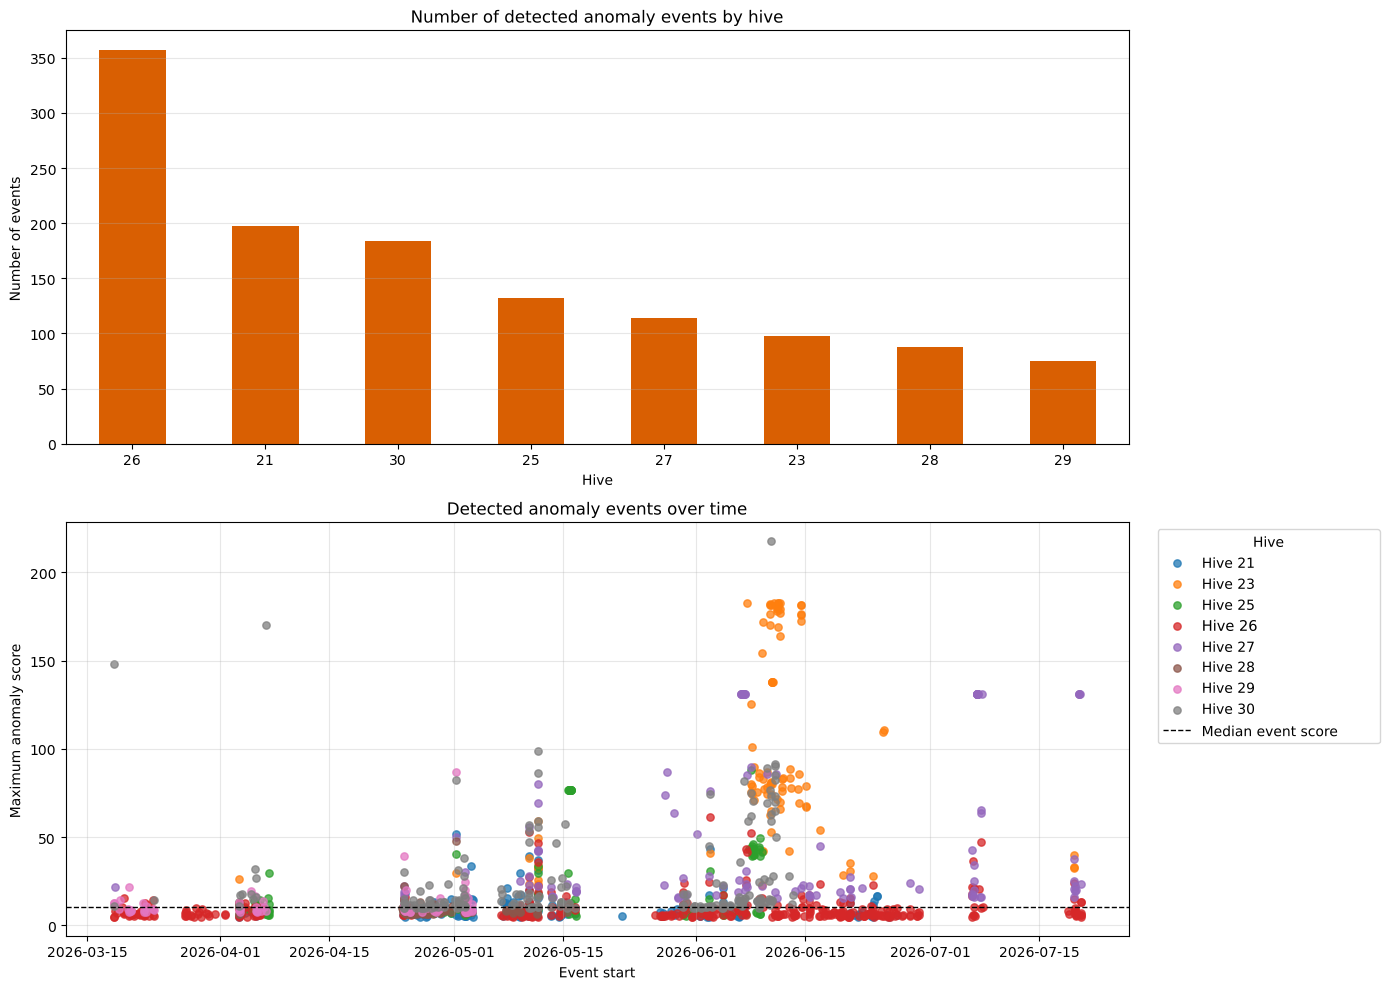

In [173]:
if events_final.empty:
    print("No events to visualise.")
else:
    figure, axes = plt.subplots(2, 1, figsize=(14, 10))
    event_counts = (
        events_final.groupby("Hive")
        .size()
        .sort_values(ascending=False)
    )
    event_counts.plot(kind="bar", ax=axes[0], color="#d95f02")
    axes[0].set_title("Number of detected anomaly events by hive")
    axes[0].set_xlabel("Hive")
    axes[0].set_ylabel("Number of events")
    axes[0].tick_params(axis="x", rotation=0)
    axes[0].grid(axis="y", alpha=0.3)

    for hive, hive_events in events_final.groupby("Hive"):
        axes[1].scatter(
            hive_events["start"],
            hive_events["max_anomaly_score"],
            s=28,
            alpha=0.75,
            label=f"Hive {hive}"
        )

    axes[1].axhline(
        events_final["max_anomaly_score"].median(),
        color="black",
        linestyle="--",
        linewidth=1,
        label="Median event score"
    )
    axes[1].set_title("Detected anomaly events over time")
    axes[1].set_xlabel("Event start")
    axes[1].set_ylabel("Maximum anomaly score")
    axes[1].grid(alpha=0.3)
    axes[1].legend(title="Hive", bbox_to_anchor=(1.02, 1), loc="upper left")
    figure.tight_layout()
    plt.show()

,Hive,start,end,recordings,duration_min,rms_max,f0_max,max_anomaly_score
1228,30,2026-06-10 13:34:00,2026-06-10 13:38:00,3,4.0,0.025349,7615.088223,217.654873
259,23,2026-06-11 13:34:00,2026-06-11 13:43:00,5,9.0,0.053157,7892.591977,182.679005
250,23,2026-06-10 23:11:00,2026-06-11 08:43:00,465,572.0,0.088596,7891.076743,182.642938
209,23,2026-06-07 11:46:00,2026-06-07 11:59:00,11,13.0,0.003394,7885.156250,182.502014
255,23,2026-06-11 12:12:00,2026-06-11 12:46:00,22,34.0,0.062774,7884.369894,182.483296
261,23,2026-06-11 17:38:00,2026-06-11 18:34:00,33,56.0,0.027769,7879.388503,182.364725
234,23,2026-06-10 11:46:00,2026-06-10 11:47:00,2,1.0,0.023404,7864.721853,182.015619
231,23,2026-06-10 10:51:00,2026-06-10 11:08:00,10,17.0,0.027230,7852.419970,181.722800
243,23,2026-06-10 16:11:00,2026-06-10 16:17:00,3,6.0,0.025621,7852.113381,181.715502
281,23,2026-06-14 11:52:00,2026-06-14 11:52:00,1,0.0,0.018089,7849.313447,181.648856


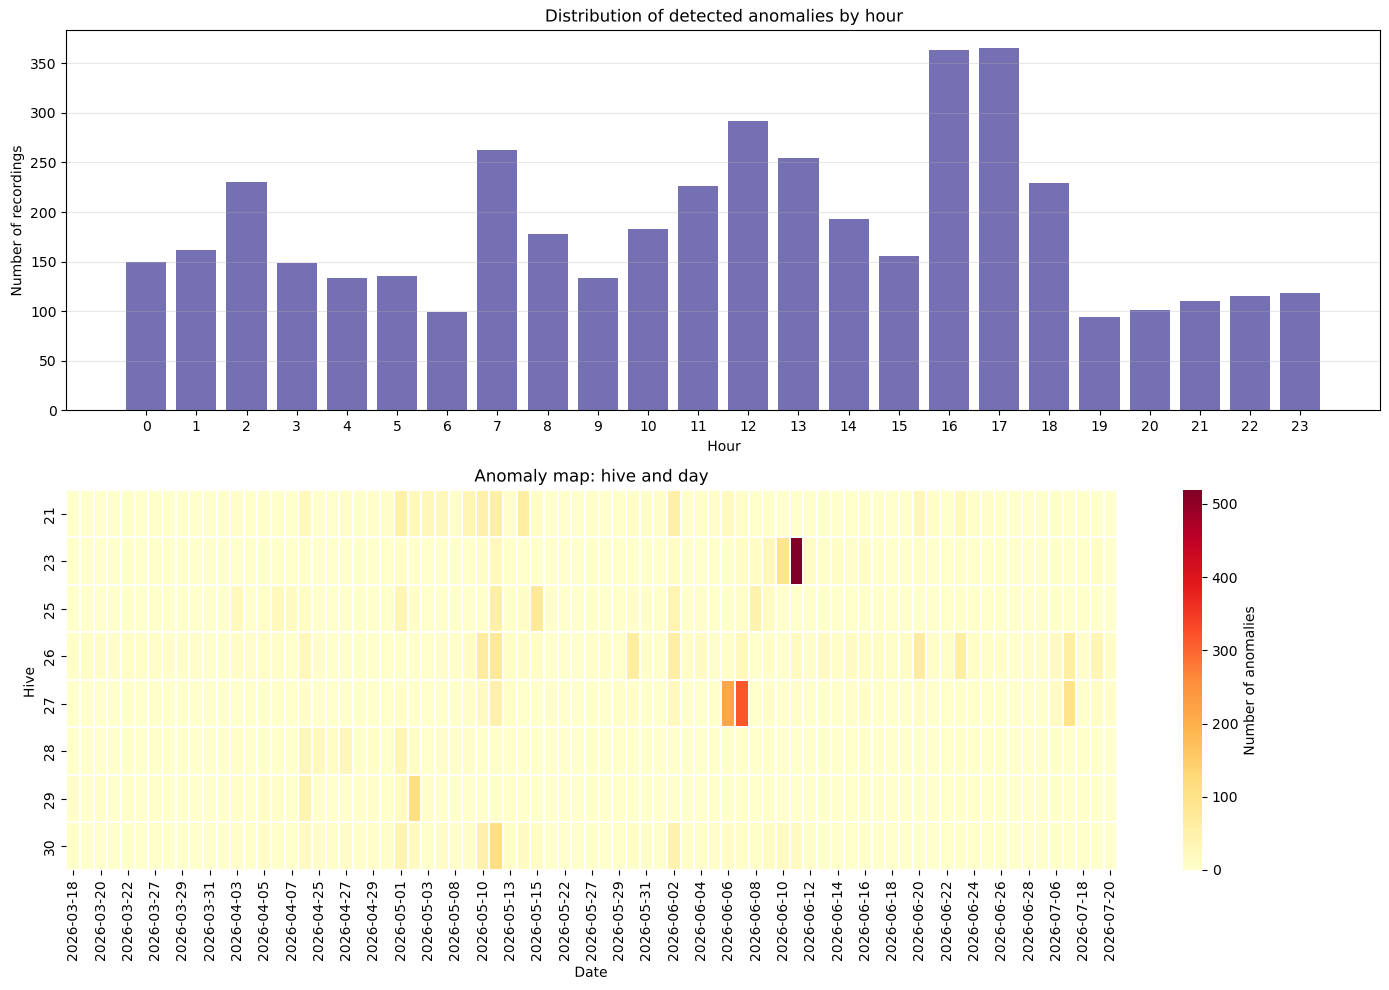

In [174]:
if events_final.empty:
    print("No events for further analysis.")
else:
    top_events = events_final.sort_values(
        "max_anomaly_score", ascending=False
    ).head(20)
    display(
        top_events[
            [
                "Hive", "start", "end", "recordings",
                "duration_min", "rms_max", "f0_max",
                "max_anomaly_score"
            ]
        ]
    )

    anomalies_by_hour_final = (
        anomalies_final.groupby(anomalies_final["timestamp_audio"].dt.hour)
        .size()
        .reindex(range(24), fill_value=0)
    )
    anomalies_by_day_hive = (
        anomalies_final.assign(
            date=anomalies_final["timestamp_audio"].dt.date
        )
        .groupby(["date", "Hive"])
        .size()
        .unstack(fill_value=0)
    )

    figure, axes = plt.subplots(2, 1, figsize=(14, 10))
    axes[0].bar(
        anomalies_by_hour_final.index,
        anomalies_by_hour_final.values,
        color="#7570b3"
    )
    axes[0].set_title("Distribution of detected anomalies by hour")
    axes[0].set_xlabel("Hour")
    axes[0].set_ylabel("Number of recordings")
    axes[0].set_xticks(range(24))
    axes[0].grid(axis="y", alpha=0.3)

    sns.heatmap(
        anomalies_by_day_hive.T,
        cmap="YlOrRd",
        linewidths=0.2,
        ax=axes[1],
        cbar_kws={"label": "Number of anomalies"}
    )
    axes[1].set_title("Anomaly map: hive and day")
    axes[1].set_xlabel("Date")
    axes[1].set_ylabel("Hive")
    figure.tight_layout()
    plt.show()

    events_final.to_csv(
        "data/events_anomalies.csv",
        index=False
    )
    event_summary_final.to_csv(
        "data/event_summary_anomalies.csv",
        index=False
    )